<a href="https://colab.research.google.com/github/maggiemcc02/MaggiesDPhil/blob/main/code/C1Localisation/Biharmonic_FirstC1Localisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction

In this notebook, we construct and test the first implementation of our $C^1$ localisation within Pablo's `GoalAdaptiveNonlinearVariationalSolver`. Throughout, we use a 1D manufactured clamped biharmonic problem as our test problem.

## Summary:

1. We first test the strong enforcement of boundary conditions for the 1D biharmonic problem (Hermite elements).
2. We then look at each local problem separately, using a manufactured solutions approach. Something interesting came up here ....
3. We then alter Pablo's old code with these three local problems (along with some other needed modifications).
4. Finally, we test the resulting solver on a manufactured 1D biharmonic problem. We compare the results with the refinement scheme and with uniform refinement. These results seem promising? (take a look)

# Imports and Checks

In [1]:
# install firedrake - complex mode!!

# hide output
%%capture


try:
    import firedrake
except ImportError:
    # Download and run the pre-built complex build script from FEM on Colab
    !wget "https://fem-on-colab.github.io/releases/firedrake-install-release-complex.sh" -O "/tmp/firedrake-install.sh" && bash "/tmp/firedrake-install.sh"
    import firedrake

In [2]:
# hide output
%%capture
%pip install ngsPETSc

In [3]:
# Making sure I have degree 4 hermite!

import FIAT
from finat.ufl import elementlist
from firedrake import *

# Check whether FIAT includes higher-order Hermite
if not hasattr(FIAT, "Hermite"):
    raise RuntimeError(
        "FIAT is too old. Install a newer Firedrake build."
    )

# Remove FInAT's outdated upper degree restriction.
# This is only intended for 1D Hermite elements.
metadata = elementlist.ufl_elements["Hermite"]


# Change degree range (3,3) to (3, None) as needed to use FIAT's degree 4 hermite.
updated = (
    metadata[:5]
    + ((3, None),)
    + metadata[6:]
)

elementlist.ufl_elements["Hermite"] = updated
elementlist.ufl_elements["HER"] = updated

# Test
mesh = UnitIntervalMesh(8)

V = FunctionSpace(mesh, "Hermite", 3)
V_enriched = FunctionSpace(mesh, "Hermite", 4)

print("Primal DOFs:", V.dim())
print("Enriched DOFs:", V_enriched.dim())

u = TrialFunction(V_enriched)
v = TestFunction(V_enriched)

A = assemble(
    inner(u.dx(0).dx(0), v.dx(0).dx(0)) * dx
)

print("Degree-4 biharmonic assembly successful!")


Primal DOFs: 18
Enriched DOFs: 26
Degree-4 biharmonic assembly successful!


In [4]:

from firedrake import *

mesh = UnitIntervalMesh(8)
DG0 = FunctionSpace(mesh, "DG", 0)

markers = Function(DG0)
markers.assign(0)
markers.dat.data[3] = 1

print("Before:", mesh.cell_set.size, "cells")

new_mesh = mesh.refine_marked_elements(markers)

print("After: ", new_mesh.cell_set.size, "cells")


Before: 8 cells
After:  9 cells


# Manufactured Biharmonic Problem

First thing we want to check is whether we can strongly enforce the clamped boundary conditions for a 1D biharmonic problem, discretised with Hermite elements.

The problem of interest is
$$ u^{''''} = f \,\, \text{ on } (0, 1), \text{ with } u(0)=u(1)=u'(0)=u'(1)=0,$$
where we pick
$$ u(x) = x^2(1-x)^2(1+10x^3).$$

To strongly enforce the boundary conditions, we use


```
    # Strongly enforce u = u' = 0 at x = 0, 1
    bc = DirichletBC(V, 0, "on_boundary")
    # Include derivative DOFs, which standard DirichletBC skips (chats suggestion)
    bc.nodes = V.boundary_nodes("on_boundary")
```
When we use Hermite elements, Firedrake sets
```
bcnodes = bcnodes[::2]  # every second dof is the vertex value
```
We do not want this. So, instead, we set

```
bc.nodes = V.boundary_nodes("on_boundary")
```
which returns all of the boundary DOFs. Then, since we set zero Dirichlet condiions everywhere on the boundary, we have set $u$ and $u'$ equal to zero on the boundary.







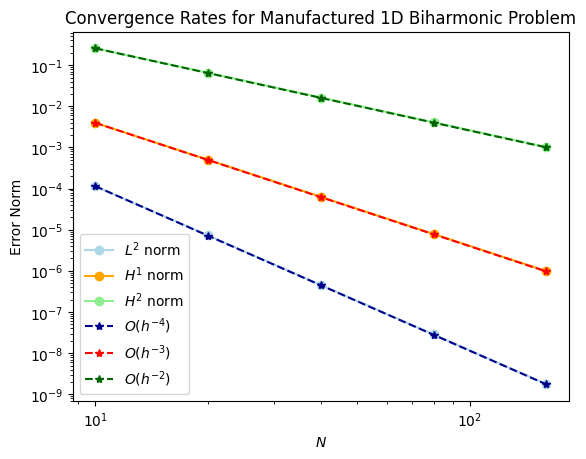

In [5]:
from firedrake import *
from finat.ufl import BrokenElement, FiniteElement
from ufl import replace


# ============================================================
# 1. MANUFACTURED BIHARMONIC PROBLEM in 1D
# ============================================================

def lap(w):
    return div(grad(w))


def biharm_1D(N):

    mesh = UnitIntervalMesh(N)

    # Exact manufactured solution
    x = SpatialCoordinate(mesh)[0]
    u_exact = x**2 * (1 - x)**2 * (1 + 10*x**3)
    f = 8400*x**3 - 7200*x**2 + 1200*x + 24

    # Solve for uh
    V = FunctionSpace(mesh, "Hermite", 3)

    u = TrialFunction(V)
    v = TestFunction(V)

    # a = inner(u.dx(0).dx(0), v.dx(0).dx(0)) * dx
    a = inner(lap(u), lap(v))*dx
    L = inner(f, v) * dx

    # Strongly enforce u = u' = 0 at x = 0, 1
    bc = DirichletBC(V, 0, "on_boundary")
    # Include derivative DOFs, which standard DirichletBC skips (chats suggestion)
    bc.nodes = V.boundary_nodes("on_boundary")


    uh = Function(V)
    solve(a == L, uh, bcs=[bc])

    # Check the errors
    e = uh - u_exact
    # L2 norm
    L2_error = norm(e).real
    H1_error = norm(e, 'H1').real
    H2_semi = norm(grad(grad(e)), "L2").real
    H2_error = sqrt(H1_error**2 + H2_semi**2)

    return L2_error, H1_error, H2_error



# ============================================================
# 2. Convergence Tests
# ============================================================

mesh_sizes = [10, 20, 40, 80, 160]
L2_errors = []
H1_errors = []
H2_errors = []

for N in mesh_sizes:

    L2_error, H1_error, H2_error = biharm_1D(N)
    L2_errors.append(L2_error)
    H1_errors.append(H1_error)
    H2_errors.append(H2_error)


# Plot
import matplotlib.pyplot as plt
# Reference curves
L2ref = [L2_errors[0] * (mesh_sizes[0] / N)**4 for N in mesh_sizes]
H1ref = [H1_errors[0] * (mesh_sizes[0] / N)**3 for N in mesh_sizes]
H2ref = [H2_errors[0] * (mesh_sizes[0] / N)**2 for N in mesh_sizes]


plt.loglog(mesh_sizes, L2_errors, '-o', color = 'lightblue', label=r"$L^2$ norm")
plt.loglog(mesh_sizes, H1_errors, '-o', color = 'orange',label=r"$H^1$ norm")
plt.loglog(mesh_sizes, H2_errors, '-o', color = 'lightgreen', label=r"$H^2$ norm")
plt.loglog(mesh_sizes, L2ref, '--*', color = 'darkblue', label = r'$O(h^{-4})$')
plt.loglog(mesh_sizes, H1ref, '--*', color = 'red', label = r'$O(h^{-3})$')
plt.loglog(mesh_sizes, H2ref, '--*', color = 'darkgreen',label = r'$O(h^{-2})$')
plt.legend()
plt.xlabel(r"$N$")
plt.ylabel("Error Norm")
plt.title('Convergence Rates for Manufactured 1D Biharmonic Problem')
plt.show()

## First Manufactured Test

Continuing with this example, we will solve a 1D manufactured solution biharmonic problem and test the three local residual problems one at a time.

### 1. The Problem and its Residual

In [38]:
# ============================================================
# 0. HELPERS
# ============================================================

def residual(F, test):
    (old_test,) = F.arguments()
    return replace(F, {old_test: test})

def both(expr):
    return expr("+") + expr("-")


def lap(w):
    return div(grad(w))

direct = {
    "ksp_type": "gmres",
    "ksp_monitor_true_residual": None,
    "pc_factor_mat_solver_type": "mumps",
    "pc_type": "svd"
}






# ============================================================
# 1. MANUFACTURED BIHARMONIC PROBLEM in 1D
# ============================================================

N = 5
mesh = UnitIntervalMesh(N)

# Exact manufactured solution
x = SpatialCoordinate(mesh)[0]
u_exact = x**2 * (1 - x)**2 * (1 + 10*x**3)
f = 8400*x**3 - 7200*x**2 + 1200*x + 24

# Solve for uh
V = FunctionSpace(mesh, "Hermite", 3)

u = TrialFunction(V)
v = TestFunction(V)

a = inner(u.dx(0).dx(0), v.dx(0).dx(0)) * dx
L = inner(f, v) * dx

# Strongly enforce u = u' = 0 at x = 0, 1
bc = DirichletBC(V, 0, "on_boundary")
# Include derivative DOFs, which standard DirichletBC skips (chats suggestion)
bc.nodes = V.boundary_nodes("on_boundary")

uh = Function(V)
solve(a == L, uh, bcs=[bc], solver_parameters=direct)


# ============================================================
# 2. DEFINE THE RESIDUAL FUNCTIONAL
# ============================================================

n = FacetNormal(mesh)

F = (inner(lap(uh), lap(v))*dx - inner(f, v)*dx)

# Exact local strong residuals for F = a - L
Rcell_exact = lap(lap(uh)) - f # should be -f
Rfacet1_exact = lap(uh)
Rfacet0_exact = -dot(grad(lap(uh)), n)

    Residual norms for firedrake_96_ solve.
    0 KSP preconditioned resid norm 3.160914840738e-01 true resid norm 1.514367670019e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP preconditioned resid norm 2.228142134690e-16 true resid norm 2.456115461190e-13 ||r(i)||/||b|| 1.621875261744e-15


### 2. First Local Problem: Cell Residual

In [42]:
# ============================================================
# 3. FIRST LOCAL PROBLEM: CELL RESIDUAL
# ============================================================

# Setup
dim = mesh.topological_dimension
cell = mesh.ufl_cell()
variant = "integral"
degree = V.ufl_element().degree()
cell_residual_degree = degree + 1
facet_residual_degree = degree + 1

# Cell bubbles
B = FunctionSpace(mesh, "B", dim+1, variant=variant)
bubbles = Function(B).assign(1)

# Now we want bubbles^2!!
bubble_sq = bubbles**2

# Might need to change for mixed spaces!!
# DG space on cell interiors
if V.value_shape == ():
    DG = FunctionSpace(mesh, "DG", cell_residual_degree, variant=variant)
else:
    DG = TensorFunctionSpace(mesh, "DG", cell_residual_degree, variant=variant, shape=V.value_shape)


# Might need problem on each subspace of a mixed space
uc = TrialFunction(DG)
vc = TestFunction(DG)

# Accounting for bubbles^2
ac = inner(uc, bubble_sq*vc)*dx

# SHOWING CANCELLATION ERRORS
Lc = residual(F, bubble_sq*vc)
#Lc = inner(lap(lap(uh)) - f, bubble_sq*vc)*dx


# solve for Rcell
Rcell = Function(DG)
solve(ac == Lc, Rcell, solver_parameters=direct)


# Error check
cell_error = norm(Rcell-Rcell_exact).real
print("\n===== CELL RESIDUAL =====")
print("||Rcell - (Delta^2 uh - f)||_L2 =", cell_error)

    Residual norms for firedrake_101_ solve.
    0 KSP preconditioned resid norm 1.573175133289e+03 true resid norm 5.242782441103e+01 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP preconditioned resid norm 1.581171824758e-12 true resid norm 5.270500824473e-14 ||r(i)||/||b|| 1.005286960442e-15

===== CELL RESIDUAL =====
||Rcell - (Delta^2 uh - f)||_L2 = 1.4675611576932427e-10


In [37]:
x = SpatialCoordinate(mesh)[0]
vc_specific = x**4
Lc_weak = assemble(residual(F, bubble_sq*vc_specific))
Lc_strong = assemble(inner(lap(lap(uh)) - f, bubble_sq*vc_specific)*dx)
print(Lc_weak)
print(Lc_strong)
print(abs(Lc_weak - Lc_strong))

(-33.93125906125848+8.228921253950848e-15j)
(-33.93125906107233+8.310761560036373e-15j)
1.8614798591444904e-10


### 3. Second Local Problem : First Facet Bubble

In [43]:
# ============================================================
# 4. FACET BUBBLE SPACE
# ============================================================


# Dissertation Code:
# # 1D substitution: FacetBubble does not exist on intervals; facets are
# # points, so broken P1 (one dof per cell endpoint) plays the facet-
# # bubble role and the cones are identically one
# cones = Function(FunctionSpace(mesh, "CG", 1)).assign(1)
# Q = MixedFunctionSpace(
#     [FunctionSpace(mesh, BrokenElement(FiniteElement("Lagrange", cell=cell, degree=1))) for Vi in V.subspaces])
# Qtest, Qtrial = TestFunction(Q), TrialFunction(Q)
# Lf = residual(F, Qtest) - inner(Rcell, Qtest)*dx
# facet_mass = mixed_weighted_inner(Qtrial, Qtest, 1/cones, first_arg=True)
# af = both(facet_mass) * dS + facet_mass * ds
# Rhat = Function(Q)
# # Compute facet residuals (broken P1, one dof per cell endpoint)
# solve(af == Lf, Rhat, solver_parameters=options.sp_facet)



# General Code:
# Facet bubbles
# FB = FunctionSpace(mesh, "FB", dim, variant=variant)
# cones = Function(FB).assign(1)

# Broken facet bubble space
# Might need to change for mixed spaces!!
# el = BrokenElement(FiniteElement("FB", cell=cell, degree=facet_residual_degree+dim, variant=variant))
# if V.value_shape == ():
#     Q = FunctionSpace(mesh, el)
# else:
#     Q = TensorFunctionSpace(mesh, el, shape=V.value_shape)







# 1D Changes : FacetBubble does not exist on intervals; facets are
# points, so broken P1 (one dof per cell endpoint) plays the facet-
# bubble role and the cones are identically one
cones = Function(FunctionSpace(mesh, "CG", 1)).assign(1)
Q = FunctionSpace(mesh, BrokenElement(FiniteElement("Lagrange", cell=cell, degree=1)))
Qtest = TestFunction(Q)

# Our special edge bubble (Carstensen)
v = -bubbles * Qtest
n = FacetNormal(mesh)
dn_v = dot(grad(v), n)

# Trial function
Qtrial = TrialFunction(Q)
Lf = residual(F, v) - inner(Rcell, v)*dx
af = both(inner(Qtrial/cones, dn_v))*dS + inner(Qtrial/cones, dn_v)*ds


# solve for Rfacet1
Rhat1 = Function(Q)
solve(af == Lf, Rhat1, solver_parameters=direct)
Rfacet1 = Rhat1/cones


# Error check


def facet_norm(expr):
    # Include both cell sides of interior facets
    return sqrt(abs(assemble(
        both(inner(expr, expr))*dS
        + inner(expr, expr)*ds
    )))


facet1_error = facet_norm(Rfacet1-Rfacet1_exact)
print("\n===== NORMAL-DERIVATIVE FACET RESIDUAL =====")
print("||Rfacet1 - Delta uh||_facets =", facet1_error)



# Checking error accumulation impact


# Trial function
Qtrial = TrialFunction(Q)
Lf = residual(F, v) - inner(Rcell_exact, v)*dx
af = both(inner(Qtrial/cones, dn_v))*dS + inner(Qtrial/cones, dn_v)*ds


# solve for Rfacet1
Rhat1 = Function(Q)
solve(af == Lf, Rhat1, solver_parameters=direct)
Rfacet1_noaccum = Rhat1/cones


# Error check

facet1_error = facet_norm(Rfacet1_noaccum-Rfacet1_exact)
print("\n===== NORMAL-DERIVATIVE FACET RESIDUAL, no error accumulation =====")
print("||Rfacet1 - Delta uh||_facets =", facet1_error)

    Residual norms for firedrake_102_ solve.
    0 KSP preconditioned resid norm 2.104908530839e+01 true resid norm 2.232592643901e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP preconditioned resid norm 2.961040764438e-15 true resid norm 3.548270007670e-14 ||r(i)||/||b|| 1.589304711436e-16

===== NORMAL-DERIVATIVE FACET RESIDUAL =====
||Rfacet1 - Delta uh||_facets = 1.2076628189666124e-13
    Residual norms for firedrake_103_ solve.
    0 KSP preconditioned resid norm 2.104908530839e+01 true resid norm 2.232592643901e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP preconditioned resid norm 3.004844199040e-15 true resid norm 3.601232189381e-14 ||r(i)||/||b|| 1.613026988698e-16

===== NORMAL-DERIVATIVE FACET RESIDUAL, no error accumulation =====
||Rfacet1 - Delta uh||_facets = 1.7038577965105435e-14


### 4. Third Local Problem: Second Facet Bubble

In [44]:
# ============================================================
# 6. THIRD LOCAL PROBLEM
# ============================================================


# Test and Trial functions
Qtest = TestFunction(Q)
Qtrial = TrialFunction(Q)
v = cones * Qtest
n = FacetNormal(mesh)
dn_v = dot(grad(v), n)


# Remove cell and already reconstructed derivative-facet terms
Lf = (
    residual(F, v)
    - inner(Rcell, v)*dx
    - both(inner(Rfacet1, dn_v))*dS
    - inner(Rfacet1, dn_v)*ds
)

# Reconstruct the polynomial value-facet residual
af = (
    both(inner(Qtrial/cones, v))*dS
    + inner(Qtrial/cones, v)*ds
)

Rhat = Function(Q)
solve(af == Lf, Rhat,
      solver_parameters=direct)

Rfacet0 = Rhat/cones


# Erro:

facet0_error = facet_norm(Rfacet0-Rfacet0_exact)

print("\n===== VALUE FACET RESIDUAL =====")
print("||Rfacet0 + dn(Delta uh)||_facets =", facet0_error)


# Compare when no error accumulation:


# Remove cell and already reconstructed derivative-facet terms
Lf = (
    residual(F, v)
    - inner(Rcell_exact, v)*dx
    - both(inner(Rfacet1_exact, dn_v))*dS
    - inner(Rfacet1_exact, dn_v)*ds
)

# Reconstruct the polynomial value-facet residual
af = (
    both(inner(Qtrial/cones, v))*dS
    + inner(Qtrial/cones, v)*ds
)

Rhat = Function(Q)
solve(af == Lf, Rhat,
      solver_parameters=direct)

Rfacet0_noaccum = Rhat/cones


# Error:

facet0_error = facet_norm(Rfacet0_noaccum -Rfacet0_exact)

print("\n===== VALUE FACET RESIDUAL, No Error Accumulation =====")
print("||Rfacet0 + dn(Delta uh)||_facets =", facet0_error)

    Residual norms for firedrake_104_ solve.
    0 KSP preconditioned resid norm 1.908047274886e+02 true resid norm 1.908047274886e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP preconditioned resid norm 0.000000000000e+00 true resid norm 2.887647188841e-14 ||r(i)||/||b|| 1.513404424958e-16

===== VALUE FACET RESIDUAL =====
||Rfacet0 + dn(Delta uh)||_facets = 1.9878788587894576e-11
    Residual norms for firedrake_105_ solve.
    0 KSP preconditioned resid norm 1.908047274886e+02 true resid norm 1.908047274886e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP preconditioned resid norm 3.116352017083e-14 true resid norm 3.768221900841e-15 ||r(i)||/||b|| 1.974910134795e-17

===== VALUE FACET RESIDUAL, No Error Accumulation =====
||Rfacet0 + dn(Delta uh)||_facets = 3.098457231678326e-14


### 5. Local Error Indicators

In [45]:
# ============================================================
# 8. ERROR INDICATORS (PRIMAL)
# ============================================================

DG0 = FunctionSpace(mesh, "DG", degree=0)
test = TestFunction(DG0)
n = FacetNormal(mesh)


# Only for the manufactured self-dual problem
# where the exact dual solution is u_exact (typically we use an enriched solve)
# and the discrete dual solution is uh.
z_err = u_exact - uh
# Normal derivative of the dual error
dn_z_err = dot(grad(z_err), n)


# Residual contributions
cell_term = inner(Rcell, z_err)
facet_value_term = inner(Rfacet0, z_err)
facet_normal_term = inner(Rfacet1, dn_z_err)


# Signed cellwise error contributions
eta_primal = assemble(
    inner(cell_term, test)*dx
    + inner(avg(facet_value_term + facet_normal_term),both(test)) * dS
    + inner((facet_value_term + facet_normal_term), test) * ds)


with eta_primal.dat.vec_ro as evec:
    signed_sum = evec.sum()



# Comparisons
# Note:
# In my definition of F,
# F(v) = a(uh, v) - L(v) = a(uh-u, v) = - a(e, v)
# Thus, J(e) = a(u, e*) = -F(e*)
###
# We want signed_sum = F(e*) = -J(e)


F_direct = assemble(residual(F, z_err))
F_uh = assemble(residual(F, uh))
goal_error = assemble(inner(u_exact - uh, f)*dx)

# Check that signed sum = F(e*)
print("Signed sum, approximates F(z_err):", signed_sum)
print("Direct F(z_err):                  ", F_direct)
print("Localisation discrepancy:         ",
      abs(signed_sum - F_direct))
# Check that J(e) = -F(e*) - F(uh) = -signed_sum - F(uh)
print("DWR contribution:                 ", -signed_sum) # signed_sum is opposite sign of J(e)
print("F(uh), ideally zero:              ", F_uh) #  should be zero.
print("Including discrete residual:      ", -signed_sum - F_uh) # account for possible discretisation errors
print("Actual goal error:                ", goal_error) # if we dont assume galerkin orthogonality, J(e) = -F(e*)-F(uh)

Signed sum, approximates F(z_err): (-0.9377236291601803+9.172394595612459e-20j)
Direct F(z_err):                   (-0.9377236291601977+0j)
Localisation discrepancy:          1.7430501486856295e-14
DWR contribution:                  (0.9377236291601803-9.172394595612459e-20j)
F(uh), ideally zero:               (3.774758283725532e-14+0j)
Including discrete residual:       (0.9377236291601425-9.172394595612459e-20j)
Actual goal error:                 (0.9377236291601596+0j)


# My Version of Pablo's Code ($C^1$ Localisation)


Alterations I Made:

- Changed from the two local problems for $C^0$ problems, to the three local problems for $C^1$ problems.

- Added in the texttt{dim==1} localisation procedure (instead of FB space, use DG1).

- Updated some of the outdated adaptivity tools (AdaptiveTransferManager to TransferManager and AdaptiveMeshHierarchy to MeshHierarchy).

- Added in some special biharmonic tools (do not need to solve dual problem, properly enforce the boundary conditions)

- Importantly, I added in the dual=primal combined error indicator for the complex case (conjugate). This will be useful for the transition to my hermitian eigenproblems.

- I had to take out the .interpolate(uh) initial guess for the enriched solve, because interpolation is sketchy for Hermite?

- I added in some complex-Firedrake functionality.

In [11]:
# Trying to update Pablo's code myself


import numbers
import numpy as np
from dataclasses import dataclass
from typing import ClassVar

from petsctools import OptionsManager

from firedrake import warning

from firedrake.assemble import assemble
from firedrake import split
from firedrake.petsc import PETSc
from firedrake.function import Function
from firedrake.functionspace import FunctionSpace, TensorFunctionSpace, MixedFunctionSpace
from firedrake.ufl_expr import TestFunction, TrialFunction, derivative, action, adjoint
from firedrake.variational_solver import (NonlinearVariationalProblem, NonlinearVariationalSolver,
                                          LinearVariationalProblem, LinearVariationalSolver)
from firedrake import FacetNormal, grad, dot, as_vector
# from firedrake import AdaptiveMeshHierarchy, AdaptiveTransferManager
# from firedrake import MeshHierarchy, AdaptiveTransferManager # MAGGIE CHANGE
from firedrake import MeshHierarchy, TransferManager
from firedrake.solving import solve
from firedrake.output import VTKFile
from firedrake.logging import RED, BLUE, GREEN
from firedrake import Constant

from firedrake.preconditioners.pmg import PMGPC
from firedrake.mg.utils import get_level
# SHIM (U.Z.): stock Firedrake does not export `refine` from mg.ufl_utils yet;
# it is only reached on the mesh-adaptation path, which 1D interval meshes
# never enter (netgen has no 1D meshes).  Everything else is verbatim from
# https://github.com/maggiemcc02/firedrake/blob/mccarthy/goal-adaptive-eigensolver/firedrake/outerloop_adaptivefoldedeigensolver.py
try:
    from firedrake.mg.ufl_utils import refine
except ImportError:
    def refine(*args, **kwargs):
        raise NotImplementedError("mesh-adaptation path requires Maggie's Firedrake branch")
from firedrake.utils import RealType
#from firedrake.mg.adaptive_hierarchy import AdaptiveMeshHierarchy
#from firedrake.mg.adaptive_transfer_manager import AdaptiveTransferManager

from finat.ufl import BrokenElement, FiniteElement
from ufl import avg, dx, ds, dS, inner, replace
import ufl



# Earlier stuff but add in eigensolver
__all__ = ["GoalAdaptiveSolverBase",
           "SteadyGoalAdaptiveSolver",
           "GoalAdaptiveNonlinearVariationalSolver",
           "vtk_output_callback",]
           #"GoalAdaptiveFoldedEigensolver"]


# Pablo's new initialization

# Notes on how it compares to the old:
# Adds in a tolerance
# max_iterations (old) now max_it (new)
# no longer given an output_dir or run_name for saving output to a specific location (maybe this is elsewhere)
# Old code claims that use_adjoint_residual, primal_old_method, dual_old_method are not used by the eigensolver class
# New code uses @dataclass(frozen=True) to generate the constructor. The old code had a constructor (init)
# Solver parameters for cell and facet solves are the same choices

@dataclass(frozen=True)
class GoalAdaptiveOptions:
    """Options for goal-adaptive solvers.

    Parameters
    ----------
    tolerance
        Terminate the adaptive loop when ``|eta_h| < tolerance``.
    max_it
        Maximum number of SOLVE–ESTIMATE–MARK–REFINE cycles.  The loop also
        terminates early if the error estimate falls below the requested tolerance.
        Defaults to ``10``.
    max_dofs
        Maximum number of dofs we will allows the meshes to have. This will
        avoid long adaptive loops.
    dorfler_alpha
        Threshold parameter for Dörfler (bulk) marking: cells whose local error
        indicator exceeds ``dorfler_alpha * max_indicator`` are marked for
        refinement.  Must lie in ``(0, 1]``.  Larger values mark fewer cells and
        produce more targeted (but potentially slower-converging) refinement.
        Defaults to ``0.5``.
    primal_extra_degree
        Extra polynomial degree used when solving the primal problem in an
        enriched space (only relevant when ``use_adjoint_residual=True``).
        The enriched-space degree is ``degree + primal_extra_degree``.
        Defaults to ``1``.
    dual_extra_degree
        Extra polynomial degree used when solving the dual (adjoint) problem
        in an enriched space.  The enriched-space degree is
        ``degree + dual_extra_degree``.  Defaults to ``1``.
    cell_residual_extra_degree
        Extra polynomial degree for the DG space used to represent cell
        residuals during error indicator computation.  The DG space degree is
        ``degree + cell_residual_extra_degree``.  Defaults to ``1``.
    facet_residual_extra_degree
        Extra polynomial degree for the broken facet-bubble space used to
        represent facet residuals during error indicator computation.
        The space degree is ``degree + facet_residual_extra_degree``.
        Defaults to ``1``.
    use_adjoint_residual
        If ``True``, both the primal residual
        :math:`\\rho(u_h; z - z_h)` and the adjoint residual
        :math:`\\rho^*(z_h; u - u_h)` are used to form the error estimate
        :math:`\\frac{1}{2}(\\rho + \\rho^*)`, which gives a remainder term
        that is cubic in the errors z - z_h and u - u_h.
        This requires four PDE solves per iteration (primal and dual each at two degrees).
        If ``False`` (the default), only the primal residual is used, requiring
        only two PDE solves per iteration (primal at degree :math:`p` and dual
        at degree :math:`p + \\text{dual\\_extra\\_degree}`). This means
        that the remainder term is instead quadratic in the errors
        z - z_h and u - u_h.
        Defaults to ``False``.
    primal_low_method
        How to obtain the low-degree primal solution when
        ``use_adjoint_residual=True``.  Options:

        * ``"interpolate"`` (default) – nodally interpolate the enriched-space
          solution into the base space.
        * ``"project"`` – :math:`L^2`-project the enriched-space solution into
          the base space.
        * ``"solve"`` – solve the primal problem independently in the base
          space; the enriched-space solution is used only for the error estimate.

    dual_low_method
        How to obtain the low-degree dual solution used in the error estimate.
        Options:

        * ``"interpolate"`` (default) – nodally interpolate the enriched-space
          dual solution into the base space.
        * ``"project"`` – :math:`L^2`-project the enriched-space dual solution
          into the base space.
        * ``"solve"`` – solve the dual problem independently in the base space;
          this is the most expensive option but produces the most accurate solver-error
          estimate.

    verbose
        If ``True`` (the default), print progress information at each
        iteration via :func:`PETSc.Sys.Print`.
    """

    # dataclass will build the desired init with the below info?
    tolerance: float = 1e-4
    max_it: int = 10
    max_dofs: int | None = None
    dorfler_alpha: float = 0.5
    primal_extra_degree: int = 1
    dual_extra_degree: int = 1
    cell_residual_extra_degree: int = 1
    facet_residual_extra_degree: int = 1
    use_adjoint_residual: bool = False
    dual_is_primal: bool = False
    biharmonic_1D: bool = False
    primal_low_method: str = "interpolate"
    dual_low_method: str = "interpolate"
    verbose: bool = True

    # Solver parameters for cell/facet bubble projections
    # These are the same choices as in the old code (pre deletion of eigensolver)
    sp_cell: ClassVar[dict] = {
        "mat_type": "matfree",
        "snes_type": "ksponly",
        "ksp_type": "cg",
        "pc_type": "jacobi",
    }
    sp_facet: ClassVar[dict] = {
        "snes_type": "ksponly",
        "ksp_type": "cg",
        "pc_type": "jacobi",
    }





# The old code has special eigenoptions which we will need again
# We will use an updated form using Pablo's dataclass approach
# The extra options needed for an eigensolver
@dataclass(frozen=True)
class GoalAdaptiveEigenOptions(GoalAdaptiveOptions):
    """Options for :class:`GoalAdaptiveEigensolver`.

    Extends :class:`GoalAdaptiveOptions` with eigenproblem-specific options.

    Parameters
    ----------
    self_adjoint
        Whether the eigenproblem is self-adjoint. If ``True``, the dual
        eigenproblem agrees with the primal eigenproblem. Defaults to ``False``.

    nev
        Number of eigenpairs requested from each eigensolve. Defaults to ``5``.
        The solver constructs (via least squares problem) the
        eigenfunction in the span of the eigenbasis that is
        best correlated with the current eigenfunction estimate.
        This is done via :func:`match_best`.
        Defaults to ``5``.

    Notes
    -----
    The options ``use_adjoint_residual``, ``primal_low_method``, and
    ``dual_low_method`` inherited from :class:`GoalAdaptiveOptions` are not
    used by :class:`GoalAdaptiveEigensolver`.
    """

    # Allow the enriched spaces to be mixed spaces
    # and for the user to specify the degree addition for each subspace
    primal_extra_degree: tuple[int, ...] = (1,)
    dual_extra_degree: tuple[int, ...] = (1,)
    cell_residual_extra_degree: tuple[int, ...] = (1,)
    facet_residual_extra_degree: tuple[int, ...] = (1,)

    self_adjoint: bool = False
    nev: int = 5
    # mult_tol: float = 0.01 # Maggie addition - tolerance for computing cluster size.


# Pablo's new solver base:


class GoalAdaptiveSolverBase:
    """Base class for goal-adaptive solvers.

    Owns the SOLVE→ESTIMATE→MARK→REFINE loop and the Dörfler marking
    strategy.  Subclasses must implement :meth:`solve_and_estimate`,
    :meth:`compute_error_indicators`, and :meth:`refine_problem`.

    Parameters
    ----------
    goal_adaptive_options
        A ``GoalAdaptiveOptions`` instance, or a dict of keyword
        arguments to construct one.  Defaults to ``{}``.
    exact_goal
        Exact value of the goal functional (or eigenvalue).  Optional; used
        by subclasses to compute efficiency indices.
    """



    def __init__(self, base_mesh,
                 goal_adaptive_options: "GoalAdaptiveOptions | dict | None" = None,
                 exact_goal=None,
                 post_iteration_callback=None,
                 ):



        # Some noted changes from older code:
        # no seperate tolerance argument in this code. Now it is in self.options.tolerance
        # Stopping criteria is if abs(eta_h) < self.options.tolerance:
        # So use self.options.tolerance and not self.tolerance
        #
        # Also max_iterations is now self.options.max_it
        #
        # The new base needs the initial mesh because it now constructs and manages the adaptive mesh hierarchy itself. Thus, we need a base_mesh input
        # I should keep this in mind - my eigensolver constructor may need to pass the base mesh (most likely vis V.mesh())
        #
        # A big change is that in this new code, this base constructs the mesh hierarchy.
        # The old code has calls like AdaptiveMeshHierarchy(...) and AdaptiveTransferManager(...)
        # The new code base has amh = AdaptiveMeshHierarchy(mesh) and later calls self.amh = amh, self.base_levels = len(amh), self.atm = AdaptiveTransferManager()
        # So the eigensolver should not create amh or atm, it should inherit them
        #
        # The new base supports mesh sequences: meshes = {*base_mesh, base_mesh}
        # Thus, it can now support problems with a single mesh and problems made from several component meshes

        if goal_adaptive_options is None:
            goal_adaptive_options = {}
        self.options = self._make_options(goal_adaptive_options)
        self.goal_exact = exact_goal
        self.post_iteration_callback = post_iteration_callback

        self.Ndofs_vec: list[int] = []
        self.eta_vec: list[float] = []
        self.etah_vec: list[float] = []

        # Set up an AdaptiveMeshHierarchy for every mesh of the problem.
        # For a MeshSequenceGeometry, iterating over it yields the component meshes;
        # we also need a separate AMH for the sequence geometry itself.
        # meshes = {*base_mesh, base_mesh}  # component meshes + the sequence geometry (same object for a regular mesh)
        # for mesh in meshes:
        #     mh, level = get_level(mesh)
        #     if mh is None:
        #         amh = AdaptiveMeshHierarchy(mesh)
        #     else:
        #         amh = AdaptiveMeshHierarchy(mh[0])
        #         for m in mh[1:level+1]:
        #             amh.add_mesh(m)

        # MAGGIE CHANGE
        meshes = {*base_mesh, base_mesh}  # component meshes + the sequence geometry (same object for a regular mesh)
        for mesh in meshes:
            mh, level = get_level(mesh)
            if mh is None:
                amh = MeshHierarchy(mesh, 0)
            else:
                amh = MeshHierarchy(mh[0], 0)
                for m in mh[1:level+1]:
                    amh.add_mesh(m)

        amh, _ = get_level(base_mesh)
        self.amh = amh
        self.base_levels = len(amh)
        #self.atm = AdaptiveTransferManager()
        self.atm = TransferManager() # MAGGIE CHANGE



    # Old code assumed the options were in a dictionary
    # New code allows for as options object?
    # My eigensolver code should overwrite this to take the extra arguments (below)
    def _make_options(self, d):
        """Construct a ``GoalAdaptiveOptions`` from a dict or pass through as-is.  Override in subclasses."""
        if isinstance(d, GoalAdaptiveOptions):
            return d
        # FIXME
        return GoalAdaptiveOptions(**d["goal_adaptive"])


    # The new code adds the following, which returns the most recently stored predicted error estimate
    def get_error_estimate(self):
        return self.etah_vec[-1]

    # ------------------------------------------------------------------
    # Main loop
    # ------------------------------------------------------------------




    # Solve is the same as in the older code
    def solve(self):
        """Run the adaptive SOLVE→ESTIMATE→MARK→REFINE loop to convergence."""
        # Runs the standard loop for adaptivity where step() executes the steps of a given iteration
        for it in range(self.options.max_it):
            try:
                self.step(it=it)
            except StopIteration:
                break


    # 0. Maggie change - I seperated refinement criteria so I can overwrite it for the folded operator
    def should_refine(self, it, eta_h, eta):
        """ Return true when refinement is needed """
        return abs(eta_h) >= self.options.tolerance


    # Some changes since older code:
    # write_solution was replaced with a call back hook via post_iteration

    def step(self, it):
        """Execute one SOLVE→ESTIMATE→MARK→REFINE cycle.

        Parameters
        ----------
        it
            Current iteration index (mesh level).

        Raises
        ------
        StopIteration
            Raised (instead of returning) when the error estimate falls below
            ``tolerance`` or when ``it`` reaches ``max_it - 1``.
            :meth:`solve` catches this automatically; callers driving the loop
            manually with :meth:`step` must handle it themselves.
        """

        # One iteration of the adaptive loop!!!


        self.print()
        self.print(BLUE % f"---------------------------- [MESH LEVEL {it}] ----------------------------")
        self.print()


        # SOLVE + ESTIMATE
        self.eta_h, self.eta = self.solve_and_estimate() # defined in the subclass
        self.post_iteration(it) # user given actions


        # 1. Maggie change - stopping criteria moved outside
        # Pablo:
        # Stopping criteria
        # if abs(eta_h) < self.options.tolerance: # tolerance stopping criteria
        #     self.print("Error estimate below tolerance, finished.")
        #     raise StopIterations
        if not self.should_refine(it, self.eta_h, self.eta): # tolerance stopping criteria
            self.print("We have decided not to adapt - we are done!.")
            self.inner_converged = True
            self.termination_reason = "error_target_reached"
            raise StopIteration

        # RECENT CHANGE - MAX DOF
        # elif (self.options.max_dofs is not None and self.Ndofs_vec[-1] >= self.options.max_dofs):
        #     self.print(f"Maximum DOF limit ({self.options.max_dofs}) reached: "f"{self.Ndofs_vec[-1]} DOFs. Exiting.")
        #     self.inner_converged = False
        #     self.termination_reason = "max_dofs_reached"
        #     raise StopIteration


        elif it == self.options.max_it - 1: # max iter stopping criteria
            self.print(f"Maximum iteration ({self.options.max_it}) reached. Exiting.")
            self.inner_converged = False
            self.termination_reason = "max_it_reached"
            raise StopIteration



        # MARK
        self.print("Computing local refinement indicators eta_K ...")
        eta_cell = self.compute_error_indicators() # defined in the subclass - local indicators
        self.compute_efficiency_indices(eta_cell, self.eta_h, self.eta) # effectivity indices
        markers = self.set_adaptive_cell_markers(eta_cell) # call the marking routine - in base class
        marker_values = markers.dat.data_ro
        max_imag = float(np.max(np.abs(marker_values.imag))) # check size of imaginary part
        self.print(f"Maximum imaginary part of cell markers is: {max_imag:.3e}")
        if max_imag > 1e-12:
            raise ValueError(f"Cell markers have a nontrivial nonzero imaginary part: {max_imag:.3e}")
        else:
            self.print("Do not worry about the throwing out imaginary part warning to follow:")



        # REFINE
        self.print("Transferring problem to new mesh ...")
        self.refine_problem(markers) # refine the problem (base class)

        # CHECK MAX DOF:
        new_dof = self.problem.u.function_space().dim()
        if (self.options.max_dofs is not None and new_dof >= self.options.max_dofs):
            self.print(f"Maximum DOF limit ({self.options.max_dofs}) reached on refined mesh: "f"{new_dof} DOFs. Exiting.")
            self.inner_converged = False
            self.termination_reason = "max_dofs_reached"
            raise StopIteration


        # 2. Maggie change - Allow subclasses to transfer solutions/eigenfunctions.
        self.post_refinement()

    # Pretty much, after each iteration, this will run any user-supplied code.
    # For example, the user could want to save the solution, print output, save plots, etc
    def post_iteration(self, it : int):
        """Hook called after SOLVE+ESTIMATE, before convergence check.
           Invokes the user-supplied ``post_iteration_callback``, if any."""
        if self.post_iteration_callback is not None:
            self.post_iteration_callback(self, it)

    # Allow the subclasss to extend found solutions on coarser mesh to adapted mesh as initial guess
    # def post_refinement(self):
    #     """Hook called after SOLVE+ESTIMATE+MARK+REFINE.
    #     Invokes the subclass's ``post_refinement``, if any."""
    #     if self.post_refinement is not None:
    #         self.post_refinement(self)

    # MAGGIE CHANGE
    def post_refinement(self):
        """Optional hook for subclasses after refinement."""
        pass


    # ------------------------------------------------------------------
    # Common machinery (mark + refine + efficiency)
    # ------------------------------------------------------------------


    # note - maximum marking not dorfler marking!!!
    def set_adaptive_cell_markers(self, eta_cell):
        """Mark cells for refinement using Dörfler marking.

        Parameters
        ----------
        eta_cell
            Cell-wise error indicators (DG0 Function).

        Returns
        -------
        Function
            A DG0 Function with value 1 on cells selected for refinement.
        """
        # NOTE this is not quite Dorfler marking
        # For Dorfler marking we need to implement a parallel sort
        markers = Function(eta_cell.function_space())
        for m, e in zip(markers.subfunctions, eta_cell.subfunctions):
            with e.dat.vec_ro as evec:
                _, emax = evec.max()
            threshold = self.options.dorfler_alpha * emax
            m.dat.data_wo[e.dat.data_ro > threshold] = 1
        return markers


    # In the old code, this was implemented in subclasses not in this base class
    # Thus, every solver had to have its own refinement method
    # Thus, the new version of the eigensolver should inherit this
    # The question is whether refine(self.problem, ...) will know how to handle an eigenproblem - I think it does (bult in and in old code)

    def refine_problem(self, markers, coef_map=None):
        """Refine the mesh and reconstruct the problem on the new mesh.

        Parameters
        ----------
        markers
            DG0 Function with value 1 on cells to refine.
        """

        # Loop over markers
        for marker in markers.subfunctions:
            mesh = marker.function_space().mesh()
            # refine marked elements
            new_mesh = mesh.refine_marked_elements(marker)
            # add it to its repsective hierarchy
            amh, _ = get_level(mesh)
            amh.add_mesh(new_mesh)

        # Reconstruct MeshSequence with the refined meshes
        # Reconstruct the problem on the refined mesh
        mesh = self.amh[-1]
        if len(mesh) > 1:
            new_mesh = type(mesh)([get_level(m)[0][-1] for m in mesh])
            self.amh.add_mesh(new_mesh)
        if coef_map is None:
            coef_map = {}
        self.problem = refine(self.problem, refine, coefficient_mapping=coef_map)

        if self.options.biharmonic_1D:
          # Reapply your existing clamped-BC node treatment
          # using the NEW function space.
          for bc in self.problem.bcs:
              V_new = bc.function_space()
              bc.nodes = V_new.boundary_nodes("on_boundary")





    # Old code computed several diagnostics on the error
    # In particular, it computed eff1, eff2, and eff3 like in Joe's old code
    # This code leaves it up to the subclasses to decide what their measure of efficiency it
    # This means the generic base no longer assumes that all goal-adaptive solvers should measure efficiency in exactly the same way.

    def compute_efficiency_indices(self, eta_cell, eta_h, eta):
        """Hook called after marking.  Default no-op; override in subclasses."""
        pass


    # Same as before
    # Chat: This uses PETSc-aware printing. In parallel, it avoids every MPI process printing the same message.

    def print(self, *args, **kwargs):
        if self.options.verbose:
            PETSc.Sys.Print(*args, **kwargs)

    # ------------------------------------------------------------------
    # Abstract interface for subclasses
    # ------------------------------------------------------------------


    # Same as before - needs to be defined in the subclass

    def solve_and_estimate(self):
        """Solve the PDE(s) and compute a global error estimate.

        Must store any state needed by :meth:`compute_error_indicators`.

        Returns
        -------
        tuple[float, float | None]
            ``(eta_h, eta)`` where ``eta_h`` is the error estimate and ``eta``
            is the true error if an exact solution/goal was supplied, else
            ``None``.
        """
        raise NotImplementedError


    # Same as before - needs to be defined in the subclass

    def compute_error_indicators(self):
        """Compute cell-wise error indicators using stored solver state.

        Returns
        -------
        Function
            A DG0 Function of cell-wise indicators (absolute values).
        """
        raise NotImplementedError



# Not in the old code
# In the old code, the effectivity index computations were set in the base class
# Makes more sense to seperate out - not every problem has a scalar goal value

class SteadyGoalAdaptiveSolver(GoalAdaptiveSolverBase):
    """Intermediate base for steady-state goal-adaptive solvers.

    Adds the effectivity-index tracking that is specific to steady problems
    (where the notion of a scalar goal value and a true error make sense).
    The efficiency vectors are populated by :meth:`compute_efficiency_indices`,
    which is called automatically from :meth:`~GoalAdaptiveSolverBase.step`.

    Attributes
    ----------
    eta_cell_sum_vec : list[float]
        Sum of all cell indicators at each refinement level.
    eff1_vec : list[float]
        Effectivity index ``|eta_h / eta|`` at each level (only when
        ``exact_goal`` is provided).
    eff2_vec : list[float]
        Localisation efficiency ``|sum(eta_K) / eta|`` (only when
        ``exact_goal`` is provided).
    eff3_vec : list[float]
        Ratio ``sum(eta_K) / eta_h`` when no exact goal is available.
    """

    def __init__(self, base_mesh, goal_adaptive_options=None, exact_goal=None, post_iteration_callback=None):
        super().__init__(base_mesh, goal_adaptive_options, exact_goal, post_iteration_callback)
        self.eta_cell_sum_vec: list[float] = []
        self.eff1_vec: list[float] = []
        self.eff2_vec: list[float] = []
        self.eff3_vec: list[float] = []

    def compute_efficiency_indices(self, eta_cell, eta_h, eta):
        """Compute and log effectivity and localisation efficiency indices."""
        with eta_cell.dat.vec as evec:
            eta_cell_total = abs(evec.sum())

        self.eta_cell_sum_vec.append(eta_cell_total)
        self.print(BLUE % f'{"Sum of refinement indicators:":40s}{eta_cell_total: 15.12e}')

        if eta is not None:
            eff1 = abs(eta_h / eta)
            eff2 = abs(eta_cell_total / eta)
            self.eff1_vec.append(eff1)
            self.eff2_vec.append(eff2)
            self.print(BLUE % f'{"Effectivity index:":40s}{eff1: 15.12f}')
            self.print(BLUE % f'{"Localisation efficiency:":40s}{eff2: 15.12f}')
        else:
            eff3 = eta_cell_total / abs(eta_h)
            self.eff3_vec.append(eff3)
            self.print(BLUE % f'{"Localisation efficiency:":40s}{eff3: 15.12f}')




# The newer nonlinear variational code
# Moved it down below for convienence
# Note the inheritance changes - inherits from the steady solver and options manager for PETSc

class GoalAdaptiveNonlinearVariationalSolver(SteadyGoalAdaptiveSolver, OptionsManager):
    """Solves a nonlinear variational problem to minimise the error in a
    user-specified goal functional by adaptively refining the mesh using the
    dual-weighted residual (DWR) error estimate.

    All options — both goal-adaptive loop parameters and PETSc solver
    parameters for the inner primal/dual solves — are passed through a
    single ``solver_parameters`` dictionary.  Goal-adaptive parameters are
    distinguished by a ``"goal_adaptive"`` namespace key (which after
    flattening becomes a ``goal_adaptive_`` prefix), e.g.::

        solver_parameters = {
            "goal_adaptive": {
                "tolerance": 1e-4,
                "max_it": 8,
                "dual_low_method": "interpolate",
                "verbose": False,
            },
            "snes_type": "ksponly",
            "ksp_type": "preonly",
            "pc_type": "lu",
        }

    Parameters
    ----------
    problem
        The variational problem defined on the initial (coarse) mesh.
    goal_functional
        The goal functional — a zero-form in terms of the primal solution.
    solver_parameters
        Unified parameter dictionary.  Keys prefixed by ``goal_adaptive_``
        (or nested under a ``"goal_adaptive"`` sub-dict) configure the
        adaptive loop (see ``GoalAdaptiveOptions``); all other keys are
        passed to the inner :class:`~.NonlinearVariationalSolver` /
        :class:`~.LinearVariationalSolver`.
    options_prefix
        PETSc options prefix, forwarded to ``petsctools.OptionsManager``.
        Allows command-line overrides, e.g.
        ``-mysolve_snes_type ksponly``.
    primal_solver_kwargs
        Extra keyword arguments for the primal :class:`~.NonlinearVariationalSolver`.
    dual_solver_kwargs
        Extra keyword arguments for the dual :class:`~.LinearVariationalSolver`.
    exact_solution
        Exact primal solution (UFL expression or list/tuple for mixed spaces).
        Used to compute the true error for efficiency indices.
    exact_goal
        Exact scalar value of the goal functional.  Used to compute the true
        error when an analytic formula is available.
    post_iteration_callback
        Optional callable ``callback(solver, it)`` invoked after each
        SOLVE+ESTIMATE step (before convergence check and refinement).
        Use this for visualisation or post-processing at each mesh level.
        See :func:`vtk_output_callback` for a ready-made VTK writer.
    """

    _GOAL_PREFIX = "goal_adaptive_"

    # The asterix means subsequent arguments must be passed by name
    # tolerance now lives in solver parameters

    def __init__(self,
                 problem: NonlinearVariationalProblem,
                 goal_functional: ufl.BaseForm,
                 *,
                 solver_parameters: dict | None = None,
                 options_prefix: str | None = None,
                 primal_solver_kwargs: dict | None = None,
                 dual_solver_kwargs: dict | None = None,
                 exact_solution: ufl.classes.Expr | None = None,
                 exact_goal: ufl.classes.Expr | None = None,
                 post_iteration_callback=None,
                 ):

        # No test or trials in the goal functional - just a scalar result
        if not (isinstance(goal_functional, ufl.BaseForm) and len(goal_functional.arguments()) == 0):
            raise ValueError("goal_functional must be a 0-form")

        # Initialize the constructors of both parents
        if options_prefix is None:
            options_prefix = ""
        base_mesh = problem.u.function_space().mesh() # base mesh obtained automatically!
        # Uses the base to set up the mesh hierarchy! Old code did this itself
        SteadyGoalAdaptiveSolver.__init__(self, base_mesh, solver_parameters,
                                          exact_goal=exact_goal,
                                          post_iteration_callback=post_iteration_callback)

        # Seperate primal and dual solver parameters are removed
        # primal: primal_options_prefix = self.options_prefix + "primal_"
        # dual: dual_options_prefix = self.options_prefix + "dual_"
        OptionsManager.__init__(self, solver_parameters, options_prefix)

        # Sets the adaptive machinary
        self.problem = problem
        self.goal_functional = goal_functional
        self.primal_solver_kwargs = primal_solver_kwargs or {}
        self.dual_solver_kwargs = dual_solver_kwargs or {}

        # hmmm
        # Old code has self.u_exact = as_mixed(exact_solution) if isinstance(exact_solution, (tuple, list)) else exact_solution
        # Does this new code support mixed solutions?
        self.u_exact = exact_solution

        self.u_high = None
        # Internal state set by solve_and_estimate, used by compute_error_indicators
        self._u_err = None
        self._z_lo = None
        self._z_err = None

    # A new helper - gives one definition of the best currently available solution
    def _current_solution(self):
        """Return the solution function on the current (finest) mesh."""
        return self.u_high if self.u_high is not None else self.problem.u




    # New code onlu returns the solution and not the error estimate
    # Instead, the error can be found via solver.get_error_estimate()
    # New code does not reset u_high=None
    def solve(self):
        """Run the adaptive loop and return the final solution and error estimate.

        Each call continues from the current mesh and solution; history vectors
        (``Ndofs_vec``, ``etah_vec``, etc.) are appended rather than reset.

        Returns
        -------
        tuple[Function, float]
            ``(u_out, error_estimate)`` where ``u_out`` is the solution on the
            finest mesh reached and ``error_estimate`` is the final ``|eta_h|``.
        """
        super().solve()
        return self._current_solution()


    # One iter of the adaptive loop
    # Uses current solution helper to output the best available current solution
    # Old code used to also output the error

    def step(self, it=None):
        """Compute one SOLVE→ESTIMATE→MARK→REFINE step and return the current solution.

        Useful for users who want to inspect or post-process the solution at
        each mesh level without running the full :meth:`solve` loop.

        Parameters
        ----------
        it
            Mesh level index.  If ``None``, inferred from the current mesh
            hierarchy level.

        Returns
        -------
        tuple[Function, float]
            ``(u_out, eta_h)`` — the solution and error estimate on the current
            mesh.  Only returned when refinement was performed.

        Raises
        ------
        StopIteration
            When the error estimate is below ``tolerance`` or the maximum
            iteration count is reached.  Callers must catch this::

                for it in range(solver.options.max_it):
                    try:
                        u, eta = solver.step(it)
                    except StopIteration:
                        break
        """
        if it is None:
            V = self.problem.u.function_space()
            _, it = get_level(V.mesh())
        super().step(it)
        return self._current_solution()




    # Same as old code
    # Solve the primal and dual problems
    # Compute the global error estimate
    # CHECK - z_err vs z_lo vs u_err -> uh^+ - Ih uh^+ or uh^+ - uh
    # def solve_and_estimate(self):
    #     """Solve primal and dual, compute global error estimate."""
    #     u_err = self.solve_primal()
    #     z_lo, z_err = self.solve_dual()
    #     self._u_err = u_err
    #     self._z_lo = z_lo
    #     self._z_err = z_err
    #     eta_h, eta = self.estimate_error(u_err, z_lo, z_err)
    #     return eta_h, eta

    # UPDATED MAGGIE CHANGE - ALLOW PRIMAL = DUAL TO AVOID DUAL SOLVE
    def solve_and_estimate(self):
        """Solve and compute the global error estimate."""

        u_err = self.solve_primal()

        # check if dual = primal
        if self.options.dual_is_primal:
            if u_err is None:
                raise ValueError(
                    "Self-dual estimation requires a primal error "
                    "representative.")

            z_lo = self.problem.u       # uh
            z_err = u_err
            self.z = self.u_high        # preserve the high-order dual field
        else:
            z_lo, z_err = self.solve_dual()

        self._u_err = u_err
        self._z_lo = z_lo
        self._z_err = z_err

        eta_h, eta = self.estimate_error(u_err, z_lo, z_err)
        return eta_h, eta



    def solve_primal(self):
        """Solve the primal problem and return the primal error representative.

        When ``use_adjoint_residual=False`` (the default), the primal problem is
        solved once in the base space ``V``.

        When ``use_adjoint_residual=True``, the problem is also solved in an
        enriched space of degree ``degree + primal_extra_degree``.  The
        low-degree approximation is obtained via
        ``primal_low_method`` (interpolate / project / solve), and the
        difference ``u_high - u`` is returned as the primal error representative.

        Returns
        -------
        Function or None
            The primal error representative ``u_high - u_h``, or ``None`` when
            ``use_adjoint_residual=False``.
        """
        F = self.problem.F
        u = self.problem.u
        bcs = self.problem.bcs
        V = self.problem.u.function_space()
        self.Ndofs_vec.append(V.dim())
        primal_options_prefix = self.options_prefix + "primal_" # this new prefix methodology


        # Solve the primal problem
        def solve_uh():
            self.print(f'Solving primal (degree: {V.ufl_element().degree()}, dofs: {V.dim()}) ...')
            solver = NonlinearVariationalSolver(self.problem, solver_parameters=self.parameters,
                                                options_prefix=primal_options_prefix,
                                                **self.primal_solver_kwargs)
            solver.set_transfer_manager(self.atm)
            solver.solve()
            self.primal_solver = solver

            if self.options.biharmonic_1D:
              my_u = self.problem.u
              self.print("Checking boundary value squared:",
                    assemble(inner(my_u, my_u) * ds))
              self.print("Checking boundary derivative squared:",
                    assemble(inner(my_u.dx(0), my_u.dx(0)) * ds))


        # If we are going to compute the residual using the adjoint problem ...
        # Compute a primal error representative whenever either mode needs it.
        if self.options.use_adjoint_residual or self.options.dual_is_primal:
        #if self.options.use_adjoint_residual:
            if self.options.primal_low_method == "solve":
                solve_uh()

            # Now solve in higher-order space
            high_degree = V.ufl_element().degree() + self.options.primal_extra_degree # Does this account for mixed problems?
            V_high = reconstruct_degree(V, high_degree) # construct enriched space
            u_high = Function(V_high, name="high_order_solution")

            # MAGGIE TAKE OUT - ISSUES WITH HERMITE!!
            #u_high.interpolate(u) # setting u as initial guess?

            v_old, = F.arguments()
            v_high = v_old.reconstruct(function_space=V_high)
            F_high = replace(F, {v_old: v_high, u: u_high})
            bcs_high = [bc.reconstruct(V=V_high, indices=bc._indices) for bc in bcs]
            if self.options.biharmonic_1D: #  MAGGIE CHANGE add in biharmonic conditions
              for bc_high in bcs_high:
                  V_bc = bc_high.function_space()
                  bc_high.nodes = V_bc.boundary_nodes("on_boundary")
            problem_high = NonlinearVariationalProblem(F_high, u_high, bcs_high) # create the enriched problem

            self.print(f"Solving primal with higher order for error estimate (degree: {high_degree}, dofs: {V_high.dim()}) ...")
            # solve the enriched problem
            solver = NonlinearVariationalSolver(problem_high, solver_parameters=self.parameters,
                                                options_prefix=primal_options_prefix,
                                                **self.primal_solver_kwargs)
            solver.set_transfer_manager(self.atm)
            solver.solve()
            self.primal_solver = solver

            self.u_high = u_high


            # Ways to obtain uh :
            # "solve" - independently solve the nonlinear problem in V
            # "project" - solve only in V_high, then L²-project u_high into V
            # "interpolate" - solve only in V_high, then interpolate u_high into V

            if self.options.primal_low_method == "solve":
                pass
            elif self.options.primal_low_method == "project":
                u.project(u_high)
            elif self.options.primal_low_method == "interpolate":
                u.interpolate(u_high)
            else:
                raise ValueError(f"Unrecognised primal_low_method {self.options.primal_low_method}")


            # u_err is uh^+ - uh
            # I want uh but I also want u_err = uh^+ - Ih uh^+
            # So I will need to reassess this!!

            u_err = u_high - u

        # Dont need primal error for primal residual
        else:
            solve_uh()
            u_err = None
        return u_err





    def solve_dual(self):
        """Solve the dual (adjoint) problem and return the dual solutions.

        The dual problem is always solved in an enriched space of degree
        ``degree + dual_extra_degree``.  A low-degree approximation ``z_lo`` is
        obtained via ``dual_low_method`` (interpolate / project / solve).

        Returns
        -------
        tuple[Function, Function]
            ``(z_lo, z_err)`` where ``z_lo`` is the low-degree dual solution
            (in the same space as the primal ``u``) and ``z_err = z - z_lo``
            is the dual error representative used to weight the residuals.
        """

        def solve_zh(z, linearise_at_high=True):
            bcs = self.problem.bcs
            J = self.goal_functional
            F = self.problem.F
            u = self.problem.u
            dual_options_prefix = self.options_prefix + "dual_"

            Z = z.function_space()
            self.print(f"Solving dual (degree: {Z.ufl_element().degree()}, dofs: {Z.dim()}) ...")

            Fz = residual(F, TestFunction(Z))
            dF = derivative(Fz, u, TrialFunction(Z))
            dJ = derivative(J, u, TestFunction(Z))
            a = adjoint(dF)

            if linearise_at_high and self.u_high is not None:
                a = replace(a, {u: self.u_high})
                dJ = replace(dJ, {u: self.u_high})

            bcs_dual = [bc.reconstruct(V=Z, indices=bc._indices, g=0) for bc in bcs]
            problem = LinearVariationalProblem(a, dJ, z, bcs_dual)
            solver = LinearVariationalSolver(problem, solver_parameters=self.parameters,
                                             options_prefix=dual_options_prefix,
                                             **self.dual_solver_kwargs)
            solver.set_transfer_manager(self.atm)
            solver.solve()

        # Higher-order dual solution
        V = self.problem.u.function_space()
        dual_degree = V.ufl_element().degree() + self.options.dual_extra_degree
        V_dual = reconstruct_degree(V, dual_degree)
        z = Function(V_dual, name="dual_high_order_solution")
        solve_zh(z, linearise_at_high=True)

        # Lower-order dual solution
        z_lo = Function(V, name="dual_low_order_solution")
        if self.options.dual_low_method == "solve":
            z_lo.interpolate(z)
            # Linearise at the low-order primal (self.problem.u), not u_high,
            # so the low-order adjoint matches the derivation of the cubic DWR estimate.
            solve_zh(z_lo, linearise_at_high=False)
        elif self.options.dual_low_method == "project":
            z_lo.project(z)
        elif self.options.dual_low_method == "interpolate":
            z_lo.interpolate(z)
        else:
            raise ValueError(f"Unrecognised dual_low_method {self.options.dual_low_method}")
        z_err = z - z_lo
        self.z = z
        return z_lo, z_err





    def estimate_error(self, u_err, z_lo, z_err):
        """Compute the global DWR error estimate for the goal functional.

        Computes the primal residual :math:`\\rho(u_h; z - z_h)` and, when
        ``use_adjoint_residual=True``, also the adjoint residual
        :math:`\\rho^*(z_h; u - u_h)`, combining them as
        :math:`\\frac{1}{2}(\\rho + \\rho^*)`.  Also estimates the solver error
        :math:`\\rho(u_h; z_h)`.

        Parameters
        ----------
        u_err
            Primal error representative ``u_high - u_h`` (or ``None`` when
            ``use_adjoint_residual=False``).
        z_lo
            Low-degree dual solution in the base space.
        z_err
            Dual error representative ``z - z_lo``.

        Returns
        -------
        tuple[float, float | None]
            ``(eta_h, eta)`` — the error estimate and the true error
            ``J(u) - J(u_h)`` (or ``None`` if no exact value was supplied).
        """


        J = self.goal_functional
        F = self.problem.F
        u = self.problem.u

        # Primal contribution to error estimator
        primal_err = assemble(residual(F, -z_err)) # accounting for J(e) = -F(e*) = F(-e*)


        # MAGGIE CHANGE!
        if self.options.use_adjoint_residual:
            if self.options.dual_is_primal:
                dual_err = primal_err.conjugate()
            else:
                # General adjoint-residual calculation.
                # Your existing implementation needs the complex-convention
                # correction discussed earlier.
                Z = z_lo.function_space()
                dF = derivative(F, u, TrialFunction(Z))
                dJ = derivative(J, u)
                G = action(adjoint(dF), z_lo) - dJ
                dual_err = assemble(residual(G, -u_err))

            discretisation_error = 0.5 * (primal_err + dual_err)
        else:
            discretisation_error = primal_err

        # # Dual contribution to error estimator
        # if self.options.use_adjoint_residual:
        #     Z = z_lo.function_space()
        #     dF = derivative(F, u, TrialFunction(Z))
        #     dJ = derivative(J, u)
        #     G = action(adjoint(dF), z_lo) - dJ

        #     dual_err = assemble(residual(G, -u_err))
        #     discretisation_error = 0.5 * (primal_err + dual_err)
        # else:
        #     discretisation_error = primal_err




        # Estimate of solver error
        solver_error = assemble(residual(F, -z_lo)) # accounting for J(e) = -F(e*) = F(-e*)

        if abs(solver_error) > abs(discretisation_error):
            print(RED % 'Warning: solver error estimate greater than discretisation error estimate, refine solver tolerances')
            warning('solver error estimate greater than discretisation error estimate, refine solver tolerances')

        # Final error estimate
        eta_h = discretisation_error + solver_error
        self.etah_vec.append(eta_h)

        Juh = assemble(J)
        self.print(f'{"Computed goal J(uh):":40s}{Juh:15.12f}')
        self.Juh = Juh
        if self.goal_exact is not None:
            if isinstance(self.goal_exact, numbers.Number):  # MAGGIE CHANGE for complex J
                Ju = self.goal_exact
            else:
                Ju = assemble(self.goal_exact)
        elif self.u_exact is not None:
            Ju = assemble(replace(J, {u: self.u_exact}))
        else:
            Ju = None

        if Ju is not None:
            eta = Ju - Juh
            self.eta_vec.append(eta)
            self.print(f'{"Exact goal J(u):":40s}{Ju: 15.12f}')
            self.print(f'{"True error, J(u) - J(u_h):":40s}{eta: 15.12e}')
        else:
            eta = None

        if self.options.use_adjoint_residual:
            self.print(f'{"Primal error, rho(u_h; z-z_h):":40s}{primal_err: 15.12e}')
            self.print(f'{"Dual error,  rho*(z_h; u-u_h):":40s}{dual_err: 15.12e}')
            self.print(f'{"Difference, primal-dual:":40s}{abs(primal_err-dual_err):19.12e}')
            self.print(f'{"Discretisation error, 0.5(rho + rho*)":40s}{discretisation_error: 15.12e}')
        else:
            self.print(f'{"Discretisation error, rho(u_h; z-z_h)":40s}{discretisation_error: 15.12e}')
        self.print(f'{"Solver error, rho(u_h; z_h):":40s}{solver_error: 15.12e}')
        self.print(f'{"Final error estimate:":40s}{eta_h: 15.12e}')
        return eta_h, eta




    def compute_error_indicators(self):
        """Compute cell-wise DWR error indicators via bubble/cone projections.

        Projects the primal residual :math:`F(u_h; \\cdot)` onto cell-bubble
        and facet-bubble spaces, then weights by the dual error ``z_err``.
        When ``use_adjoint_residual=True``, the adjoint residual is also
        projected and weighted by ``u_err``, and the two contributions are
        averaged.

        Returns
        -------
        Function
            DG0 Function of absolute-value cell-wise indicators :math:`\\eta_K`.
        """
        J = self.goal_functional
        F = self.problem.F
        u = self.problem.u
        u_err = self._u_err # need to check what this is!!
        z_lo = self._z_lo
        z_err = self._z_err
        V = u.function_space()

        mesh = V.mesh().unique()
        dim = mesh.topological_dimension
        cell = mesh.ufl_cell()
        variant = "integral"

        # Might need to change for mixed spaces!!
        degree = V.ufl_element().degree()
        cell_residual_degree = degree + self.options.cell_residual_extra_degree
        facet_residual_degree = degree + self.options.facet_residual_extra_degree


        # ------------------------------- Primal residual -------------------------------


        # FIRST LOCAL PROBLEM
        ###########################

        # Cell bubbles
        B = FunctionSpace(mesh, "B", dim+1, variant=variant)
        bubbles = Function(B).assign(1)

        # Now we want bubbles^2!!
        bubble_sq = bubbles**2

        # Might need to change for mixed spaces!!
        # DG space on cell interiors
        if V.value_shape == ():
            DG = FunctionSpace(mesh, "DG", cell_residual_degree, variant=variant)
        else:
            DG = TensorFunctionSpace(mesh, "DG", cell_residual_degree, variant=variant, shape=V.value_shape)


        # Might need problem on each subspace of a mixed space
        uc = TrialFunction(DG)
        vc = TestFunction(DG)


        # Accounting for bubbles^2
        # ac = inner(uc, bubbles*vc)*dx
        # Lc = residual(F, bubbles*vc)
        ac = inner(uc, bubble_sq*vc)*dx
        Lc = residual(F, bubble_sq*vc)
        # solve for Rcell
        Rcell = Function(DG)
        solve(ac == Lc, Rcell, solver_parameters=self.options.sp_cell)


        # SECOND LOCAL PROBLEM
        ################################'


        if dim == 1: # we need a different FB space

            cones = Function(FunctionSpace(mesh, "CG", 1)).assign(1)
            Q = FunctionSpace(mesh, BrokenElement(FiniteElement("Lagrange", cell=cell, degree=1)))

        else:

            # Facet bubbles
            FB = FunctionSpace(mesh, "FB", dim, variant=variant)
            cones = Function(FB).assign(1)

            # Broken facet bubble space
            # Might need to change for mixed spaces!!
            el = BrokenElement(FiniteElement("FB", cell=cell, degree=facet_residual_degree+dim, variant=variant))
            if V.value_shape == ():
                Q = FunctionSpace(mesh, el)
            else:
                Q = TensorFunctionSpace(mesh, el, shape=V.value_shape)


        # Might need problem on each subspace of a mixed space
        # Our special edge bubble (Carstensen)
        Qtest = TestFunction(Q)
        v = -bubbles * Qtest
        n = FacetNormal(mesh)
        dn_v = dot(grad(v), n)
        # Trial function
        Qtrial = TrialFunction(Q)
        Lf = residual(F, v) - inner(Rcell, v)*dx
        af = both(inner(Qtrial/cones, dn_v))*dS + inner(Qtrial/cones, dn_v)*ds
        # solve for Rfacet1
        Rhat = Function(Q)
        solve(af == Lf, Rhat, solver_parameters=self.options.sp_facet)
        Rfacet1 = Rhat/cones




        # THIRD LOCAL PROBLEM
        ###################################

        # Test and Trial functions
        Qtest = TestFunction(Q)
        Qtrial = TrialFunction(Q)
        v = cones * Qtest # so we get (l1 l2)^2 phi_i structure
        n = FacetNormal(mesh)
        dn_v = dot(grad(v), n)

        # Remove cell and already reconstructed derivative-facet terms
        Lf = (
            residual(F, v)
            - inner(Rcell, v)*dx
            - both(inner(Rfacet1, dn_v))*dS
            - inner(Rfacet1, dn_v)*ds
        )

        # Reconstruct the polynomial value-facet residual
        af = (
            both(inner(Qtrial/cones, v))*dS
            + inner(Qtrial/cones, v)*ds
        )

        Rhat = Function(Q)
        solve(af == Lf, Rhat,
              solver_parameters=self.options.sp_facet)

        Rfacet0 = Rhat/cones


        # # Facet bubbles
        # FB = FunctionSpace(mesh, "FB", dim, variant=variant)
        # cones = Function(FB).assign(1)

        # # Broken facet bubble space
        # # Might need to change for mixed spaces!!
        # el = BrokenElement(FiniteElement("FB", cell=cell, degree=facet_residual_degree+dim, variant=variant))
        # if V.value_shape == ():
        #     Q = FunctionSpace(mesh, el)
        # else:
        #     Q = TensorFunctionSpace(mesh, el, shape=V.value_shape)

        # # Might need problem on each subspace of a mixed space
        # Qtest = TestFunction(Q)
        # Qtrial = TrialFunction(Q)
        # Lf = residual(F, Qtest) - inner(Rcell, Qtest)*dx
        # af = both(inner(Qtrial/cones, Qtest))*dS + inner(Qtrial/cones, Qtest)*ds
        # # solve for Rfacet
        # Rhat = Function(Q)
        # solve(af == Lf, Rhat, solver_parameters=self.options.sp_facet)
        # Rfacet = Rhat/cones





        # PRIMAL ERROR INDICATORS
        ######################################

        # # Primal error indicators
        # DG0 = FunctionSpace(mesh, "DG", degree=0)
        # test = TestFunction(DG0)

        # # Will inner sum over spaces?
        # eta_primal = assemble(
        #     inner(inner(Rcell, z_err), test)*dx +
        #     + inner(avg(inner(Rfacet, z_err)), both(test))*dS +
        #     + inner(inner(Rfacet, z_err), test)*ds
        # )
        # with eta_primal.dat.vec as evec:
        #     evec.abs()


        # PRIMAL ERROR INDICATORS
        DG0 = FunctionSpace(mesh, "DG", degree=0)
        test = TestFunction(DG0)
        n = FacetNormal(mesh)

        # Normal derivative of the dual error
        dn_z_err = dot(grad(z_err), n)

        # Residual contributions
        cell_term = inner(Rcell, z_err)
        facet_value_term = inner(Rfacet0, z_err)
        facet_normal_term = inner(Rfacet1, dn_z_err)

        # Signed cellwise error contributions
        eta_primal = assemble(
            inner(cell_term, test)*dx
            + inner(avg(facet_value_term + facet_normal_term),both(test)) * dS
            + inner((facet_value_term + facet_normal_term), test) * ds)


        # # checking error
        # with eta_primal.dat.vec_ro as evec:
        #     signed_sum = evec.sum()
        #     print("Signed sum of indicators:", signed_sum)
        #     print("Global DWR estimate:", self.etah_vec[-1])
        #     print("Difference:", abs(signed_sum + self.etah_vec[-1]))

        # # Nonnegative indicators for marking
        # with eta_primal.dat.vec as evec:
        #     evec.abs()



        # Make the residuals available
        self.Rcell = Rcell
        self.Rfacet1 = Rfacet1
        self.Rfacet0 = Rfacet0








        # My special dual=primal case

        if self.options.dual_is_primal and self.options.use_adjoint_residual:


            # Keep the signed contributions.
            eta_dual = eta_primal.copy(deepcopy=True)
            with eta_dual.dat.vec as vec:
                vec.conjugate()

            # # Average signed primal and dual contributions FIRST.
            # # error = Re(primal eta) = 1/2 primal + 1/2 conj(primal)
            # eta_cell = eta_primal.copy(deepcopy=True)
            # with eta_dual.dat.vec_ro as dual_vec:
            #     with eta_cell.dat.vec as vec:
            #         vec.axpy(1.0, dual_vec)
            #         vec.scale(0.5)

            # Average signed contributions.
            eta_cell = assemble(0.5 * (eta_primal + eta_dual))


            # THEN take cellwise magnitudes.
            # | Re{primal} |
            with eta_cell.dat.vec as vec:
                vec.abs()

            # # Find error indicator
            # eta_cell = assemble(0.5*(eta_primal + eta_dual))

            with eta_primal.dat.vec as evec:
                self.eta_primal_total = abs(evec.sum())
            with eta_dual.dat.vec as evec:
                self.eta_dual_total = abs(evec.sum())
            self.print(f'{"Sum of primal refinement indicators:":40s}{self.eta_primal_total: 15.12e}')
            self.print(f'{"Sum of dual refinement indicators:":40s}{self.eta_dual_total: 15.12e}')


        else:

            # Nonnegative indicators for marking
            with eta_primal.dat.vec as evec:
                evec.abs()

            eta_cell = eta_primal




        # ------------------------------- Adjoint residual -------------------------------
        # make false for now

        # # if self.options.use_adjoint_residual:
        # if False:
        #     # r*(v) = J'(u)[v] - A'_u(u)[v, z] since F = A(u;v) - L(v)
        #     dF = derivative(F, u, TrialFunction(V))
        #     dJ = derivative(J, u, TestFunction(V))
        #     rstar = action(adjoint(dF), z_lo) - dJ

        #     # dual: project r* -> Rcell*, Rfacet*
        #     Lc_star = residual(rstar, bubbles*vc)
        #     Rcell_star = Function(DG)
        #     solve(ac == Lc_star, Rcell_star, solver_parameters=self.options.sp_cell)

        #     Lf_star = residual(rstar, Qtest) - inner(Rcell_star, Qtest)*dx
        #     Rhat_star = Function(Q)
        #     solve(af == Lf_star, Rhat_star, solver_parameters=self.options.sp_facet)
        #     Rfacet_star = Rhat_star/cones

        #     eta_dual = assemble(
        #         inner(inner(Rcell_star, u_err), test)*dx
        #         + inner(avg(inner(Rfacet_star, u_err)), both(test))*dS
        #         + inner(inner(Rfacet_star, u_err), test)*ds
        #     )
        #     with eta_dual.dat.vec as evec:
        #         evec.abs()
        #     eta_cell = assemble(0.5*(eta_primal + eta_dual))

        #     with eta_primal.dat.vec as evec:
        #         self.eta_primal_total = abs(evec.sum())
        #     with eta_dual.dat.vec as evec:
        #         self.eta_dual_total = abs(evec.sum())
        #     self.print(f'{"Sum of primal refinement indicators:":40s}{self.eta_primal_total: 15.12e}')
        #     self.print(f'{"Sum of dual refinement indicators:":40s}{self.eta_dual_total: 15.12e}')
        # else:
        #     eta_cell = eta_primal

        return eta_cell







    # Simplified from older code by delegating the task to the base class
    def refine_problem(self, markers):
        """Adaptively refine the mesh and rediscretise the problem on the refined mesh"""
        coef_map = {}
        super().refine_problem(markers, coef_map=coef_map)

        self.goal_functional = refine(self.goal_functional, refine, coefficient_mapping=coef_map)
        if self.u_exact is not None:
            self.u_exact = refine(self.u_exact, refine, coefficient_mapping=coef_map)


# ---------------------------------------------------------------------------
# Callbacks
# ---------------------------------------------------------------------------

def vtk_output_callback(output_dir="./output", run_name="default"):
    """Return a ``post_iteration_callback`` that writes primal and dual solutions to VTK.

    Usage::

        from firedrake import *
        solver = GoalAdaptiveNonlinearVariationalSolver(
            problem, goal_functional,
            solver_parameters={...},
            post_iteration_callback=vtk_output_callback(
                output_dir="./output", run_name="myproblem"
            ),
        )

    Parameters
    ----------
    output
        Directory in which to write the VTK files.
    run_name
        Label prepended to filenames:
        ``<output_dir>/<run_name>/<run_name>_solution_<it>.pvd`` and
        ``<output_dir>/<run_name>/<run_name>_dual_solution_<it>.pvd``.

    Returns
    -------
    callable
        A function ``callback(solver, it)`` suitable for passing to
        ``post_iteration_callback``.
    """
    def _callback(solver, it):
        prefix = f"{output_dir}/{run_name}/{run_name}"
        comm = solver.problem.u.function_space().mesh().comm
        solver.print("Writing (primal) solution ...")
        VTKFile(f"{prefix}_solution_{it}.pvd", comm=comm).write(*solver.problem.u.subfunctions)
        solver.print("Writing (dual) solution ...")
        VTKFile(f"{prefix}_dual_solution_{it}.pvd", comm=comm).write(*solver.z.subfunctions)
    return _callback






# ---------------------------------------------------------------------------
# Module-level helpers
# ---------------------------------------------------------------------------


def residual(F, test):
    """Replace the test function argument of a linear Form."""
    v, = F.arguments()
    return replace(F, {v: test})


def both(u):
    """Add u on both sides of a facet."""
    return u("+") + u("-")


def as_mixed(exprs): # Not sure if Pablo uses this - Eigen code doesnt
    """Flatten a list of ufl.Expr objects into a vector."""
    return as_vector([e[idx] for e in exprs for idx in np.ndindex(e.ufl_shape)])


# def reconstruct_degree(V, degree):
#     """Reconstruct a FunctionSpace with a different polynomial degree."""
#     return V.reconstruct(element=PMGPC.reconstruct_degree(V.ufl_element(), degree))
def reconstruct_degree(V, degree):
    return V.reconstruct(degree=degree)


def reconstruct_bcs(bcs, V):
    """Reconstruct a list of BCs on a different FunctionSpace."""
    return [bc.reconstruct(V=V, indices=bc._indices) for bc in bcs]


def replace_both_args(bilinear_form, trial_coeff, test_coeff):
    """Substitute both arguments of a bilinear form with coefficients.

    Parameters
    ----------
    bilinear_form
        A UFL bilinear form with two arguments.
    trial_coeff
        Coefficient to substitute for the trial (second) argument.
    test_coeff
        Coefficient to substitute for the test (first) argument.

    Returns
    -------
    ufl.Form
        A 0-form (scalar integral).
    """
    test, trial = bilinear_form.arguments()
    return replace(bilinear_form, {test: test_coeff, trial: trial_coeff})


# def l2_normalize(f):
#     """L2-normalise a :class:`~.Function` in place and return it."""
#     from firedrake.assemble import assemble
#     nrm = float(assemble(inner(f, f) * dx)) ** 0.5
#     if nrm > 0:
#         f.assign(f / nrm)
#     return f


# 24. Maggie change - User supplies m(,), checks for mixed spaces/functions, and added in mixed versions of inner products and norms -
# inner(,) may do this for me already



def is_mixed_function(f):
    return hasattr(f, "subfunctions") and len(f.subfunctions) > 1

def is_mixed_space(V):
    return hasattr(V, "subspaces") and len(V.subspaces) > 1

def l2_inner(u, v):
    if is_mixed_function(u):
        return assemble(sum(inner(ui, vi) * dx for ui, vi in zip(u.subfunctions, v.subfunctions)))
    else:
        return assemble(inner(u, v) * dx)

def mixed_inner(u, v): # used in local indicators (seperate from m_form)
    return sum(inner(ui, vi) for ui, vi in zip(split(u), split(v)))

def mixed_weighted_inner(a, b, weight, first_arg = False):
    if first_arg:
        return sum(inner(weight * ai, bi) for ai, bi in zip(split(a), split(b)))
    else:
        return sum(inner(ai, weight * bi) for ai, bi in zip(split(a), split(b)))

# Now the user supplies the m_form
# def m_form(u, v): # used for m-inner product (eventually user-defined)
#     from firedrake.assemble import assemble
#     if is_mixed_function(u):
#         return assemble(sum(inner(ui, vi) * dx for ui, vi in zip(u.subfunctions, v.subfunctions)))
#     else:
#         return assemble(inner(u, v) * dx)

def m_norm(u, m_form):
    val = m_form(u, u)
    return abs(val) ** 0.5

def m_normalize(f, m_form):
    nrm = m_norm(f, m_form)
    if nrm < 1e-12:
        print(RED % f"Warning - when m-normalizing, m norm is really small - {nrm}")
        warning("When m-normalizing the input function has a small m-norm")

    else:
        if is_mixed_function(f):
            for fi in f.subfunctions:
                fi.assign(fi / nrm)
        else:
            f.assign(f / nrm)
    return f


# First Adaptivity Test

## Test Problem

As before, our problem of interest is
$$ u^{''''} = f \text{ on } (0, 1), \text{ with } u(0) = u(1) = u'(0) = u'(1) = 0. $$

To create a problem that is interesting for adaptivity, we choose
$$ u = x^2 * (1 - x)^2 * e^{ - \left(\frac{x - 0.5}{w} \right)^2 }, w = 0.05 $$



## Goal Functional

To drive out goal-based adaptivity, we choose the goal functional
$$ J(v) = \int_0^1 v \, \overline{f}\, dx = (v, f).$$
This is chosen so that the primal solution can be taken as the dual solution (do not need to solve the dual problem) and so that the dual residual is the conjugate of the primal residual. As we will see, this allow sus to simplify our computations, and it closely resembles the structure of the hermitian eigenproblems we aim to solve.

## Primal and Dual Problems

As per usual, the dual problem seeks a $u \in V$ such that
$$ a(u, v) = (f, v), \text{ where } a(w, v) = (w^{''}, v^{''}), \forall v \in V. $$

In the linear case (which is our current setting), the dual problem seeks a $z \in V$ such that
$$ a(v, z) = J(v) = (v, f), \forall v \in V.$$

Notice that the conjugate of the dual problem is the primal problem. Thus, the primal solution can  be used as a dual solution. Hence, in this case, we only need to solve the primal problem (we engineered $J(v)$ so that this would be the case).

## Dual = Primal Simplifications

As discussed, the primal solution can be used as a dual solution. Fortunately, the simplifications go further.

Consider the primal residual
$$ \rho(w) = (f, v) - a(u_h, w),$$
and the dual residual
$$ \rho^*(w) = J(w) - a(w, z_h).$$
Notice that since $J(w) = \overline{(f, v)}$ and $a(w, u_h) = \overline{a(u_h, w)},$ we have that $$ \rho^*(w) = \overline{\rho(w)}.$$
With this, our error representation becomes

\begin{align}
 J(u)-J(u_h) &= \frac{1}{2} \rho(z- \varphi_h) + \frac{1}{2} \rho^*(u - \varphi_h) \\
 &= \frac{1}{2} \rho(u - \varphi_h) + \frac{1}{2} \rho^*(u - \varphi_h) \\
 &= \frac{1}{2} \rho(z- \varphi_h) + \frac{1}{2} \overline{\rho(u - \varphi_h)}\\
 &= \Re\{ \rho(u-\varphi_h)\}.
\end{align}

Thus, our global error estimate is
$$ \eta_h = | \Re\{ \rho(u-\varphi_h)\} |. $$

Similarly, when we localise our error estimate, we assume
$$ \rho(v) = \sum_K \rho_K(v) \, \text{ and } \, \rho^*(v) = \sum_K \rho^*_K(v).$$
Since $\rho^*(w) = \overline{\rho(w)},$ and the conjugate of a sum is equivalent to the sum of conjugates, we have
$$ \rho(v) = \sum_K \rho_K(v) \, \text{ and } \, \rho^*(v) = \sum_K \overline{\rho_K(v)}.$$
Thus, our combined local error indicator is
$$ \eta_K = \frac{1}{2} | \rho_K(u-\varphi_h) + \rho_K^*(u-\varphi_h) | = | \Re\{ \rho_K(u-\varphi_h) \}| $$

I have added these simplifications into Pablo's code, which are 'turned on' when the user specifies `dual_is_primal = True` in their solver options.


<!--
Now I will use a manufactured biharmonic problem on $\Omega = (0, 1)$ to test the code.
I will use $$ J(v) = \int_0^1 v \, \overline{f}\, dx, $$
to ensure that the dual problem is the conjugate of the primal problem.  -->

## Post Iteration Output - Chat Help Here

First, I used chat to help me define the output I want at each adaptive iteration. In particular, I want to plot the mesh and the corresponding solution (projected into CG space and evaluated on the mesh). I also want to compute $L^2, H^1,$ and $H^2$ errors and save a `snapshot' of the iteration.

I got Chat to help me here, but I looked it over and experimented with it.

In [12]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from firedrake import Function, FunctionSpace, assemble, ds, errornorm, inner, norm
from firedrake import PointEvaluator, project


def make_post_iteration_callback(
    output_dir="biharmonic_snapshots",
    npoints=1001,
    bc_tol=1.0e-10,
    show=True,):


    """Return a callback accepting (solver, it).

    Records the base solution solver.problem.u after each solve, before
    marking/refinement. Requires solver.u_exact on that same mesh.
    Boundary checks assume homogeneous clamping at both interval endpoints.
    Saves PNG figures and NPZ numerical snapshots, and appends snapshots
    to solver.snapshots. NPZ files contain samples, not restart checkpoints.

    """
    output_dir = Path(output_dir)
    if npoints < 2:
        raise ValueError("npoints must be at least 2.")
    if bc_tol < 0:
        raise ValueError("bc_tol must be nonnegative.")

    def post_iteration(solver, it):


        # 1. Read the solution and exact expression on the CURRENT mesh.
        uh = solver.problem.u # extracts current uh
        V = uh.function_space() # extracts current space
        mesh = V.mesh() # gets mesh from space
        u_exact = solver.u_exact # extracts u_exact on the current mesh

        # The output directory
        output_dir.mkdir(parents=True, exist_ok=True)

        # 2. Compute errors by integration using Firedrake's norms.
        # Full H2 norm in 1D: ||e||_H2^2 = ||e||_H1^2 + ||e''||_L2^2.
        error = u_exact - uh
        l2_error = float(np.real(errornorm(u_exact, uh, norm_type="L2")))
        h1_error = float(np.real(errornorm(u_exact, uh, norm_type="H1")))
        h2_seminorm = float(np.real(norm(error.dx(0).dx(0), norm_type="L2")))
        h2_error = float(np.hypot(h1_error, h2_seminorm))

        # 3. Check u=0 and u'=0 at BOTH endpoints.
        # In 1D these boundary integrals sum squared endpoint values.
        # Taking a square root makes bc_tol a tolerance on the boundary norms.
        boundary_value = float(np.sqrt(float(np.real(assemble(inner(uh, uh) * ds)))))
        boundary_slope = float(np.sqrt(float(np.real(assemble(inner(uh.dx(0), uh.dx(0)) * ds)))))
        bc_ok = boundary_value <= bc_tol and boundary_slope <= bc_tol

        # 4. Extract physical vertices and sample the numerical solution.
        # Hermite coefficient arrays contain derivative DOFs too: they are
        # not a list of solution values to plot against mesh coordinates.
        vertices = np.sort(mesh.coordinates.dat.data_ro.real.reshape(-1).copy())
        x_plot = np.unique(np.concatenate((np.linspace(vertices[0], vertices[-1], npoints), vertices)))

        # Represent the Hermite solution in a Lagrange space for plotting.
        # On these straight 1D cells, CG of the same polynomial degree
        # can represent the same solution.
        degree = V.ufl_element().degree()
        V_plot = FunctionSpace(mesh, "CG", degree)

        plot_field = project(
            uh,
            V_plot,
            solver_parameters={
                "mat_type": "aij",
                "ksp_type": "preonly",
                "pc_type": "lu",},)


        # Use the supported point-evaluation API.
        evaluator = PointEvaluator(mesh, x_plot.reshape(-1, 1))
        u_plot = np.asarray(evaluator.evaluate(plot_field)).reshape(-1)

        # 5. Save one self-contained numerical snapshot per solved mesh.
        # Retain complex sample/goal values; only the plot selects real parts.
        true_goal_error = getattr(solver, "eta", None) # get eta from solver, if it DNE, take None
        snapshot = {
            "iteration": it + 1,
            "cells": mesh.num_cells(),
            "dofs": V.dim(),
            "vertices": vertices.copy(),
            "x_plot": x_plot.copy(),
            "u_plot": u_plot.copy(),
            "L2_error": l2_error,
            "H1_error": h1_error,
            "H2_error": h2_error,
            "H2_seminorm_error": h2_seminorm,
            "boundary_value_norm": boundary_value,
            "boundary_slope_norm": boundary_slope,
            "boundary_tolerance": bc_tol,
            "boundary_ok": bc_ok,
            "goal_estimate": complex(solver.eta_h),
            "true_goal_error": (
                complex(true_goal_error) if true_goal_error is not None
                else complex(float("nan"), 0.0)),}
        if not hasattr(solver, "snapshots"): # create snapshot list if not already created
            solver.snapshots = []
        solver.snapshots.append(snapshot)
        stem = output_dir / f"iteration_{it + 1:02d}"
        np.savez_compressed(stem.with_suffix(".npz"), **snapshot) # save as npz file


        # 6. Draw the solution and the mesh on ONE simple set of axes.
        # Every vertical-bar marker at y=0 is an actual mesh vertex.
        fig, ax = plt.subplots(figsize=(9, 4))

        ax.plot(x_plot, u_plot.real, label="Re(u_h)")

        if np.max(np.abs(u_plot.imag), initial=0.0) > 1.0e-12:
            ax.plot(x_plot, u_plot.imag, "--", label="Im(u_h)")

        ax.axhline(0.0, color="0.7", linewidth=0.7)

        ax.plot(vertices, np.zeros_like(vertices), linestyle="none",
                marker="|", markersize=12, color="black", label="Mesh")

        ax.set(xlabel="x", ylabel="u_h(x)",
               title=f"Iteration {it}: {mesh.num_cells()} cells, {V.dim()} DOFs")

        ax.legend()
        fig.tight_layout()
        fig.savefig(stem.with_suffix(".png"), dpi=160)
        if show:
            print()
            print()
            plt.show()
            print()
            print()
        plt.close(fig)

        # 7. Print a short record matching the saved snapshot.
        # A failed boundary check is reported, rather than hidden.
        print(f"Iteration {it}: {mesh.num_cells()} cells, {V.dim()} DOFs")
        print(f"L2 error = {l2_error:.6e}")
        print(f"H1 error = {h1_error:.6e}")
        print(f"H2 error = {h2_error:.6e}")
        print(f"Boundary norms: value={boundary_value:.3e}, "
              f"slope={boundary_slope:.3e}; "
              f"{'PASS' if bc_ok else 'FAIL'} (tolerance {bc_tol:.1e})")
        print(f"DWR estimate: {snapshot['goal_estimate']}")
        print(f"True goal error: {snapshot['true_goal_error']}")
        print(f'Their absolute difference: {abs(snapshot['true_goal_error'] - snapshot['goal_estimate'])}')
        print(f"Saved: {stem.with_suffix('.npz')} and {stem.with_suffix('.png')}")
        print()

    return post_iteration

## Setup the Solve (10 Refinements)



### Procedure:

1. **Solve the primal problem on the current mesh.**
   - Compute the cubic Hermite solution `u_h`.
   - Check that the solution and its first derivative vanish at both endpoints.

2. **Solve the enriched primal problem on the same mesh.**
   - Compute the degree-4 solution `u_high`.
   - Set `u_err = u_high - u_h`.
   - For this self-dual problem, set `z_lo = u_h` and `z_err = u_err`.
   - No separate dual solve is needed.

3. **Compute the global DWR estimate.**
   - Evaluate the primal residual contribution.
   - Obtain the dual contribution by complex conjugation.
   - Average the two contributions and add the solver-error correction.
   - Compute the true goal error using the manufactured exact solution.

4. **Run the post-iteration callback.**
   - Compute the L2, H1, and H2 errors.
   - Check the boundary conditions.
   - Plot the current solution and mesh.
   - Print and save the snapshot data.

5. **Check the stopping criteria.**
   - Stop if the estimated error meets the tolerance or the iteration limit is reached.
   - Otherwise, continue to refinement.

6. **Compute cellwise refinement indicators.**
   - Recover and localise the residual contributions.
   - Average the signed primal and dual contributions.
   - Take cellwise magnitudes to obtain nonnegative marking indicators.
   - Print the indicator sum and effectivity measures.

7. **Mark cells for refinement.**
   - For adaptive refinement, select cells using the indicator threshold.
   - For uniform refinement, mark every cell.

8. **Refine and reconstruct the problem.**
   - Refine the marked cells and update the mesh hierarchy.
   - Transfer coefficients and reconstruct the problem, goal, and exact-solution expression.
   - Reapply the special clamped Hermite boundary-condition treatment.

9. **Repeat on the new mesh.**
   - Return to step 1 and solve the reconstructed problem.
   - Mesh level 0 corresponds to iteration 1.
   - Mesh level 1 corresponds to iteration 2.


---------------------------- [MESH LEVEL 0] ----------------------------

Solving primal (degree: 3, dofs: 34) ...
Checking boundary value squared: 0j
Checking boundary derivative squared: 0j
Solving primal with higher order for error estimate (degree: 4, dofs: 50) ...
Computed goal J(uh):                    20.962828940945+0.000000000000j
Exact goal J(u):                         20.973160173160+0.000000000000j
True error, J(u) - J(u_h):               1.033123221559e-02+0.000000000000e+00j
Primal error, rho(u_h; z-z_h):           1.032006805430e-02+0.000000000000e+00j
Dual error,  rho*(z_h; u-u_h):           1.032006805430e-02-0.000000000000e+00j
Difference, primal-dual:                 0.000000000000e+00
Discretisation error, 0.5(rho + rho*)    1.032006805430e-02+0.000000000000e+00j
Solver error, rho(u_h; z_h):             1.403321903126e-13+0.000000000000e+00j
Final error estimate:                    1.032006805444e-02+0.000000000000e+00j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


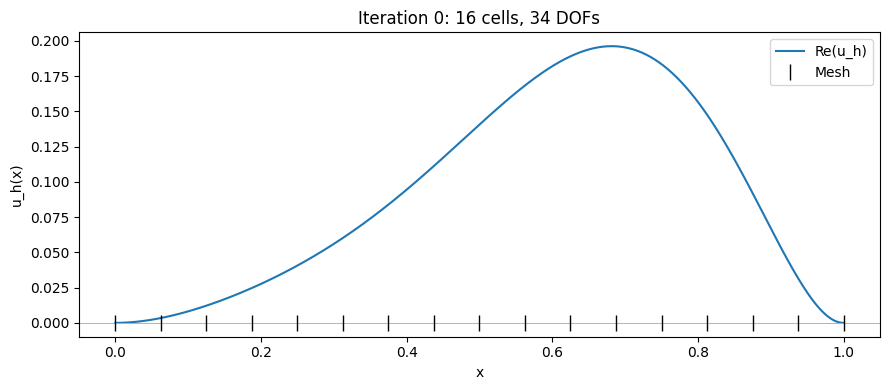



Iteration 0: 16 cells, 34 DOFs
L2 error = 1.767669e-05
H1 error = 9.800213e-04
H2 error = 1.016474e-01
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.010320068054438403+0j)
True goal error: (0.01033123221558796+0j)
Their absolute difference: 1.1164161149556512e-05
Saved: biharmonic_snapshots/iteration_01.npz and biharmonic_snapshots/iteration_01.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.032006805430e-02
Sum of dual refinement indicators:       1.032006805430e-02
Sum of refinement indicators:            1.032006805430e-02
Effectivity index:                       0.998919377581
Localisation efficiency:                 0.998919377568
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 1] ----------------------------

Solving primal (degree: 3

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Checking boundary value squared: 0j
Checking boundary derivative squared: 0j
Solving primal with higher order for error estimate (degree: 4, dofs: 53) ...
Computed goal J(uh):                    20.968144309811+0.000000000000j
Exact goal J(u):                         20.973160173160+0.000000000000j
True error, J(u) - J(u_h):               5.015863349339e-03+0.000000000000e+00j
Primal error, rho(u_h; z-z_h):           5.009023787337e-03+0.000000000000e+00j
Dual error,  rho*(z_h; u-u_h):           5.009023787337e-03-0.000000000000e+00j
Difference, primal-dual:                 0.000000000000e+00
Discretisation error, 0.5(rho + rho*)    5.009023787337e-03+0.000000000000e+00j
Solver error, rho(u_h; z_h):            -1.776356839400e-15+0.000000000000e+00j
Final error estimate:                    5.009023787335e-03+0.000000000000e+00j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


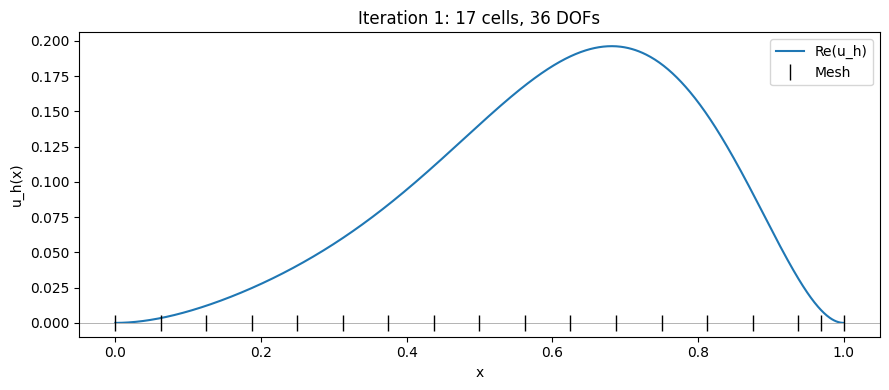



Iteration 1: 17 cells, 36 DOFs
L2 error = 1.189609e-05
H1 error = 6.642782e-04
H2 error = 7.082588e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.005009023787335012+0j)
True goal error: (0.0050158633493389004+0j)
Their absolute difference: 6.839562003888543e-06
Saved: biharmonic_snapshots/iteration_02.npz and biharmonic_snapshots/iteration_02.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     5.009023787328e-03
Sum of dual refinement indicators:       5.009023787328e-03
Sum of refinement indicators:            5.009023787328e-03
Effectivity index:                       0.998636413808
Localisation efficiency:                 0.998636413807
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 2] ----------------------------

Solving primal (degree: 

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


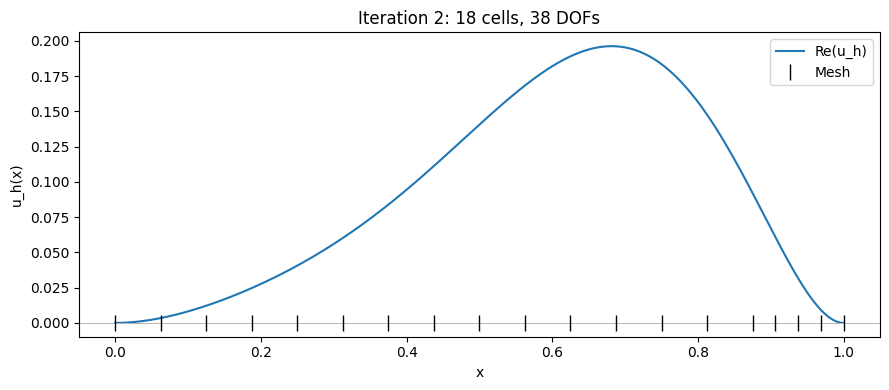



Iteration 2: 18 cells, 38 DOFs
L2 error = 7.566170e-06
H1 error = 4.304977e-04
H2 error = 4.894509e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.0023914457666615184+0j)
True goal error: (0.0023954360974158817+0j)
Their absolute difference: 3.990330754363291e-06
Saved: biharmonic_snapshots/iteration_03.npz and biharmonic_snapshots/iteration_03.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     2.391445766659e-03
Sum of dual refinement indicators:       2.391445766659e-03
Sum of refinement indicators:            2.391445766659e-03
Effectivity index:                       0.998334194446
Localisation efficiency:                 0.998334194445
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 3] ----------------------------

Solving primal (degree:

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


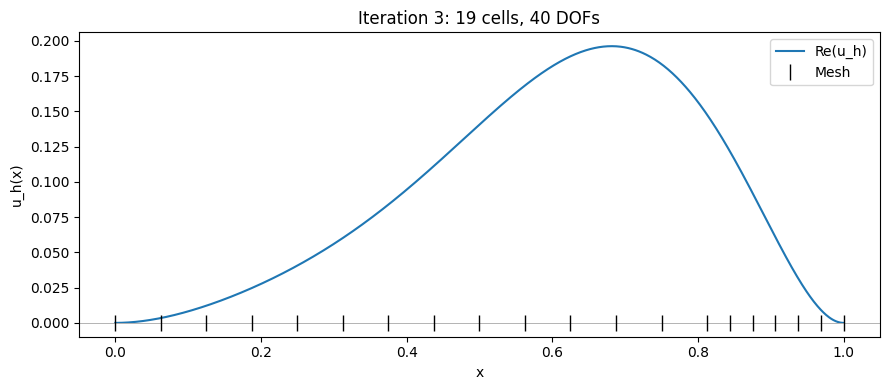



Iteration 3: 19 cells, 40 DOFs
L2 error = 4.534092e-06
H1 error = 2.718355e-04
H2 error = 3.541893e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.0012522159329135872+0j)
True goal error: (0.0012544269266498986+0j)
Their absolute difference: 2.2109937363114403e-06
Saved: biharmonic_snapshots/iteration_04.npz and biharmonic_snapshots/iteration_04.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.252215932915e-03
Sum of dual refinement indicators:       1.252215932915e-03
Sum of refinement indicators:            1.252215932915e-03
Effectivity index:                       0.998237447165
Localisation efficiency:                 0.998237447166
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 4] ----------------------------

Solving primal (degree

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


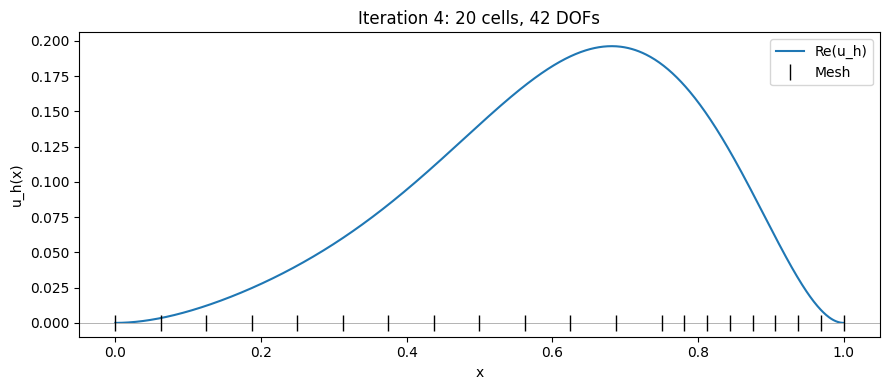



Iteration 4: 20 cells, 42 DOFs
L2 error = 2.718450e-06
H1 error = 1.841069e-04
H2 error = 2.906598e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.000843621656276559+0j)
True goal error: (0.0008447975033689659+0j)
Their absolute difference: 1.1758470924068138e-06
Saved: biharmonic_snapshots/iteration_05.npz and biharmonic_snapshots/iteration_05.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     8.436216562928e-04
Sum of dual refinement indicators:       8.436216562928e-04
Sum of refinement indicators:            8.436216562928e-04
Effectivity index:                       0.998608131431
Localisation efficiency:                 0.998608131450
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 5] ----------------------------

Solving primal (degree:

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


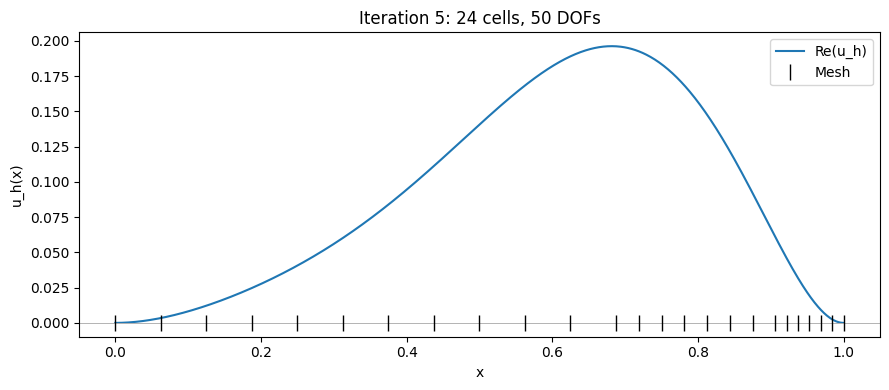



Iteration 5: 24 cells, 50 DOFs
L2 error = 1.793474e-06
H1 error = 1.152163e-04
H2 error = 1.756041e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.00030781677179762276+0j)
True goal error: (0.00030835468110979036+0j)
Their absolute difference: 5.379093121676078e-07
Saved: biharmonic_snapshots/iteration_06.npz and biharmonic_snapshots/iteration_06.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     3.078167718452e-04
Sum of dual refinement indicators:       3.078167718452e-04
Sum of refinement indicators:            3.078167718452e-04
Effectivity index:                       0.998255550037
Localisation efficiency:                 0.998255550191
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 6] ----------------------------

Solving primal (degre

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


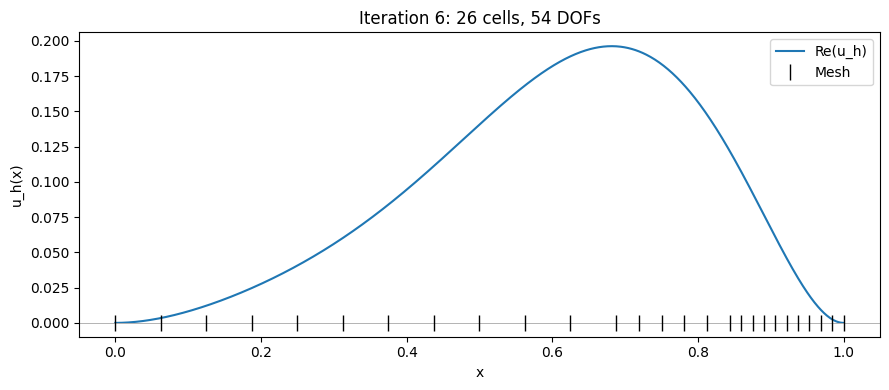



Iteration 6: 26 cells, 54 DOFs
L2 error = 1.729769e-06
H1 error = 1.027081e-04
H2 error = 1.402562e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.00019620514232601731+0j)
True goal error: (0.00019670744660515993+0j)
Their absolute difference: 5.02304279142616e-07
Saved: biharmonic_snapshots/iteration_07.npz and biharmonic_snapshots/iteration_07.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.962051423466e-04
Sum of dual refinement indicators:       1.962051423466e-04
Sum of refinement indicators:            1.962051423466e-04
Effectivity index:                       0.997446439940
Localisation efficiency:                 0.997446440045
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 7] ----------------------------

Solving primal (degree

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


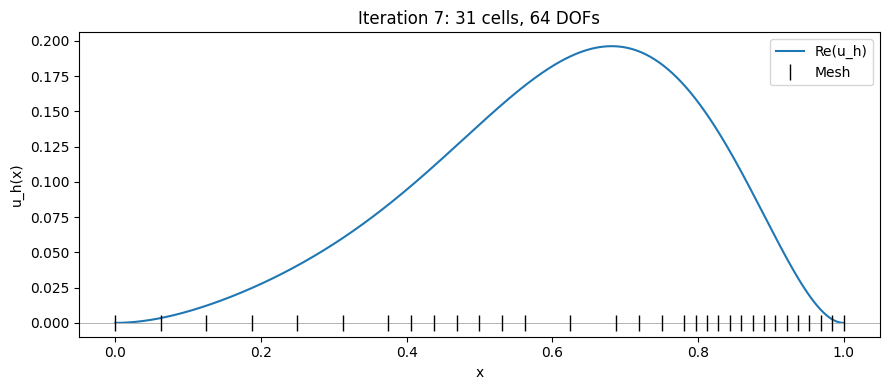



Iteration 7: 31 cells, 64 DOFs
L2 error = 1.110011e-06
H1 error = 6.615948e-05
H2 error = 9.990121e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (9.93422626178357e-05+0j)
True goal error: (9.979814369742712e-05+0j)
Their absolute difference: 4.5588107959141516e-07
Saved: biharmonic_snapshots/iteration_08.npz and biharmonic_snapshots/iteration_08.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     9.934226280432e-05
Sum of dual refinement indicators:       9.934226280432e-05
Sum of refinement indicators:            9.934226280432e-05
Effectivity index:                       0.995431968344
Localisation efficiency:                 0.995431970213
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 8] ----------------------------

Solving primal (degree:

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


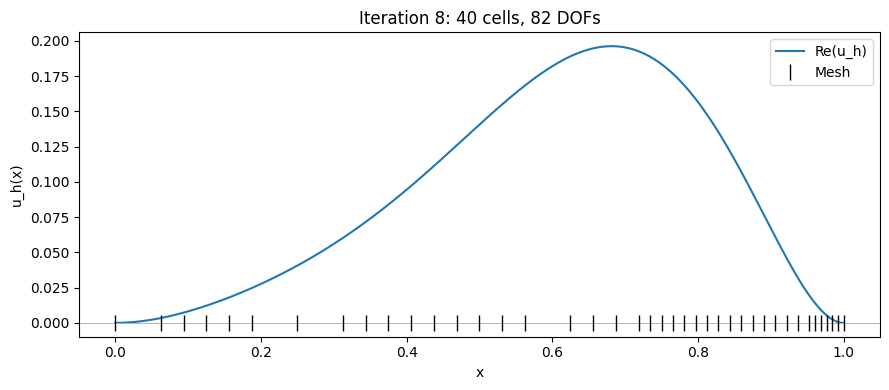



Iteration 8: 40 cells, 82 DOFs
L2 error = 5.095109e-07
H1 error = 3.257823e-05
H2 error = 6.267857e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (3.911763248272649e-05+0j)
True goal error: (3.9284968252673025e-05+0j)
Their absolute difference: 1.673357699465353e-07
Saved: biharmonic_snapshots/iteration_09.npz and biharmonic_snapshots/iteration_09.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     3.911763261425e-05
Sum of dual refinement indicators:       3.911763261425e-05
Sum of refinement indicators:            3.911763261425e-05
Effectivity index:                       0.995740463149
Localisation efficiency:                 0.995740466497
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 9] ----------------------------

Solving primal (degree

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


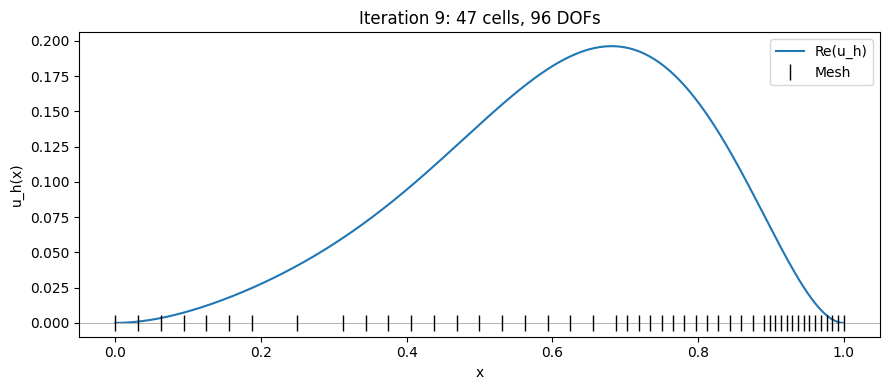



Iteration 9: 47 cells, 96 DOFs
L2 error = 2.565999e-07
H1 error = 1.898899e-05
H2 error = 4.342353e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (1.8800717463761487e-05+0j)
True goal error: (1.8855666596095944e-05+0j)
Their absolute difference: 5.4949132334456915e-08
Saved: biharmonic_snapshots/iteration_10.npz and biharmonic_snapshots/iteration_10.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.880071763850e-05
Sum of dual refinement indicators:       1.880071763850e-05
Sum of refinement indicators:            1.880071763850e-05
Effectivity index:                       0.997085802719
Localisation efficiency:                 0.997085811985
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 10] ----------------------------

Solving primal (deg

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Computed goal J(uh):                    20.973148093420+0.000000000000j
Exact goal J(u):                         20.973160173160+0.000000000000j
True error, J(u) - J(u_h):               1.207974051098e-05+0.000000000000e+00j
Primal error, rho(u_h; z-z_h):           1.204529162350e-05+0.000000000000e+00j
Dual error,  rho*(z_h; u-u_h):           1.204529162350e-05-0.000000000000e+00j
Difference, primal-dual:                 0.000000000000e+00
Discretisation error, 0.5(rho + rho*)    1.204529162350e-05+0.000000000000e+00j
Solver error, rho(u_h; z_h):            -6.661338147751e-15+0.000000000000e+00j
Final error estimate:                    1.204529161684e-05+0.000000000000e+00j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


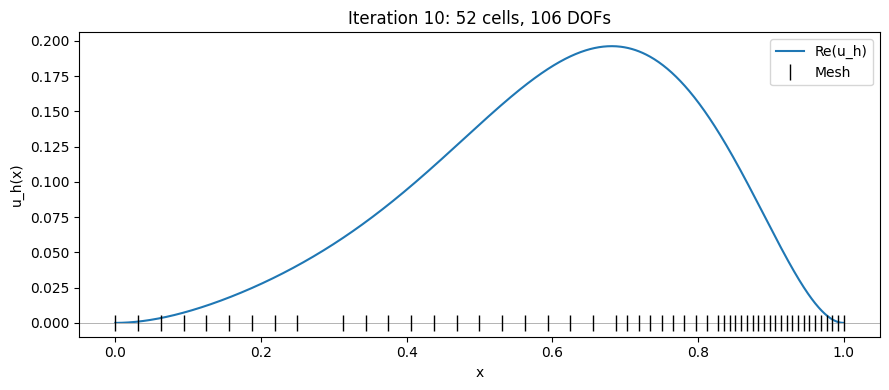



Iteration 10: 52 cells, 106 DOFs
L2 error = 1.729638e-07
H1 error = 1.478083e-05
H2 error = 3.475624e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (1.2045291616835376e-05+0j)
True goal error: (1.2079740510984038e-05+0j)
Their absolute difference: 3.4448894148662493e-08
Saved: biharmonic_snapshots/iteration_11.npz and biharmonic_snapshots/iteration_11.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.204529174326e-05
Sum of dual refinement indicators:       1.204529174326e-05
Sum of refinement indicators:            1.204529174326e-05
Effectivity index:                       0.997148209093
Localisation efficiency:                 0.997148219558
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 11] ----------------------------

Solving primal (d

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Computed goal J(uh):                    20.973153977045+0.000000000000j
Exact goal J(u):                         20.973160173160+0.000000000000j
True error, J(u) - J(u_h):               6.196115311496e-06+0.000000000000e+00j
Primal error, rho(u_h; z-z_h):           6.191039830099e-06+0.000000000000e+00j
Dual error,  rho*(z_h; u-u_h):           6.191039830099e-06-0.000000000000e+00j
Difference, primal-dual:                 0.000000000000e+00
Discretisation error, 0.5(rho + rho*)    6.191039830099e-06+0.000000000000e+00j
Solver error, rho(u_h; z_h):            -1.035976859853e-13+0.000000000000e+00j
Final error estimate:                    6.191039726501e-06+0.000000000000e+00j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


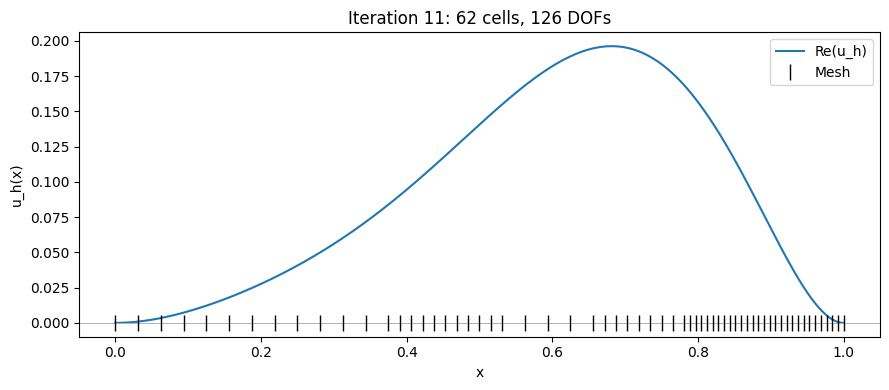



Iteration 11: 62 cells, 126 DOFs
L2 error = 6.869137e-08
H1 error = 8.195159e-06
H2 error = 2.489213e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (6.191039726501344e-06+0j)
True goal error: (6.196115311496442e-06+0j)
Their absolute difference: 5.0755849950973885e-09
Saved: biharmonic_snapshots/iteration_12.npz and biharmonic_snapshots/iteration_12.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     6.191040182061e-06
Sum of dual refinement indicators:       6.191040182061e-06
Sum of refinement indicators:            6.191040182061e-06
Effectivity index:                       0.999180844006
Localisation efficiency:                 0.999180917530
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 12] ----------------------------

Solving primal (deg

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Checking boundary value squared: 0j
Checking boundary derivative squared: 0j
Solving primal with higher order for error estimate (degree: 4, dofs: 215) ...
Computed goal J(uh):                    20.973156333433+0.000000000000j
Exact goal J(u):                         20.973160173160+0.000000000000j
True error, J(u) - J(u_h):               3.839726691268e-06+0.000000000000e+00j
Primal error, rho(u_h; z-z_h):           3.835170755922e-06+0.000000000000e+00j
Dual error,  rho*(z_h; u-u_h):           3.835170755922e-06-0.000000000000e+00j
Difference, primal-dual:                 0.000000000000e+00
Discretisation error, 0.5(rho + rho*)    3.835170755922e-06+0.000000000000e+00j
Solver error, rho(u_h; z_h):            -3.017586180931e-13+0.000000000000e+00j
Final error estimate:                    3.835170454164e-06+0.000000000000e+00j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


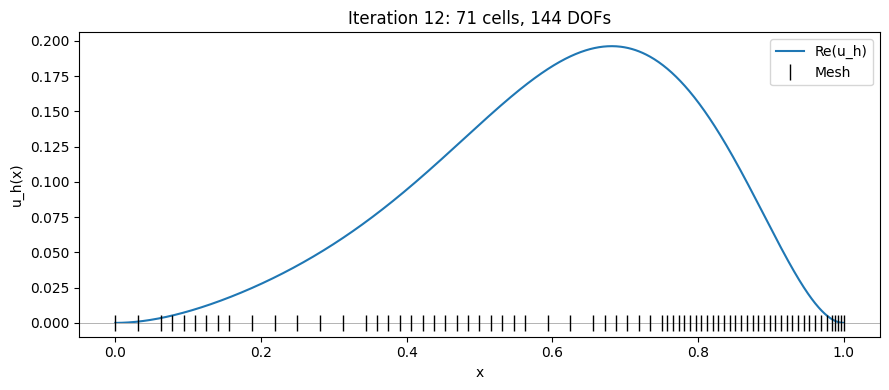



Iteration 12: 71 cells, 144 DOFs
L2 error = 4.387488e-08
H1 error = 5.470087e-06
H2 error = 1.959530e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (3.835170454163506e-06+0j)
True goal error: (3.839726691268197e-06+0j)
Their absolute difference: 4.5562371046910396e-09
Saved: biharmonic_snapshots/iteration_13.npz and biharmonic_snapshots/iteration_13.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     3.835171034252e-06
Sum of dual refinement indicators:       3.835171034252e-06
Sum of refinement indicators:            3.835171034252e-06
Effectivity index:                       0.998813395465
Localisation efficiency:                 0.998813546540
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...


/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "



---------------------------- [MESH LEVEL 13] ----------------------------

Solving primal (degree: 3, dofs: 174) ...
Checking boundary value squared: 0j
Checking boundary derivative squared: 0j
Solving primal with higher order for error estimate (degree: 4, dofs: 260) ...
Computed goal J(uh):                    20.973158449690+0.000000000000j
Exact goal J(u):                         20.973160173160+0.000000000000j
True error, J(u) - J(u_h):               1.723470045789e-06+0.000000000000e+00j
Primal error, rho(u_h; z-z_h):           1.719851614230e-06+0.000000000000e+00j
Dual error,  rho*(z_h; u-u_h):           1.719851614230e-06-0.000000000000e+00j
Difference, primal-dual:                 0.000000000000e+00
Discretisation error, 0.5(rho + rho*)    1.719851614230e-06+0.000000000000e+00j
Solver error, rho(u_h; z_h):            -2.706723734036e-13+0.000000000000e+00j
Final error estimate:                    1.719851343558e-06+0.000000000000e+00j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


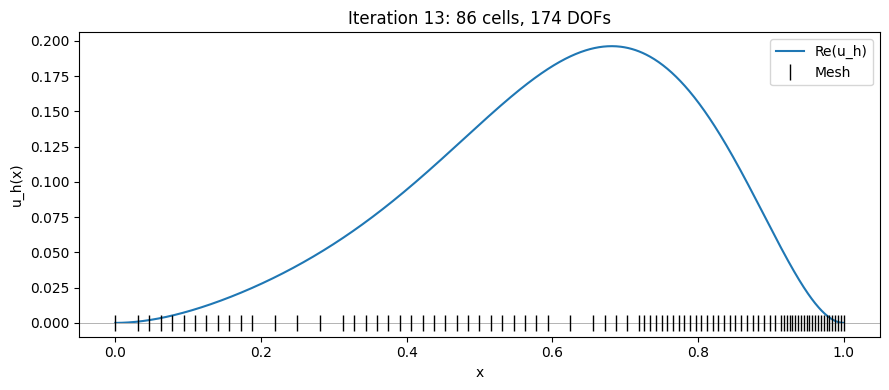



Iteration 13: 86 cells, 174 DOFs
L2 error = 2.540031e-08
H1 error = 3.358277e-06
H2 error = 1.312814e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (1.7198513435580306e-06+0j)
True goal error: (1.7234700457890995e-06+0j)
Their absolute difference: 3.6187022310688196e-09
Saved: biharmonic_snapshots/iteration_14.npz and biharmonic_snapshots/iteration_14.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.719851941757e-06
Sum of dual refinement indicators:       1.719851941757e-06
Sum of refinement indicators:            1.719851941757e-06
Effectivity index:                       0.997900339353
Localisation efficiency:                 0.997900686443
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 14] ----------------------------

Solving primal (d

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


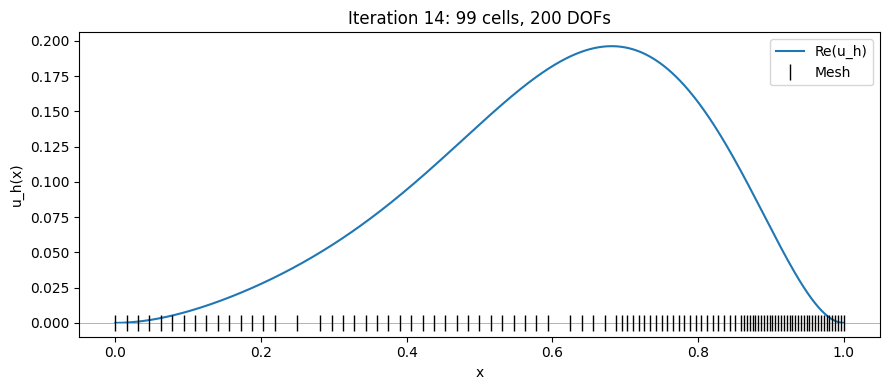



Iteration 14: 99 cells, 200 DOFs
L2 error = 1.006969e-08
H1 error = 1.853996e-06
H2 error = 9.429934e-04
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (8.878194278032618e-07+0j)
True goal error: (8.892330498611045e-07+0j)
Their absolute difference: 1.4136220578426828e-09
Saved: biharmonic_snapshots/iteration_15.npz and biharmonic_snapshots/iteration_15.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     8.878202475139e-07
Sum of dual refinement indicators:       8.878202475139e-07
Sum of refinement indicators:            8.878202475139e-07
Effectivity index:                       0.998410290690
Localisation efficiency:                 0.998411212508
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 15] ----------------------------

Solving primal (deg

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "
/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


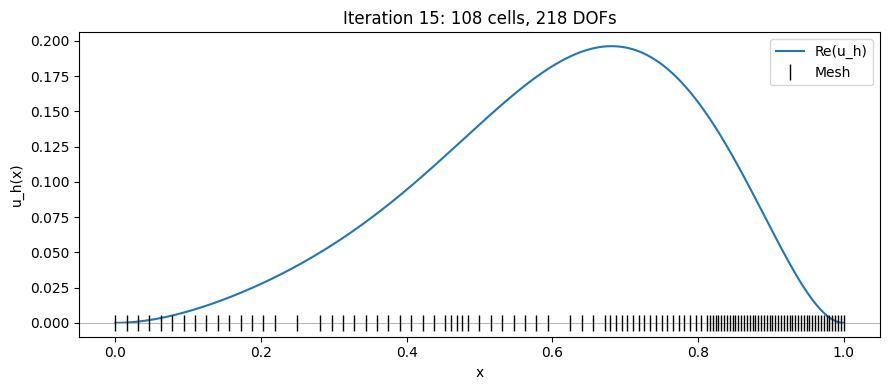



Iteration 15: 108 cells, 218 DOFs
L2 error = 9.554563e-09
H1 error = 1.652548e-06
H2 error = 7.952296e-04
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (6.309987739627591e-07+0j)
True goal error: (6.323874330860235e-07+0j)
Their absolute difference: 1.3886591232644106e-09
Saved: biharmonic_snapshots/iteration_16.npz and biharmonic_snapshots/iteration_16.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     6.310000600867e-07
Sum of dual refinement indicators:       6.310000600867e-07
Sum of refinement indicators:            6.310000600867e-07
Effectivity index:                       0.997804100697
Localisation efficiency:                 0.997806134457
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 16] ----------------------------

Solving primal (de

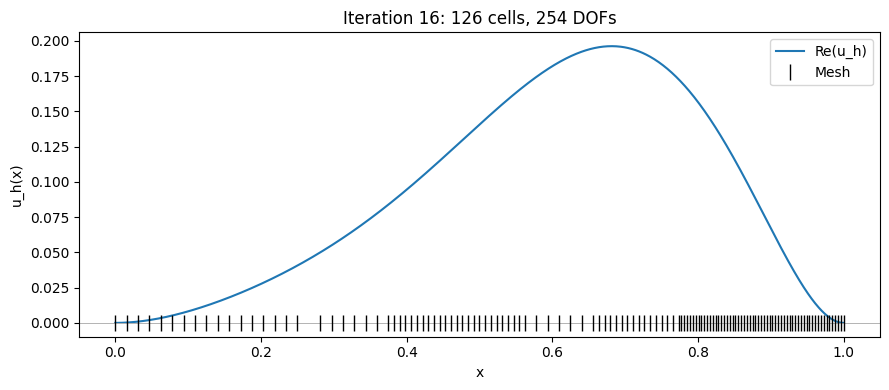



Iteration 16: 126 cells, 254 DOFs
L2 error = 4.520223e-09
H1 error = 9.787544e-07
H2 error = 5.970412e-04
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (3.561760169829092e-07+0j)
True goal error: (3.5645708607034976e-07+0j)
Their absolute difference: 2.810690874405477e-10
Saved: biharmonic_snapshots/iteration_17.npz and biharmonic_snapshots/iteration_17.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     3.561777763113e-07
Sum of dual refinement indicators:       3.561777763113e-07
Sum of refinement indicators:            3.562930142792e-07
Effectivity index:                       0.999211492495
Localisation efficiency:                 0.999539715165
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 17] ----------------------------

Solving primal (de

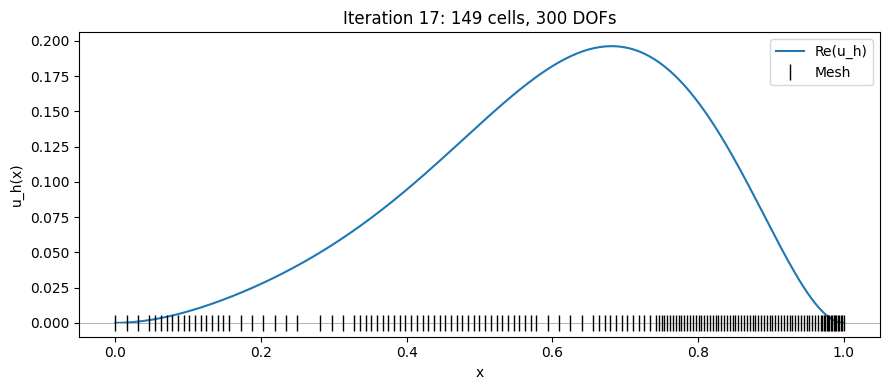



Iteration 17: 149 cells, 300 DOFs
L2 error = 3.204911e-09
H1 error = 6.411333e-07
H2 error = 4.453726e-04
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (1.9808551911120028e-07+0j)
True goal error: (1.9835678699564596e-07+0j)
Their absolute difference: 2.7126788444568313e-10
Saved: biharmonic_snapshots/iteration_18.npz and biharmonic_snapshots/iteration_18.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.980867328317e-07
Sum of dual refinement indicators:       1.980867328317e-07
Sum of refinement indicators:            1.985570783864e-07
Effectivity index:                       0.998632424488
Localisation efficiency:                 1.001009753151
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 18] ----------------------------

Solving primal (

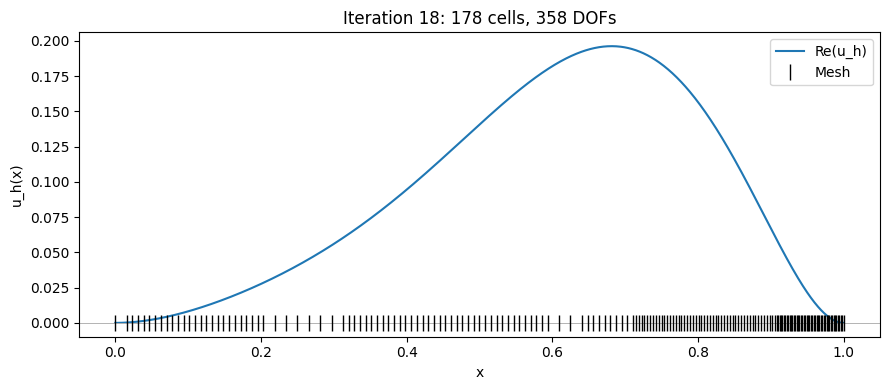



Iteration 18: 178 cells, 358 DOFs
L2 error = 1.179178e-09
H1 error = 3.407725e-07
H2 error = 3.015577e-04
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (9.089515810403933e-08+0j)
True goal error: (9.093716002439578e-08+0j)
Their absolute difference: 4.200192035644529e-11
Saved: biharmonic_snapshots/iteration_19.npz and biharmonic_snapshots/iteration_19.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     9.089650077853e-08
Sum of dual refinement indicators:       9.089650077853e-08
Sum of refinement indicators:            9.163172854201e-08
Effectivity index:                       0.999538121486
Localisation efficiency:                 1.007637895415
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 19] ----------------------------

Solving primal (deg

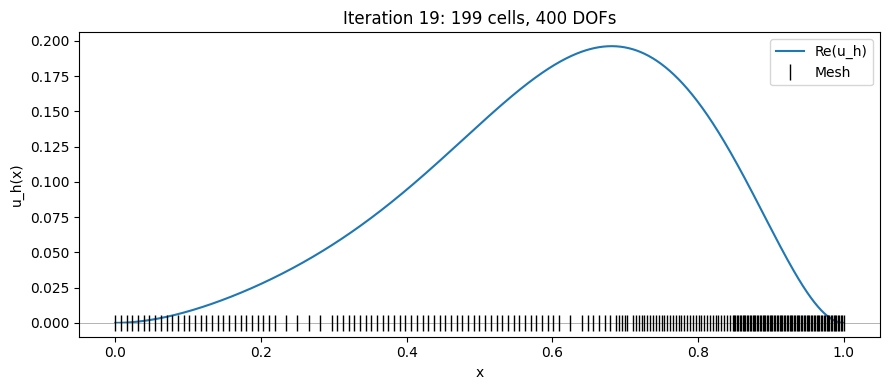



Iteration 19: 199 cells, 400 DOFs
L2 error = 7.687669e-10
H1 error = 2.536673e-07
H2 error = 2.356115e-04
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (5.548357971579361e-08+0j)
True goal error: (5.551297377337505e-08+0j)
Their absolute difference: 2.939405758143838e-11
Saved: biharmonic_snapshots/iteration_20.npz and biharmonic_snapshots/iteration_20.png

Maximum iteration (20) reached. Exiting.


In [58]:
from firedrake import *

# ------------------------------------------------------------
# 1. Initial mesh and Hermite approximation space
# ------------------------------------------------------------
mesh = UnitIntervalMesh(16)
V = FunctionSpace(mesh, "Hermite", 3)

uh = Function(V, name="uh")
v = TestFunction(V)
x = SpatialCoordinate(mesh)[0]

# ------------------------------------------------------------
# 2. Manufactured solution and corresponding forcing
# ------------------------------------------------------------
# Start with a reasonably resolved bump for the first test.
# width = Constant(0.05)
# u_exact = x**2 * (1 - x)**2 * exp(-((x - 0.5) / width)**2)
# # The PDE is u'''' = f.
# f = u_exact.dx(0).dx(0).dx(0).dx(0)

x = SpatialCoordinate(mesh)[0]
u_exact = x**2 * (1 - x)**2 * (1 + 10*x**3)
f = 8400*x**3 - 7200*x**2 + 1200*x + 24

# ------------------------------------------------------------
# 3. Clamped conditions: u = u' = 0 at both endpoints
# ------------------------------------------------------------
bc = DirichletBC(V, 0, "on_boundary")
bc.nodes = V.boundary_nodes("on_boundary")

# ------------------------------------------------------------
# 4. Primal residual and self-dual goal
# ------------------------------------------------------------

F = (inner(uh.dx(0).dx(0), v.dx(0).dx(0)) - inner(f, v)) * dx

# With this Hermitian operator, this goal gives z = u.
J = inner(uh, f) * dx

problem = NonlinearVariationalProblem(
    F,
    uh,
    bcs=[bc],
)

# ------------------------------------------------------------
# 5. Plot and save after each solve
# ------------------------------------------------------------
callback = make_post_iteration_callback(
    output_dir="biharmonic_snapshots",
    npoints=1001,
    bc_tol=1e-10,
    show=True,
)

# ------------------------------------------------------------
# 6. Adaptive options
# ------------------------------------------------------------
solver_parameters = {
    "goal_adaptive": {
        "dual_is_primal": True,
        "biharmonic_1D": True,
        "use_adjoint_residual": True,

        # Independently solve the base and enriched primal problems.
        "primal_low_method": "solve", # use u_high - uh as our weight
        "primal_extra_degree": 1,

        "dorfler_alpha": 0.5,
        "max_it": 20,
        "max_dofs": None,

        # For this diagnostic test, stop at max_it rather than tolerance.
        "tolerance": 0.0,
        "verbose": True,
    },
    "snes_type": "ksponly",
    "ksp_type": "preonly",
    "pc_type": "lu",
}

# ------------------------------------------------------------
# 7. Run
# ------------------------------------------------------------
adaptive_solver = GoalAdaptiveNonlinearVariationalSolver(
    problem,
    J,
    exact_solution=u_exact,
    solver_parameters=solver_parameters,
    post_iteration_callback=callback,
)

solution = adaptive_solver.solve()

<IPython.core.display.Math object>

Local slopes:
[ -6.92876325  -8.36962832  -9.98302221 -10.48496602  -2.38542722
  -0.46992954  -2.61106877  -3.14189062  -4.35156825  -3.98054376
  -5.34276696  -3.35712495  -2.88826198  -6.64381573  -0.60933583
  -4.89702566  -2.06596977  -5.65693831  -3.85629767]



<IPython.core.display.Math object>

Local slopes:
[-6.80343071 -8.02258867 -8.9630593  -7.98686136 -2.68825074 -1.4932237
 -2.58873108 -2.85843704 -3.42440182 -2.52826415 -3.41227813 -3.02737142
 -2.57800327 -4.26594689 -1.3347391  -3.42708657 -2.54159095 -3.57578731
 -2.66102636]



<IPython.core.display.Math object>

Local slopes:
[-6.32077539 -6.83455565 -6.30594049 -4.0515947  -2.89023163 -2.92045506
 -1.99700298 -1.88092902 -2.32836797 -2.2468501  -1.93127617 -1.79180461
 -2.11650349 -2.37587407 -1.97763915 -1.87546629 -1.76075707 -2.20621683
 -2.22458897]



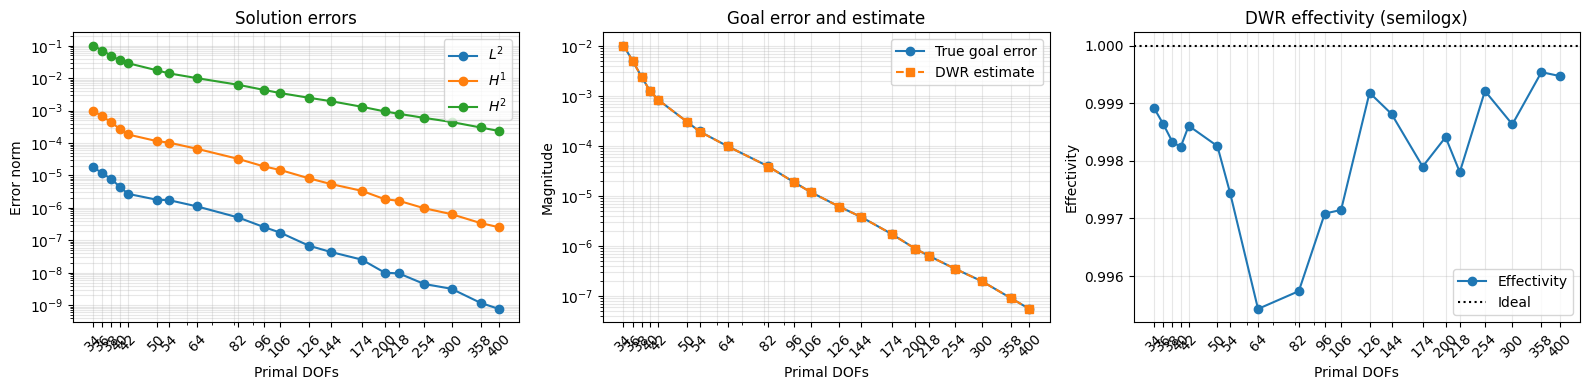

In [59]:
from IPython.display import display, Math

# Each snapshot contains errors and DOFs from the same solved mesh.
snapshots = adaptive_solver.snapshots
dofs = np.array([s["dofs"] for s in snapshots])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Solution errors: logarithmic axes make convergence easier to see.
for key, label in [
    ("L2_error", r"$L^2$"),
    ("H1_error", r"$H^1$"),
    ("H2_error", r"$H^2$"),
]:
    errors = np.array([s[key] for s in snapshots])

    # approximate the slope
    slope, intercept = np.polyfit(np.log(dofs), np.log(errors), 1)
    display(Math(rf"{label.strip('$')}: \quad \mathrm{{slope}} = {slope:.3f}"))

    local_slopes = np.diff(np.log(errors)) / np.diff(np.log(dofs))
    print('Local slopes:')
    print(local_slopes)
    print()

    axes[0].loglog(dofs, errors, "o-", label=label)


axes[0].set(xlabel="Primal DOFs", ylabel="Error norm",
            title="Solution errors")

# Compare the true goal error with its DWR estimate.
# Magnitudes allow complex-valued quantities to appear on logarithmic axes.
goal_errors = np.abs([s["true_goal_error"] for s in snapshots])
estimates = np.abs([s["goal_estimate"] for s in snapshots])

axes[1].loglog(dofs, goal_errors, "o-", label="True goal error")
axes[1].loglog(dofs, estimates, "s--", label="DWR estimate")
axes[1].set(xlabel="Primal DOFs", ylabel="Magnitude",
            title="Goal error and estimate")


# Effectivity: estimated error magnitude / true error magnitude.
effectivity = np.divide(estimates, goal_errors, out=np.full_like(goal_errors, np.nan), where=goal_errors > 0)
axes[2].semilogx(dofs, effectivity, "o-", label="Effectivity")
axes[2].axhline(1, color="black", linestyle=":", label="Ideal")
axes[2].set(
    xlabel="Primal DOFs",
    ylabel="Effectivity",
    title="DWR effectivity (semilogx)",)


for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    ax.set_xticks(dofs)
    ax.set_xticklabels([str(n) for n in dofs])
    ax.tick_params(axis="x", which="both", labelrotation=45)

fig.tight_layout()
fig.savefig("biharmonic_convergence.png", dpi=200)
plt.show()


---------------------------- [MESH LEVEL 0] ----------------------------

Solving primal (degree: 3, dofs: 34) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 3.954585122901e+03 true resid norm 3.954585122901e+03 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 8.126346843317e-12 true resid norm 8.095928485644e-12 ||r(i)||/||b|| 2.047225747844e-15
Checking boundary value squared: 0j
Checking boundary derivative squared: 0j
Solving primal with higher order for error estimate (degree: 4, dofs: 50) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 4.308639460549e+03 true resid norm 4.308639460549e+03 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 3.610891168166e-11 true resid norm 3.757987586814e-11 ||r(i)||/||b|| 8.721982011311e-15
Computed goal J(uh):                    118.619150750798+0.000000000000j
Exact goal J(u):                         121.059727287451+0.000000000000j
Tr

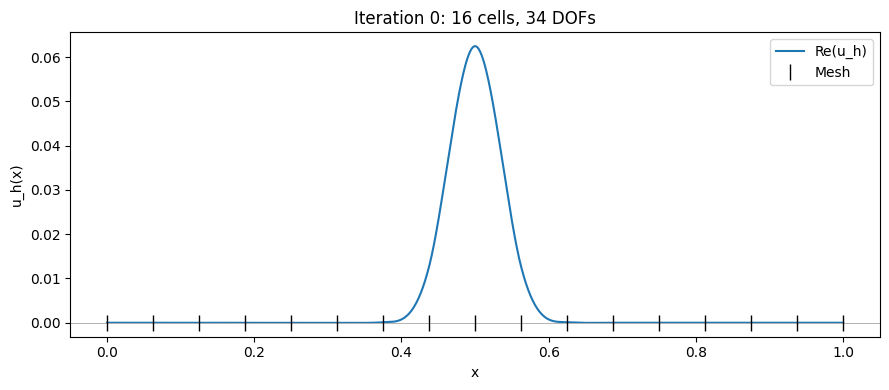



Iteration 0: 16 cells, 34 DOFs
L2 error = 1.829946e-04
H1 error = 1.259779e-02
H2 error = 1.562285e+00
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.8742557999245733-1.392774206021082e-28j)
True goal error: (2.440576536652543-7.582078330316585e-29j)
Their absolute difference: 1.5663207367279697
Saved: biharmonic_snapshots/iteration_01.npz and biharmonic_snapshots/iteration_01.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     8.742557990145e-01
Sum of dual refinement indicators:       8.742557990145e-01
Sum of refinement indicators:            8.742557990145e-01
Effectivity index:                       0.358216915878
Localisation efficiency:                 0.358216915505
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...


/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "



---------------------------- [MESH LEVEL 1] ----------------------------

Solving primal (degree: 3, dofs: 38) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 1.190040401763e+03 true resid norm 1.190040401763e+03 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 9.277513545282e-13 true resid norm 9.948153874058e-13 ||r(i)||/||b|| 8.359509357264e-16
Checking boundary value squared: (4.84358088833131e-32+0j)
Checking boundary derivative squared: (4.568259433674994e-32+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 56) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 3.340891482761e+03 true resid norm 3.340891482761e+03 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 1.698824018029e-10 true resid norm 1.399141969532e-10 ||r(i)||/||b|| 4.187930008357e-14
Computed goal J(uh):                    120.070186685491-0.000000000000j
Exact goal J(u):             

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


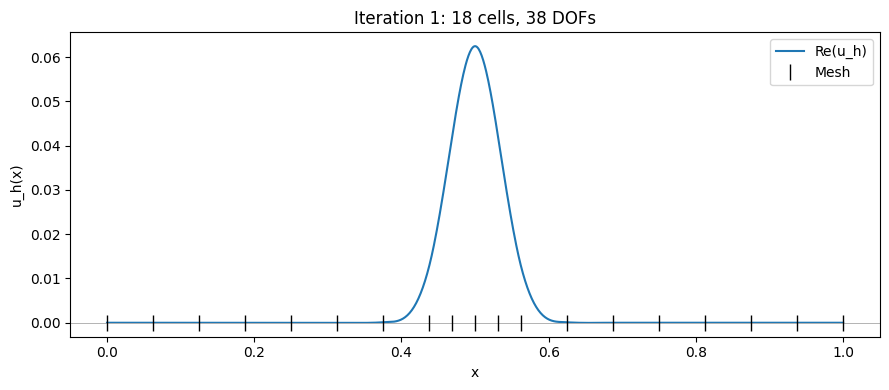



Iteration 1: 18 cells, 38 DOFs
L2 error = 7.813031e-05
H1 error = 5.902607e-03
H2 error = 9.947741e-01
Boundary norms: value=2.201e-16, slope=2.137e-16; PASS (tolerance 1.0e-10)
DWR estimate: (0.9288041765552364+4.0389678347315804e-28j)
True goal error: (0.9895406019403055+2.017642613362019e-28j)
Their absolute difference: 0.06073642538506907
Saved: biharmonic_snapshots/iteration_02.npz and biharmonic_snapshots/iteration_02.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     9.288041765306e-01
Sum of dual refinement indicators:       9.288041765306e-01
Sum of refinement indicators:            9.288041807428e-01
Effectivity index:                       0.938621593428
Localisation efficiency:                 0.938621597660
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 2] --------------------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Computed goal J(uh):                    120.822446118267-0.000000000000j
Exact goal J(u):                         121.059727287432+0.000000000000j
True error, J(u) - J(u_h):               2.372811691648e-01+2.527614786873e-28j
Primal error, rho(u_h; z-z_h):           1.962160116887e-01-4.872100905372e-24j
Dual error,  rho*(z_h; u-u_h):           1.962160116887e-01+4.872100905372e-24j
Difference, primal-dual:                 9.744201810744e-24
Discretisation error, 0.5(rho + rho*)    1.962160116887e-01+0.000000000000e+00j
Solver error, rho(u_h; z_h):             7.105427357601e-14+2.524354896707e-28j
Final error estimate:                    1.962160116887e-01+2.524354896707e-28j




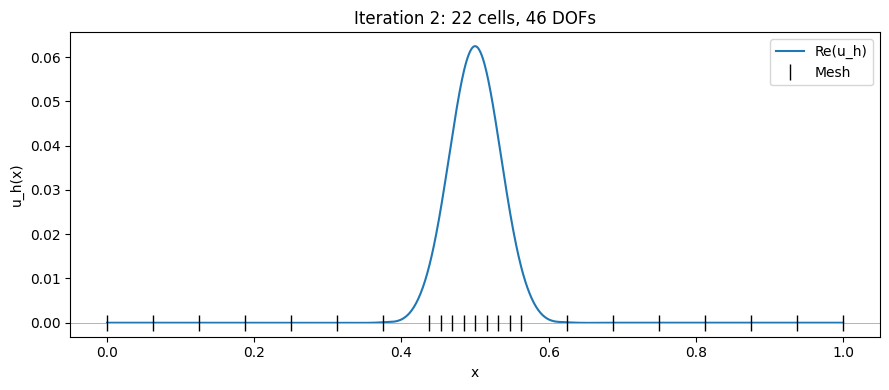



Iteration 2: 22 cells, 46 DOFs
L2 error = 6.792264e-05
H1 error = 4.061670e-03
H2 error = 4.871321e-01
Boundary norms: value=3.850e-17, slope=3.932e-16; PASS (tolerance 1.0e-10)
DWR estimate: (0.19621601168873803+2.524354896707238e-28j)
True goal error: (0.23728116916480246+2.5276147868731453e-28j)
Their absolute difference: 0.04106515747606443
Saved: biharmonic_snapshots/iteration_03.npz and biharmonic_snapshots/iteration_03.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.962160116639e-01
Sum of dual refinement indicators:       1.962160116639e-01
Sum of refinement indicators:            1.962160159238e-01
Effectivity index:                       0.826934612550
Localisation efficiency:                 0.826934630398
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 3] ------------------

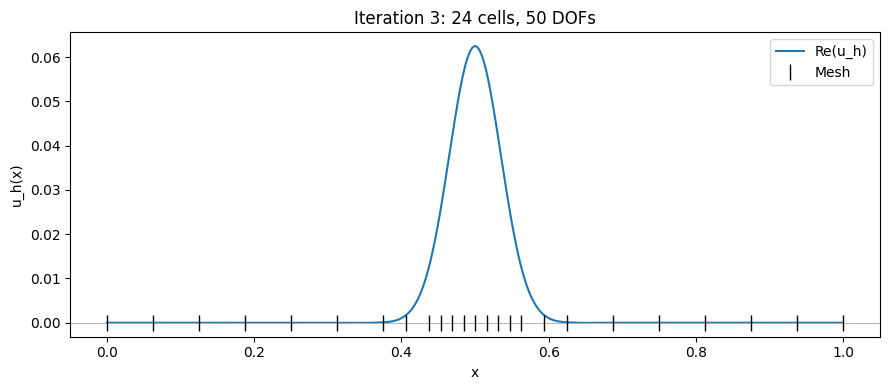



Iteration 3: 24 cells, 50 DOFs
L2 error = 1.033094e-05
H1 error = 9.921405e-04
H2 error = 2.798000e-01
Boundary norms: value=1.080e-15, slope=1.514e-14; PASS (tolerance 1.0e-10)
DWR estimate: (0.07483003522680637+5.301145283085199e-28j)
True goal error: (0.07828707624481979+5.809778008532898e-28j)
Their absolute difference: 0.003457041018013418
Saved: biharmonic_snapshots/iteration_04.npz and biharmonic_snapshots/iteration_04.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     7.483003522605e-02
Sum of dual refinement indicators:       7.483003522605e-02
Sum of refinement indicators:            7.483003522624e-02
Effectivity index:                       0.955841485162
Localisation efficiency:                 0.955841485154
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 4] ------------------

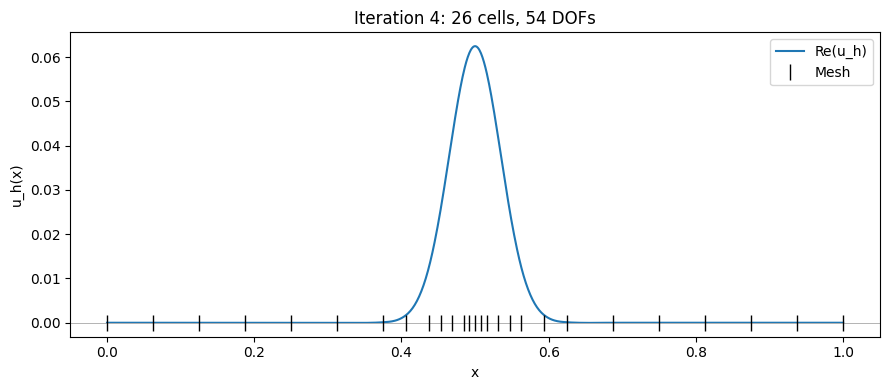



Iteration 4: 26 cells, 54 DOFs
L2 error = 1.015756e-05
H1 error = 9.007709e-04
H2 error = 2.235167e-01
Boundary norms: value=1.220e-16, slope=1.082e-16; PASS (tolerance 1.0e-10)
DWR estimate: (0.04656265825298658+7.068193710780266e-28j)
True goal error: (0.04995890874846509+1.0100293703743635e-27j)
Their absolute difference: 0.003396250495478509
Saved: biharmonic_snapshots/iteration_05.npz and biharmonic_snapshots/iteration_05.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     4.656265825128e-02
Sum of dual refinement indicators:       4.656265825128e-02
Sum of refinement indicators:            4.656265825139e-02
Effectivity index:                       0.932019121703
Localisation efficiency:                 0.932019121671
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 5] -----------------

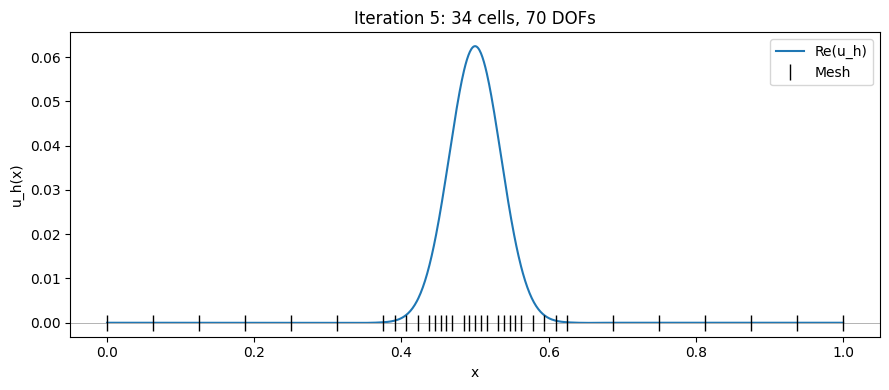



Iteration 5: 34 cells, 70 DOFs
L2 error = 8.013792e-06
H1 error = 4.767618e-04
H2 error = 9.788887e-02
Boundary norms: value=6.875e-15, slope=2.538e-13; PASS (tolerance 1.0e-10)
DWR estimate: (0.00893860822767374+1.3252863207712998e-28j)
True goal error: (0.009582004212219886+2.020059949439438e-28j)
Their absolute difference: 0.0006433959845461457
Saved: biharmonic_snapshots/iteration_06.npz and biharmonic_snapshots/iteration_06.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     8.938608226864e-03
Sum of dual refinement indicators:       8.938608226864e-03
Sum of refinement indicators:            8.938608227097e-03
Effectivity index:                       0.932853715121
Localisation efficiency:                 0.932853715061
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 6] ---------------

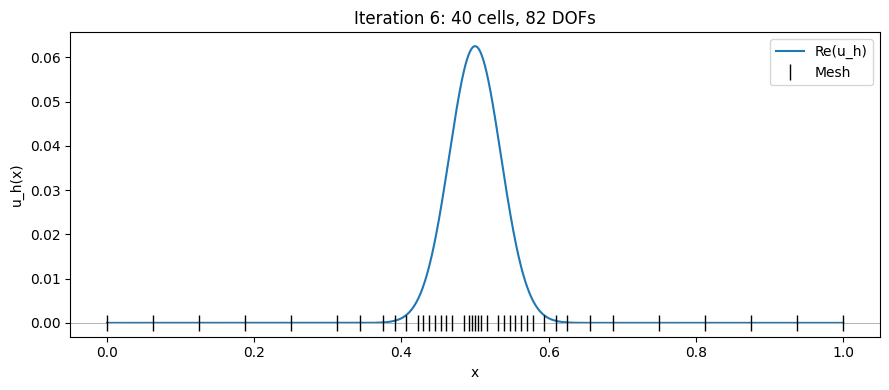



Iteration 6: 40 cells, 82 DOFs
L2 error = 1.041117e-06
H1 error = 1.550870e-04
H2 error = 6.791362e-02
Boundary norms: value=1.081e-16, slope=2.231e-13; PASS (tolerance 1.0e-10)
DWR estimate: (0.004380165603749502-2.612707318091991e-27j)
True goal error: (0.0046122362010834195-2.612958870209325e-27j)
Their absolute difference: 0.0002320705973339176
Saved: biharmonic_snapshots/iteration_07.npz and biharmonic_snapshots/iteration_07.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     4.380165603047e-03
Sum of dual refinement indicators:       4.380165603047e-03
Sum of refinement indicators:            4.380165603047e-03
Effectivity index:                       0.949683713666
Localisation efficiency:                 0.949683713514
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 7] --------------

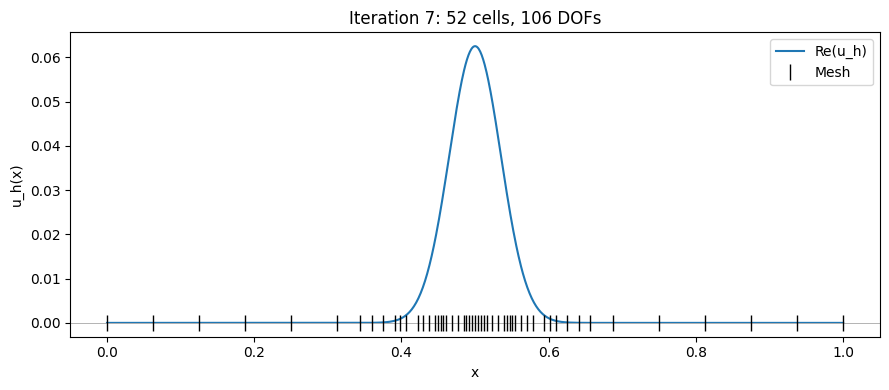



Iteration 7: 52 cells, 106 DOFs
L2 error = 2.286416e-07
H1 error = 5.895733e-05
H2 error = 3.736399e-02
Boundary norms: value=1.579e-14, slope=9.484e-13; PASS (tolerance 1.0e-10)
DWR estimate: (0.0013827869266050707-1.5729886450106975e-27j)
True goal error: (0.0013960644580208736-1.5016156740052198e-27j)
Their absolute difference: 1.327753141580298e-05
Saved: biharmonic_snapshots/iteration_08.npz and biharmonic_snapshots/iteration_08.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.382786923863e-03
Sum of dual refinement indicators:       1.382786923863e-03
Sum of refinement indicators:            1.382786932781e-03
Effectivity index:                       0.990489313484
Localisation efficiency:                 0.990489317908
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 8] ----------

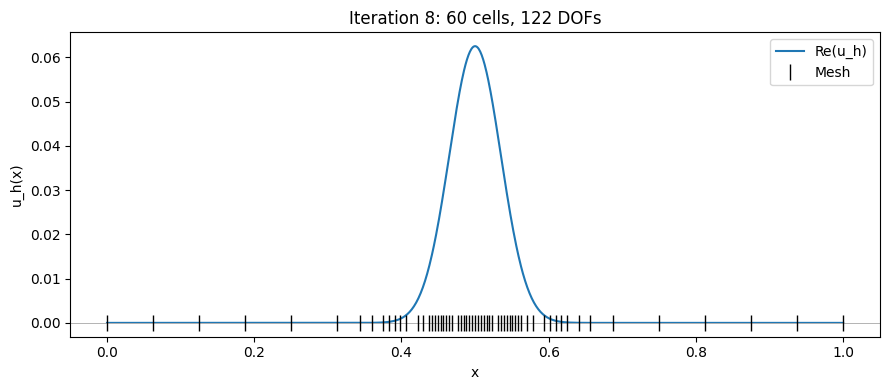



Iteration 8: 60 cells, 122 DOFs
L2 error = 1.425583e-07
H1 error = 3.477463e-05
H2 error = 2.359947e-02
Boundary norms: value=1.328e-14, slope=3.931e-13; PASS (tolerance 1.0e-10)
DWR estimate: (0.0005468559721374187-4.7079218823589985e-27j)
True goal error: (0.0005569337168509492-4.8660857972923496e-27j)
Their absolute difference: 1.0077744713530472e-05
Saved: biharmonic_snapshots/iteration_09.npz and biharmonic_snapshots/iteration_09.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     5.468559705232e-04
Sum of dual refinement indicators:       5.468559705232e-04
Sum of refinement indicators:            5.468559761804e-04
Effectivity index:                       0.981904947737
Localisation efficiency:                 0.981904954996
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 9] ---------

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


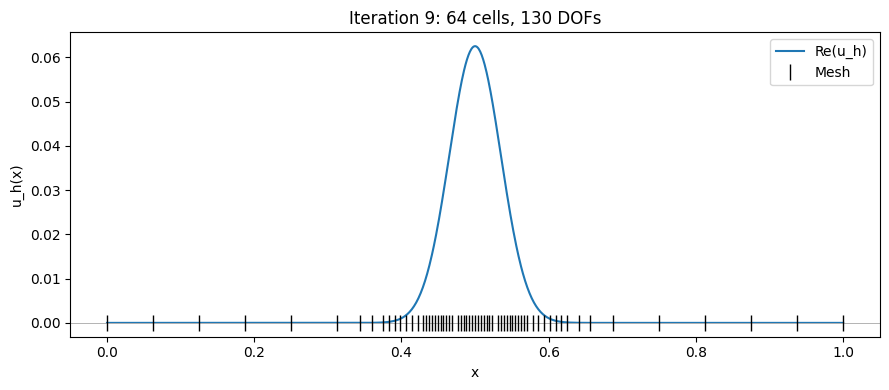



Iteration 9: 64 cells, 130 DOFs
L2 error = 9.207273e-08
H1 error = 2.207909e-05
H2 error = 1.876109e-02
Boundary norms: value=1.626e-14, slope=1.590e-13; PASS (tolerance 1.0e-10)
DWR estimate: (0.00034964551790957297-2.9219407929386277e-27j)
True goal error: (0.00035197802306186077-2.9728566815302986e-27j)
Their absolute difference: 2.3325051522878016e-06
Saved: biharmonic_snapshots/iteration_10.npz and biharmonic_snapshots/iteration_10.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     3.496455160193e-04
Sum of dual refinement indicators:       3.496455160193e-04
Sum of refinement indicators:            3.496455160193e-04
Effectivity index:                       0.993373151164
Localisation efficiency:                 0.993373145794
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 10] ------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 1.053848845796e+03 true resid norm 1.053848845796e+03 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 3.021042524781e-06 true resid norm 2.907481728959e-06 ||r(i)||/||b|| 2.758917220964e-09
    2 KSP unpreconditioned resid norm 1.568156477620e-12 true resid norm 1.009264225016e-06 ||r(i)||/||b|| 9.576935336051e-10
Computed goal J(uh):                    121.059526312313+0.000000000000j
Exact goal J(u):                         121.059727287431-0.000000000000j
True error, J(u) - J(u_h):               2.009751177212e-04-6.874436225072e-27j
Primal error, rho(u_h; z-z_h):           1.991956618266e-04+1.741076174517e-26j
Dual error,  rho*(z_h; u-u_h):           1.991956618266e-04-1.741076174517e-26j
Difference, primal-dual:                 3.482152349035e-26
Discretisation error, 0.5(rho + rho*)    1.991956618266e-04+0.000000000000e+00j
Solver error, rho(u_h; z_h):            -1.428298180683e-

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


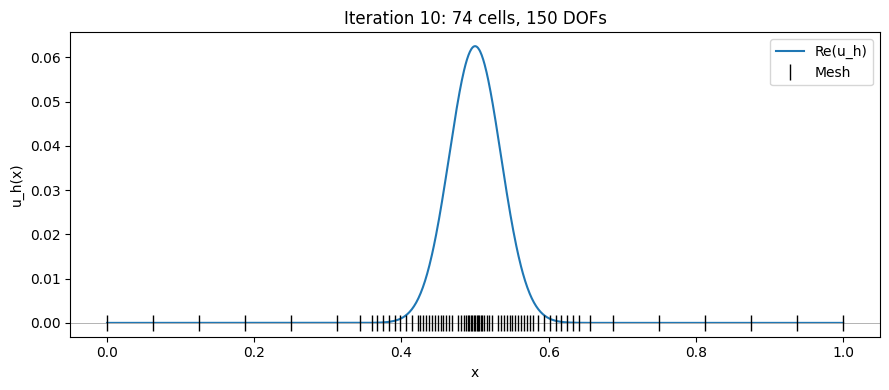



Iteration 10: 74 cells, 150 DOFs
L2 error = 5.996469e-08
H1 error = 1.389153e-05
H2 error = 1.417658e-02
Boundary norms: value=6.733e-14, slope=2.749e-12; PASS (tolerance 1.0e-10)
DWR estimate: (0.000199195660398335-6.976685845774628e-27j)
True goal error: (0.0002009751177212138-6.874436225072088e-27j)
Their absolute difference: 1.7794573228787963e-06
Saved: biharmonic_snapshots/iteration_11.npz and biharmonic_snapshots/iteration_11.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.991956531029e-04
Sum of dual refinement indicators:       1.991956531029e-04
Sum of refinement indicators:            1.992688301140e-04
Effectivity index:                       0.991145882420
Localisation efficiency:                 0.991509955926
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 11] ----------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 7.460105643024e+02 true resid norm 7.460105643024e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 2.695478726971e-12 true resid norm 2.717272402017e-12 ||r(i)||/||b|| 3.642404721920e-15
Checking boundary value squared: (1.821859403102616e-28+0j)
Checking boundary derivative squared: (4.525406716860153e-26+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 290) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 9.013243071758e+02 true resid norm 9.013243071758e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 5.361392609975e-06 true resid norm 5.488363419097e-06 ||r(i)||/||b|| 6.089221576964e-09
    2 KSP unpreconditioned resid norm 3.735596080125e-12 true resid norm 1.228875697414e-06 ||r(i)||/||b|| 1.363411246796e-09
Computed goal J(uh):                    121.059659699847+0.000000000000j
Exact goal J(u): 

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


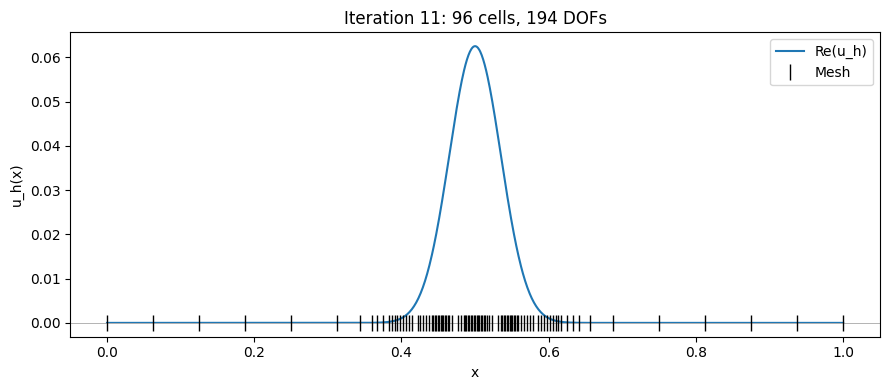



Iteration 11: 96 cells, 194 DOFs
L2 error = 5.640792e-08
H1 error = 9.374935e-06
H2 error = 8.221172e-03
Boundary norms: value=1.350e-14, slope=2.127e-13; PASS (tolerance 1.0e-10)
DWR estimate: (6.585833142482731e-05-4.68583377701281e-27j)
True goal error: (6.758758445357671e-05-4.932486550006991e-27j)
Their absolute difference: 1.729253028749398e-06
Saved: biharmonic_snapshots/iteration_12.npz and biharmonic_snapshots/iteration_12.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     6.585832104499e-05
Sum of dual refinement indicators:       6.585832104499e-05
Sum of refinement indicators:            6.585833389712e-05
Effectivity index:                       0.974414634837
Localisation efficiency:                 0.974414671416
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 12] -----------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 3.745998133498e+02 true resid norm 3.745998133498e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 1.135868498257e-12 true resid norm 1.136266600872e-12 ||r(i)||/||b|| 3.033281278790e-15
Checking boundary value squared: (2.4484767857593743e-28+0j)
Checking boundary derivative squared: (1.6579905433809433e-26+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 326) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 8.532764444349e+02 true resid norm 8.532764444349e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 6.651093902238e-06 true resid norm 6.777759710032e-06 ||r(i)||/||b|| 7.943216708063e-09
    2 KSP unpreconditioned resid norm 2.943892704129e-12 true resid norm 1.150841572618e-06 ||r(i)||/||b|| 1.348732383419e-09
Computed goal J(uh):                    121.059694615612+0.000000000000j
Exact goal J(u)

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


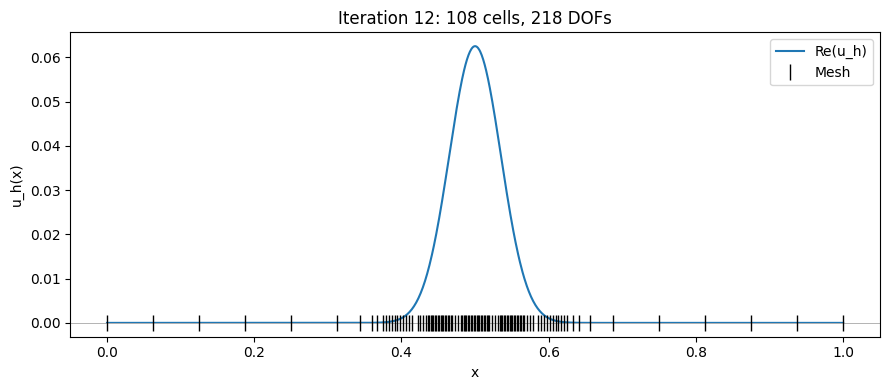



Iteration 12: 108 cells, 218 DOFs
L2 error = 5.557307e-08
H1 error = 7.896245e-06
H2 error = 5.715932e-03
Boundary norms: value=1.565e-14, slope=1.288e-13; PASS (tolerance 1.0e-10)
DWR estimate: (3.235776882565803e-05-5.8375706986354874e-27j)
True goal error: (3.267181877220082e-05-5.793868470979317e-27j)
Their absolute difference: 3.140499465427893e-07
Saved: biharmonic_snapshots/iteration_13.npz and biharmonic_snapshots/iteration_13.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     3.235775671492e-05
Sum of dual refinement indicators:       3.235775671492e-05
Sum of refinement indicators:            3.235775693448e-05
Effectivity index:                       0.990387742148
Localisation efficiency:                 0.990387378189
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 13] --------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 1.605900045656e+02 true resid norm 1.605900045656e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 7.391336520869e-13 true resid norm 7.414481933740e-13 ||r(i)||/||b|| 4.617025794225e-15
Checking boundary value squared: (5.87343754129197e-30+0j)
Checking boundary derivative squared: (1.1984897257951942e-26+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 350) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 8.438294643627e+02 true resid norm 8.438294643627e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 8.810309487743e-06 true resid norm 8.842900614012e-06 ||r(i)||/||b|| 1.047948784378e-08
    2 KSP unpreconditioned resid norm 1.569508127242e-12 true resid norm 1.406176753390e-06 ||r(i)||/||b|| 1.666422912184e-09
Computed goal J(uh):                    121.059704594051+0.000000000000j
Exact goal J(u): 

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


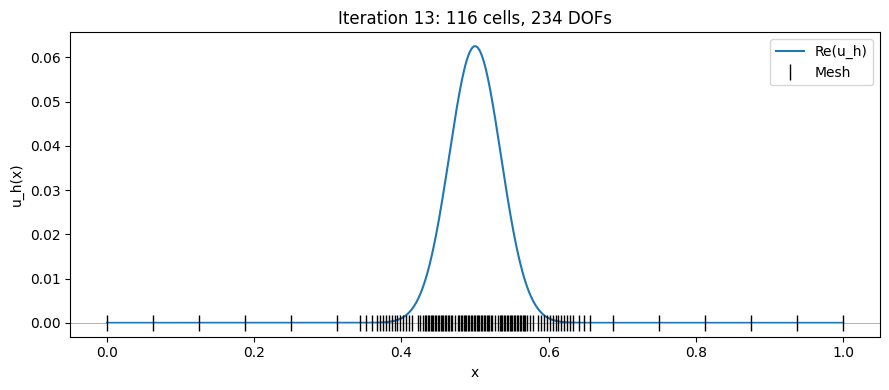



Iteration 13: 116 cells, 234 DOFs
L2 error = 5.155921e-08
H1 error = 6.130060e-06
H2 error = 4.763761e-03
Boundary norms: value=2.424e-15, slope=1.095e-13; PASS (tolerance 1.0e-10)
DWR estimate: (2.2443362137299845e-05-2.7689017773257514e-27j)
True goal error: (2.269337971938512e-05-2.7236127462989636e-27j)
Their absolute difference: 2.5001758208527565e-07
Saved: biharmonic_snapshots/iteration_14.npz and biharmonic_snapshots/iteration_14.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     2.244334983039e-05
Sum of dual refinement indicators:       2.244334983039e-05
Sum of refinement indicators:            2.263748823469e-05
Effectivity index:                       0.988982796517
Localisation efficiency:                 0.997537101772
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 14] -----

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 5.521157566319e+02 true resid norm 5.521157566319e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 2.627509012243e-12 true resid norm 2.635409111458e-12 ||r(i)||/||b|| 4.773290890184e-15
Checking boundary value squared: (1.2201759234810404e-28+0j)
Checking boundary derivative squared: (1.5642194592545005e-25+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 404) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 7.448976459952e+02 true resid norm 7.448976459952e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 3.952064715706e-05 true resid norm 3.903430515351e-05 ||r(i)||/||b|| 5.240223990957e-08
    2 KSP unpreconditioned resid norm 4.342269115159e-11 true resid norm 1.070599463363e-05 ||r(i)||/||b|| 1.437243719481e-08
Computed goal J(uh):                    121.059713835852-0.000000000000j
Exact goal J(u)

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


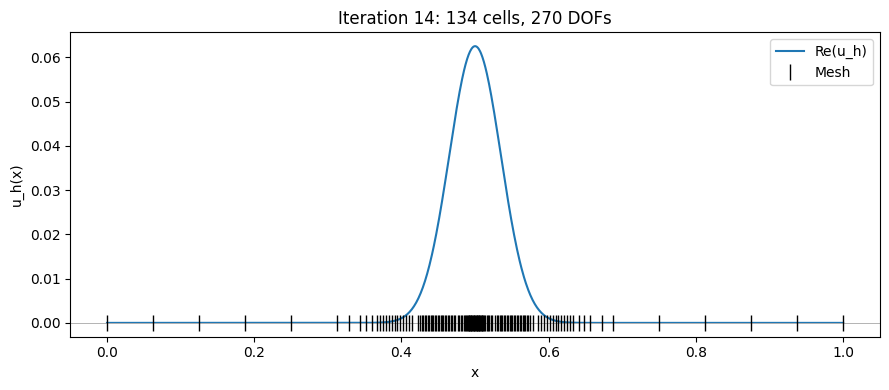



Iteration 14: 134 cells, 270 DOFs
L2 error = 8.238740e-09
H1 error = 2.194654e-06
H2 error = 3.667639e-03
Boundary norms: value=1.105e-14, slope=3.955e-13; PASS (tolerance 1.0e-10)
DWR estimate: (1.332201620397152e-05+2.9459221644573465e-26j)
True goal error: (1.3451578610101933e-05+2.946507303955936e-26j)
Their absolute difference: 1.295624061304132e-07
Saved: biharmonic_snapshots/iteration_15.npz and biharmonic_snapshots/iteration_15.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.332197491669e-05
Sum of dual refinement indicators:       1.332197491669e-05
Sum of refinement indicators:            2.847979673115e-05
Effectivity index:                       0.990368237819
Localisation efficiency:                 2.117208511851
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 15] -------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Checking boundary value squared: (3.0633584556128954e-29+0j)
Checking boundary derivative squared: (1.5921513688807629e-27+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 416) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 7.320361315816e+02 true resid norm 7.320361315816e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 1.102851115042e-04 true resid norm 1.037178924214e-04 ||r(i)||/||b|| 1.416841163254e-07
    2 KSP unpreconditioned resid norm 1.013524397471e-09 true resid norm 5.830268340150e-05 ||r(i)||/||b|| 7.964454333086e-08
    3 KSP unpreconditioned resid norm 6.089035732084e-14 true resid norm 5.242313384349e-05 ||r(i)||/||b|| 7.161276825261e-08
Computed goal J(uh):                    121.059714414286+0.000000000000j
Exact goal J(u):                         121.059727287431-0.000000000000j
True error, J(u) - J(u_h):               1.287314508147e-05-8.782076009352e-27j
Primal error, rho(u_h; z-

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


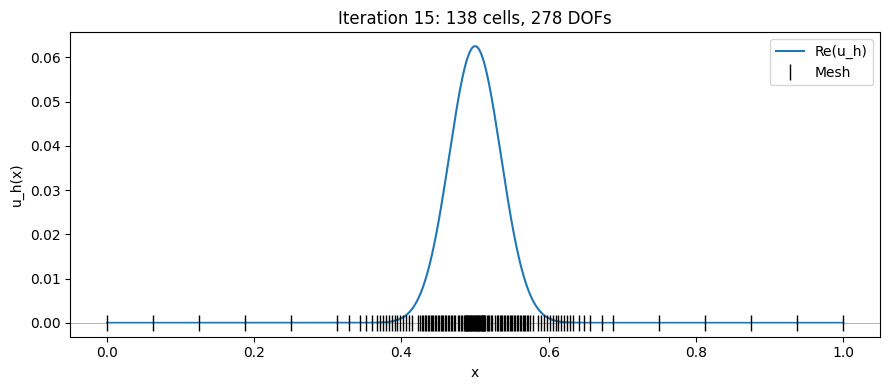



Iteration 15: 138 cells, 278 DOFs
L2 error = 8.237540e-09
H1 error = 2.182389e-06
H2 error = 3.587917e-03
Boundary norms: value=5.535e-15, slope=3.990e-14; PASS (tolerance 1.0e-10)
DWR estimate: (1.2743659147116978e-05-8.803687702266492e-27j)
True goal error: (1.2873145081471193e-05-8.78207600935154e-27j)
Their absolute difference: 1.2948593435421584e-07
Saved: biharmonic_snapshots/iteration_16.npz and biharmonic_snapshots/iteration_16.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.274361328065e-05
Sum of dual refinement indicators:       1.274361328065e-05
Sum of refinement indicators:            2.725422961708e-05
Effectivity index:                       0.989941390893
Localisation efficiency:                 2.117138387286
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 16] -------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 1.585326227488e+02 true resid norm 1.585326227488e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 3.255770473162e-12 true resid norm 3.256008211711e-12 ||r(i)||/||b|| 2.053841130775e-14
Checking boundary value squared: (3.7352374662457733e-31+0j)
Checking boundary derivative squared: (1.4372628102428925e-27+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 428) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 7.220647961587e+02 true resid norm 7.220647961587e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 1.723163026777e-04 true resid norm 1.515008342218e-04 ||r(i)||/||b|| 2.098161204199e-07
    2 KSP unpreconditioned resid norm 4.508872549423e-09 true resid norm 5.747579297313e-05 ||r(i)||/||b|| 7.959921779720e-08
    3 KSP unpreconditioned resid norm 1.444383723039e-14 true resid norm 4.529575271554e

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


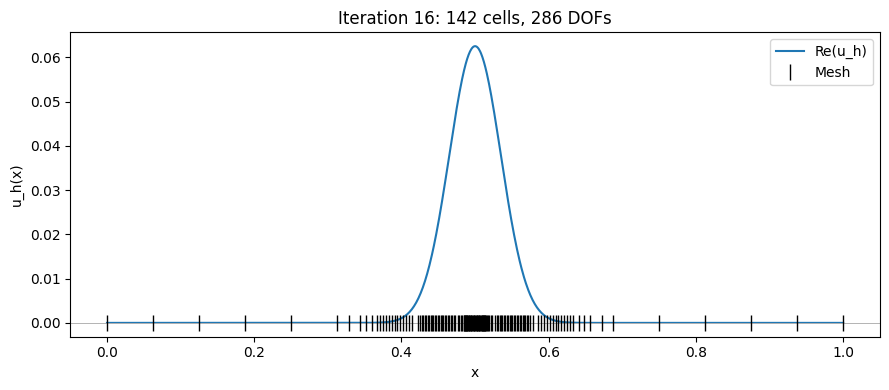



Iteration 16: 142 cells, 286 DOFs
L2 error = 8.236912e-09
H1 error = 2.173065e-06
H2 error = 3.526337e-03
Boundary norms: value=6.112e-16, slope=3.791e-14; PASS (tolerance 1.0e-10)
DWR estimate: (1.2305671832665366e-05+3.0169196459272375e-26j)
True goal error: (1.2435055623427616e-05+3.0219215026928576e-26j)
Their absolute difference: 1.2938379076224902e-07
Saved: biharmonic_snapshots/iteration_17.npz and biharmonic_snapshots/iteration_17.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.230559543261e-05
Sum of dual refinement indicators:       1.230559543261e-05
Sum of refinement indicators:            7.385161285714e-05
Effectivity index:                       0.989595238278
Localisation efficiency:                 5.938985324521
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 17] ----

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 1.931577409409e+02 true resid norm 1.931577409409e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 3.947700152270e-12 true resid norm 3.949086095430e-12 ||r(i)||/||b|| 2.044487617319e-14
Checking boundary value squared: (5.628797787069598e-29+0j)
Checking boundary derivative squared: (7.093224346401719e-27+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 464) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 7.075502766354e+02 true resid norm 7.075502766354e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 9.161584377879e-04 true resid norm 9.064772866590e-04 ||r(i)||/||b|| 1.281148939648e-06
    2 KSP unpreconditioned resid norm 4.004993084018e-08 true resid norm 3.897092272973e-04 ||r(i)||/||b|| 5.507866227548e-07
    3 KSP unpreconditioned resid norm 2.586778258810e-12 true resid norm 2.874891212960e-0

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


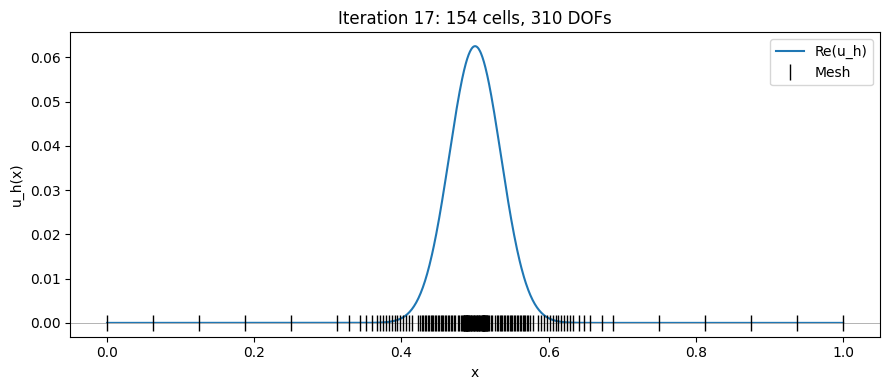



Iteration 17: 154 cells, 310 DOFs
L2 error = 8.236421e-09
H1 error = 2.166259e-06
H2 error = 3.476203e-03
Boundary norms: value=7.503e-15, slope=8.422e-14; PASS (tolerance 1.0e-10)
DWR estimate: (1.195474848656277e-05+4.550149701314796e-26j)
True goal error: (1.2083989759048563e-05+4.5709308527899566e-26j)
Their absolute difference: 1.292412724857939e-07
Saved: biharmonic_snapshots/iteration_18.npz and biharmonic_snapshots/iteration_18.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.195461566413e-05
Sum of dual refinement indicators:       1.195461566413e-05
Sum of refinement indicators:            5.242309945133e-04
Effectivity index:                       0.989304751571
Localisation efficiency:                 43.382277291383
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 18] ------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 1.686712317539e+02 true resid norm 1.686712317539e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 1.347174423429e-12 true resid norm 1.345996730726e-12 ||r(i)||/||b|| 7.980001786492e-15
Checking boundary value squared: (2.3203597255249814e-30+0j)
Checking boundary derivative squared: (7.131573436259198e-27+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 497) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 6.959503796404e+02 true resid norm 6.959503796404e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 2.094260022668e-03 true resid norm 2.215605309439e-03 ||r(i)||/||b|| 3.183567929921e-06
    2 KSP unpreconditioned resid norm 4.122527117313e-08 true resid norm 4.668614947546e-04 ||r(i)||/||b|| 6.708258353071e-07
    3 KSP unpreconditioned resid norm 4.144056104912e-12 true resid norm 6.119315608928e-

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


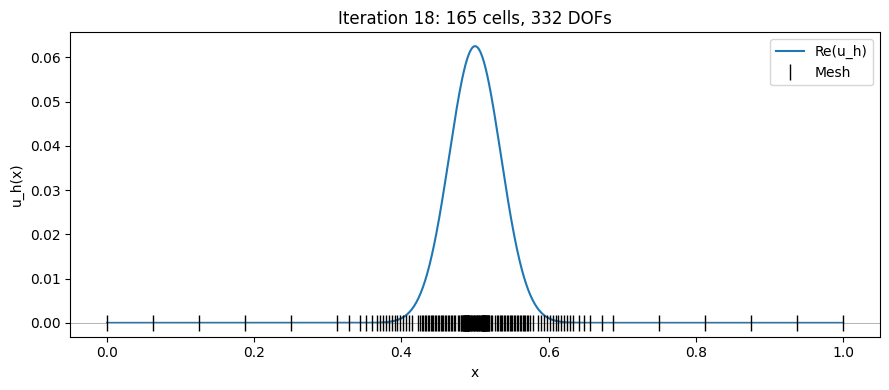



Iteration 18: 165 cells, 332 DOFs
L2 error = 8.236097e-09
H1 error = 2.161853e-06
H2 error = 3.442023e-03
Boundary norms: value=1.523e-15, slope=8.445e-14; PASS (tolerance 1.0e-10)
DWR estimate: (1.1718423812593485e-05+5.270695252143668e-26j)
True goal error: (1.1847525939856496e-05+5.27255047107002e-26j)
Their absolute difference: 1.291021272630113e-07
Saved: biharmonic_snapshots/iteration_19.npz and biharmonic_snapshots/iteration_19.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     1.171824807169e-05
Sum of dual refinement indicators:       1.171824807169e-05
Sum of refinement indicators:            1.030723973893e-03
Effectivity index:                       0.989103030631
Localisation efficiency:                 86.999089862800
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 19] -------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 1.642801405576e+02 true resid norm 1.642801405576e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 3.550808259012e-12 true resid norm 3.552115436579e-12 ||r(i)||/||b|| 2.162230580350e-14
Checking boundary value squared: (4.653263666440746e-31+0j)
Checking boundary derivative squared: (2.5674551920326357e-26+0j)
Solving primal with higher order for error estimate (degree: 4, dofs: 545) ...
    Residual norms for primal_ solve.
    0 KSP unpreconditioned resid norm 6.847373014411e+02 true resid norm 6.847373014411e+02 ||r(i)||/||b|| 1.000000000000e+00
    1 KSP unpreconditioned resid norm 2.622248746668e-03 true resid norm 2.728171165714e-03 ||r(i)||/||b|| 3.984259598495e-06
    2 KSP unpreconditioned resid norm 6.348111282954e-07 true resid norm 5.877967315500e-04 ||r(i)||/||b|| 8.584266262593e-07
    3 KSP unpreconditioned resid norm 8.993840299799e-11 true resid norm 8.095347515869e-

/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


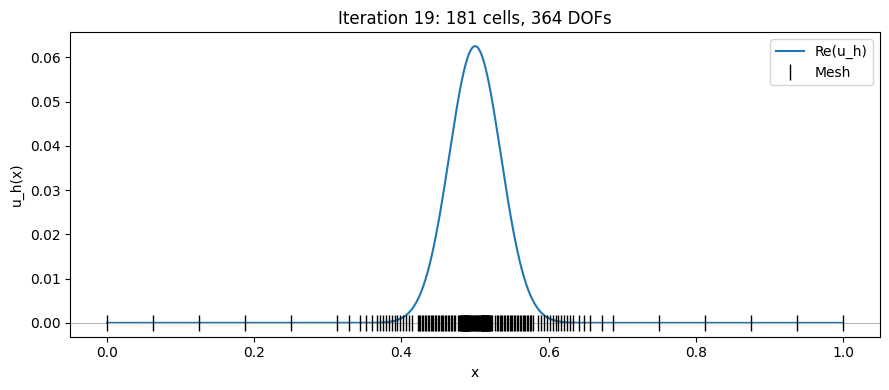



Iteration 19: 181 cells, 364 DOFs
L2 error = 8.226271e-09
H1 error = 2.130446e-06
H2 error = 3.372823e-03
Boundary norms: value=6.821e-16, slope=1.602e-13; PASS (tolerance 1.0e-10)
DWR estimate: (1.1248631684317255e-05+6.172047722449196e-26j)
True goal error: (1.1375942449376453e-05+6.172635215695801e-26j)
Their absolute difference: 1.2731076505919788e-07
Saved: biharmonic_snapshots/iteration_20.npz and biharmonic_snapshots/iteration_20.png

Maximum iteration (20) reached. Exiting.


In [67]:
from firedrake import *

# ------------------------------------------------------------
# 1. Initial mesh and Hermite approximation space
# ------------------------------------------------------------
mesh = UnitIntervalMesh(16)
V = FunctionSpace(mesh, "Hermite", 3)

uh = Function(V, name="uh")
v = TestFunction(V)
x = SpatialCoordinate(mesh)[0]

# ------------------------------------------------------------
# 2. Manufactured solution and corresponding forcing
# ------------------------------------------------------------
# Start with a reasonably resolved bump for the first test.
width = Constant(0.05)
u_exact = x**2 * (1 - x)**2 * exp(-((x - 0.5) / width)**2)
# The PDE is u'''' = f.
f = u_exact.dx(0).dx(0).dx(0).dx(0)

# x = SpatialCoordinate(mesh)[0]
# u_exact = x**2 * (1 - x)**2 * (1 + 10*x**3)
# f = 8400*x**3 - 7200*x**2 + 1200*x + 24

# ------------------------------------------------------------
# 3. Clamped conditions: u = u' = 0 at both endpoints
# ------------------------------------------------------------
bc = DirichletBC(V, 0, "on_boundary")
bc.nodes = V.boundary_nodes("on_boundary")

# ------------------------------------------------------------
# 4. Primal residual and self-dual goal
# ------------------------------------------------------------

F = (inner(uh.dx(0).dx(0), v.dx(0).dx(0)) - inner(f, v)) * dx

# With this Hermitian operator, this goal gives z = u.
J = inner(uh, f) * dx

problem = NonlinearVariationalProblem(
    F,
    uh,
    bcs=[bc],
)

# ------------------------------------------------------------
# 5. Plot and save after each solve
# ------------------------------------------------------------
callback = make_post_iteration_callback(
    output_dir="biharmonic_snapshots",
    npoints=1001,
    bc_tol=1e-10,
    show=True,
)

# ------------------------------------------------------------
# 6. Adaptive options
# ------------------------------------------------------------
solver_parameters = {
    "goal_adaptive": {
        "dual_is_primal": True,
        "biharmonic_1D": True,
        "use_adjoint_residual": True,

        # Independently solve the base and enriched primal problems.
        "primal_low_method": "solve", # use u_high - uh as our weight
        "primal_extra_degree": 1,

        "dorfler_alpha": 0.5,
        "max_it": 20,
        "max_dofs": None,

        # For this diagnostic test, stop at max_it rather than tolerance.
        "tolerance": 0.0,
        "verbose": True,
    },
    "snes_type": "ksponly",
    # "ksp_type": "preonly",
    "pc_type": "svd",
    "ksp_type": "fgmres",
    "ksp_monitor_true_residual": None,
    "pc_factor_mat_solver_type": "mumps",
    "ksp_rtol": 1e-12,
    "ksp_atol": 1e-12
}

# ------------------------------------------------------------
# 7. Run
# ------------------------------------------------------------
adaptive_solver = GoalAdaptiveNonlinearVariationalSolver(
    problem,
    J,
    exact_solution=u_exact,
    solver_parameters=solver_parameters,
    post_iteration_callback=callback,
)

solution = adaptive_solver.solve()

## Looking at Errors

<IPython.core.display.Math object>

Local slopes:
[-7.65182267e+00 -7.32817168e-01 -2.25856274e+01 -2.19914233e-01
 -9.13465858e-01 -1.28986095e+01 -5.90485756e+00 -3.36034853e+00
 -6.88315111e+00 -2.99664902e+00 -2.37717372e-01 -1.27838584e-01
 -1.05848123e+00 -1.28153221e+01 -4.98692069e-03 -2.68766410e-03
 -7.39892307e-04 -5.73938675e-04 -1.29731296e-02]



<IPython.core.display.Math object>

Local slopes:
[ -6.81612011  -1.95650155 -16.90402455  -1.25536021  -2.45166251
  -7.09772503  -3.76742439  -3.75528993  -7.15214218  -3.23793864
  -1.52878982  -1.471681    -3.57471249  -7.17801697  -0.19192614
  -0.15091197  -0.03893241  -0.02968885  -0.15903947]



<IPython.core.display.Math object>

Local slopes:
[-4.05832035 -3.73703605 -6.6496696  -2.91821692 -3.18157099 -2.31062433
 -2.32755352 -3.26843715 -3.61245215 -1.95801799 -2.11831179 -3.1161268
 -2.57278133 -1.82730755 -0.75263447 -0.61021257 -0.17770067 -0.14411944
 -0.22070735]



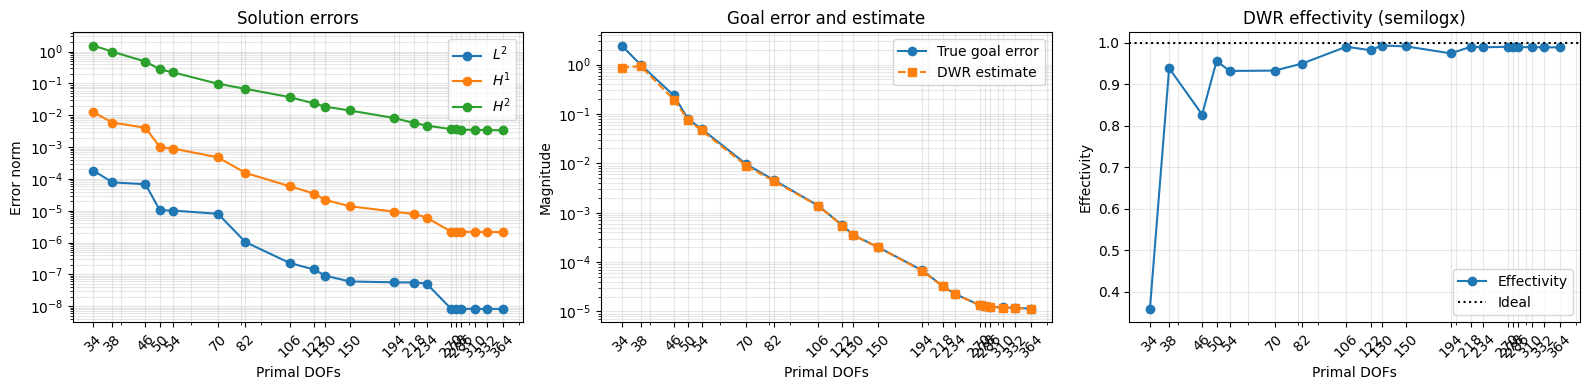

In [68]:
from IPython.display import display, Math

# Each snapshot contains errors and DOFs from the same solved mesh.
snapshots = adaptive_solver.snapshots
dofs = np.array([s["dofs"] for s in snapshots])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Solution errors: logarithmic axes make convergence easier to see.
for key, label in [
    ("L2_error", r"$L^2$"),
    ("H1_error", r"$H^1$"),
    ("H2_error", r"$H^2$"),
]:
    errors = np.array([s[key] for s in snapshots])

    # approximate the slope
    slope, intercept = np.polyfit(np.log(dofs), np.log(errors), 1)
    display(Math(rf"{label.strip('$')}: \quad \mathrm{{slope}} = {slope:.3f}"))

    local_slopes = np.diff(np.log(errors)) / np.diff(np.log(dofs))
    print('Local slopes:')
    print(local_slopes)
    print()

    axes[0].loglog(dofs, errors, "o-", label=label)


axes[0].set(xlabel="Primal DOFs", ylabel="Error norm",
            title="Solution errors")

# Compare the true goal error with its DWR estimate.
# Magnitudes allow complex-valued quantities to appear on logarithmic axes.
goal_errors = np.abs([s["true_goal_error"] for s in snapshots])
estimates = np.abs([s["goal_estimate"] for s in snapshots])

axes[1].loglog(dofs, goal_errors, "o-", label="True goal error")
axes[1].loglog(dofs, estimates, "s--", label="DWR estimate")
axes[1].set(xlabel="Primal DOFs", ylabel="Magnitude",
            title="Goal error and estimate")


# Effectivity: estimated error magnitude / true error magnitude.
effectivity = np.divide(estimates, goal_errors, out=np.full_like(goal_errors, np.nan), where=goal_errors > 0)
axes[2].semilogx(dofs, effectivity, "o-", label="Effectivity")
axes[2].axhline(1, color="black", linestyle=":", label="Ideal")
axes[2].set(
    xlabel="Primal DOFs",
    ylabel="Effectivity",
    title="DWR effectivity (semilogx)",)


for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    ax.set_xticks(dofs)
    ax.set_xticklabels([str(n) for n in dofs])
    ax.tick_params(axis="x", which="both", labelrotation=45)

fig.tight_layout()
fig.savefig("biharmonic_convergence.png", dpi=200)
plt.show()

## Compare to Uniform Refinement


---------------------------- [MESH LEVEL 0] ----------------------------

Solving primal (degree: 3, dofs: 34) ...
Checking boundary value squared: 0j
Checking boundary derivative squared: 0j
Solving primal with higher order for error estimate (degree: 4, dofs: 50) ...
Computed goal J(uh):                    118.619150750798-0.000000000000j
Exact goal J(u):                         121.059727287451-0.000000000000j
True error, J(u) - J(u_h):               2.440576536653e+00+2.825405357695e-30j
Primal error, rho(u_h; z-z_h):           8.742557999245e-01-5.447007589525e-29j
Dual error,  rho*(z_h; u-u_h):           8.742557999245e-01+5.447007589525e-29j
Difference, primal-dual:                 1.089401517905e-28
Discretisation error, 0.5(rho + rho*)    8.742557999245e-01+0.000000000000e+00j
Solver error, rho(u_h; z_h):            -3.384555807535e-14-1.849572772124e-28j
Final error estimate:                    8.742557999245e-01-1.849572772124e-28j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


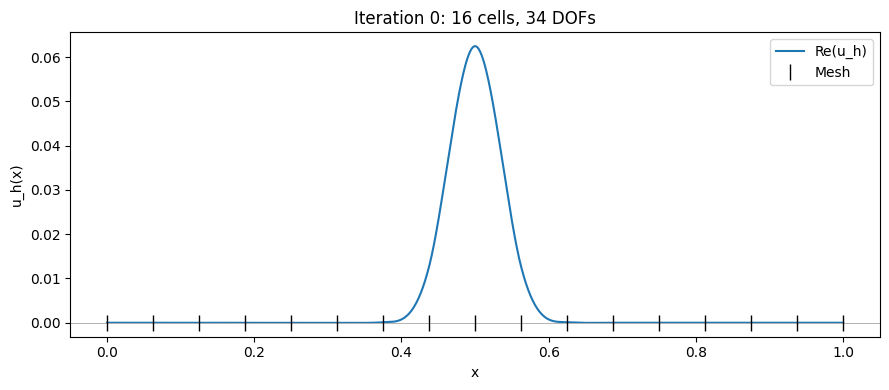



Iteration 0: 16 cells, 34 DOFs
L2 error = 1.829946e-04
H1 error = 1.259779e-02
H2 error = 1.562285e+00
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.8742557999245049-1.849572772124312e-28j)
True goal error: (2.440576536652557+2.8254053576950298e-30j)
Their absolute difference: 1.5663207367280523
Saved: uniform_snapshots/iteration_01.npz and uniform_snapshots/iteration_01.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     8.742557990145e-01
Sum of dual refinement indicators:       8.742557990145e-01
Sum of refinement indicators:            8.742557990145e-01
Effectivity index:                       0.358216915878
Localisation efficiency:                 0.358216915505
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 1] ----------------------------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Checking boundary value squared: 0j
Checking boundary derivative squared: 0j
Solving primal with higher order for error estimate (degree: 4, dofs: 98) ...
Computed goal J(uh):                    120.231195798545+0.000000000000j
Exact goal J(u):                         121.059727287431+0.000000000000j
True error, J(u) - J(u_h):               8.285314888857e-01-2.722168404882e-29j
Primal error, rho(u_h; z-z_h):           8.057784189779e-01-8.023548345345e-29j
Dual error,  rho*(z_h; u-u_h):           8.057784189779e-01+8.023548345345e-29j
Difference, primal-dual:                 1.604709669069e-28
Discretisation error, 0.5(rho + rho*)    8.057784189779e-01+0.000000000000e+00j
Solver error, rho(u_h; z_h):             2.988791131655e-14-2.748563563285e-29j
Final error estimate:                    8.057784189780e-01-2.748563563285e-29j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


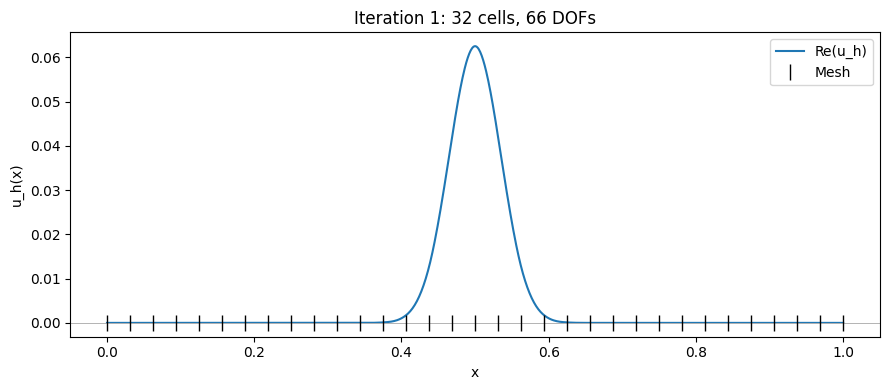



Iteration 1: 32 cells, 66 DOFs
L2 error = 3.917513e-05
H1 error = 4.374662e-03
H2 error = 9.102476e-01
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.8057784189779797-2.7485635632847434e-29j)
True goal error: (0.828531488885659-2.72216840488241e-29j)
Their absolute difference: 0.022753069907679224
Saved: uniform_snapshots/iteration_02.npz and uniform_snapshots/iteration_02.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     8.057784189779e-01
Sum of dual refinement indicators:       8.057784189779e-01
Sum of refinement indicators:            8.057784189779e-01
Effectivity index:                       0.972538074638
Localisation efficiency:                 0.972538074638
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 2] ---------------------------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Computed goal J(uh):                    121.002821580782+0.000000000000j
Exact goal J(u):                         121.059727287431-0.000000000000j
True error, J(u) - J(u_h):               5.690570664908e-02-4.432582026640e-28j
Primal error, rho(u_h; z-z_h):           5.654157992765e-02+9.193625079566e-29j
Dual error,  rho*(z_h; u-u_h):           5.654157992765e-02-9.193625079566e-29j
Difference, primal-dual:                 1.838725015913e-28
Discretisation error, 0.5(rho + rho*)    5.654157992765e-02+0.000000000000e+00j
Solver error, rho(u_h; z_h):             2.955323215258e-14-2.024415949152e-28j
Final error estimate:                    5.654157992768e-02-2.024415949152e-28j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


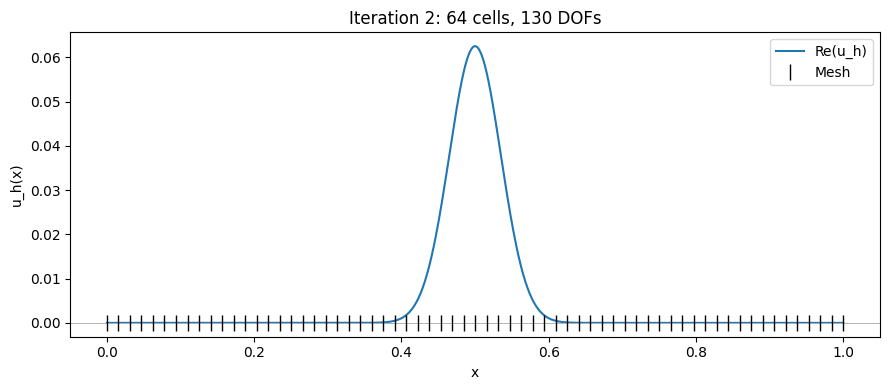



Iteration 2: 64 cells, 130 DOFs
L2 error = 2.587943e-06
H1 error = 5.747738e-04
H2 error = 2.385499e-01
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.056541579927681045-2.024415949152055e-28j)
True goal error: (0.05690570664907568-4.432582026640122e-28j)
Their absolute difference: 0.0003641267213946378
Saved: uniform_snapshots/iteration_03.npz and uniform_snapshots/iteration_03.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     5.654157992753e-02
Sum of dual refinement indicators:       5.654157992753e-02
Sum of refinement indicators:            5.654157992753e-02
Effectivity index:                       0.993601226611
Localisation efficiency:                 0.993601226608
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 3] ---------------------

/usr/local/lib/python3.13/dist-packages/firedrake/dmhooks.py:275: RuntimeWarning: Creating new TransferManager to transfer data to coarse grids. This might be slow (you probably want to save it on an appctx)
  warnings.warn("Creating new TransferManager to transfer data to coarse grids. "


Computed goal J(uh):                    121.056101923113-0.000000000000j
Exact goal J(u):                         121.059727287431-0.000000000000j
True error, J(u) - J(u_h):               3.625364317756e-03+1.147498512824e-27j
Primal error, rho(u_h; z-z_h):           3.619562695899e-03+4.395035323468e-27j
Dual error,  rho*(z_h; u-u_h):           3.619562695899e-03-4.395035323468e-27j
Difference, primal-dual:                 8.790070646936e-27
Discretisation error, 0.5(rho + rho*)    3.619562695899e-03+0.000000000000e+00j
Solver error, rho(u_h; z_h):             3.522439968824e-13+1.140620335043e-27j
Final error estimate:                    3.619562696251e-03+1.140620335043e-27j


/usr/local/lib/python3.13/dist-packages/firedrake/mesh.py:3699: ComplexWarning: Casting complex values to real discards the imaginary part
  vertexcoords = np.asarray(vertexcoords, dtype=RealType)


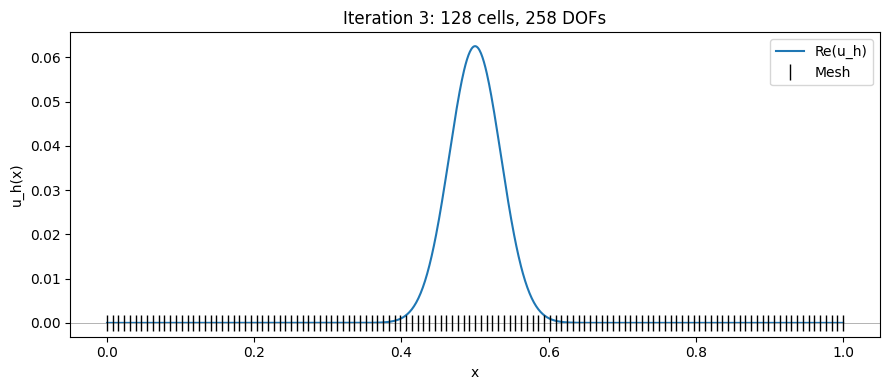



Iteration 3: 128 cells, 258 DOFs
L2 error = 1.635985e-07
H1 error = 7.257259e-05
H2 error = 6.021104e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.0036195626962512457+1.1406203350434918e-27j)
True goal error: (0.0036253643177559525+1.1474985128244561e-27j)
Their absolute difference: 5.801621504706797e-06
Saved: uniform_snapshots/iteration_04.npz and uniform_snapshots/iteration_04.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     3.619562694714e-03
Sum of dual refinement indicators:       3.619562694714e-03
Sum of refinement indicators:            3.619562694714e-03
Effectivity index:                       0.998399713519
Localisation efficiency:                 0.998399713095
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 4] ---------------

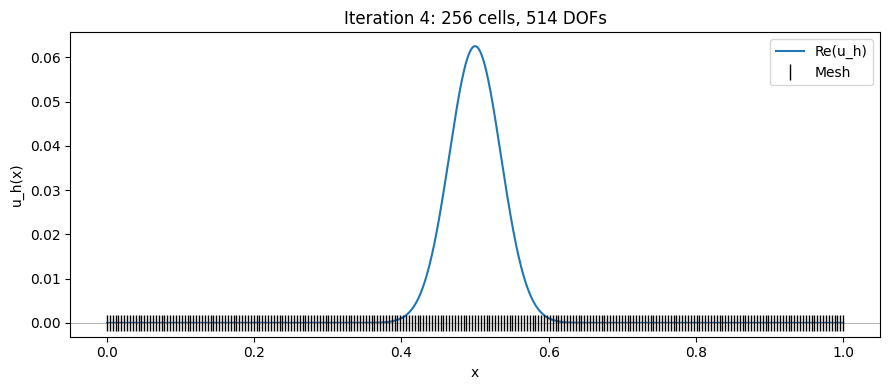



Iteration 4: 256 cells, 514 DOFs
L2 error = 1.025409e-08
H1 error = 9.094440e-06
H2 error = 1.508891e-02
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (0.00022758390378463234+5.171461409079792e-28j)
True goal error: (0.00022767499602593944+3.0954436750389917e-28j)
Their absolute difference: 9.109224130709093e-08
Saved: uniform_snapshots/iteration_05.npz and uniform_snapshots/iteration_05.png

Computing local refinement indicators eta_K ...
Sum of primal refinement indicators:     2.275839020050e-04
Sum of dual refinement indicators:       2.275839020050e-04
Sum of refinement indicators:            2.275839020050e-04
Effectivity index:                       0.999599902304
Localisation efficiency:                 0.999599894488
Maximum imaginary part of cell markers is: 0.000e+00
Do not worry about the throwing out imaginary part warning to follow:
Transferring problem to new mesh ...

---------------------------- [MESH LEVEL 5] --------------

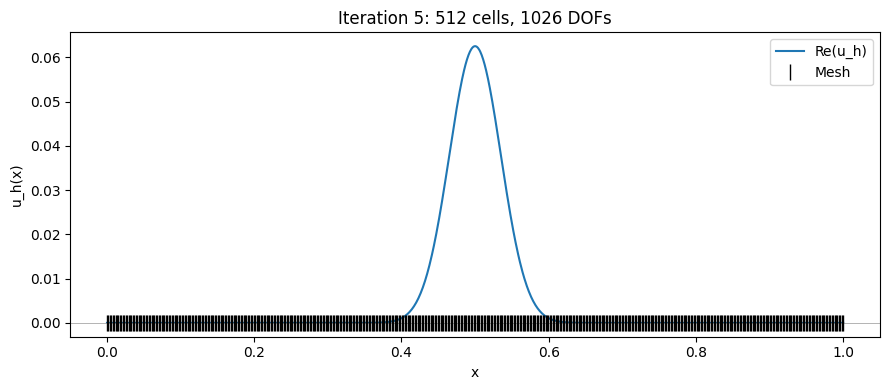



Iteration 5: 512 cells, 1026 DOFs
L2 error = 6.413377e-10
H1 error = 1.137521e-06
H2 error = 3.774490e-03
Boundary norms: value=0.000e+00, slope=0.000e+00; PASS (tolerance 1.0e-10)
DWR estimate: (1.4245364265085067e-05-3.324751360714791e-27j)
True goal error: (1.4246773545778524e-05-3.324568382597151e-27j)
Their absolute difference: 1.409280693456867e-09
Saved: uniform_snapshots/iteration_06.npz and uniform_snapshots/iteration_06.png

Maximum iteration (6) reached. Exiting.


In [62]:
# Only change marking: refine every cell for uniform refinement
class UniformGoalAdaptiveSolver(GoalAdaptiveNonlinearVariationalSolver):
    def set_adaptive_cell_markers(self, eta_cell):
        markers = Function(eta_cell.function_space())
        markers.assign(1)
        return markers


# ------------------------------------------------------------
# 1. Fresh initial mesh and cubic Hermite space
# ------------------------------------------------------------
mesh_uniform = UnitIntervalMesh(16)
V_uniform = FunctionSpace(mesh_uniform, "Hermite", 3)

uh_uniform = Function(V_uniform, name="uniform_primal")
v_uniform = TestFunction(V_uniform)
x_uniform = SpatialCoordinate(mesh_uniform)[0]


# ------------------------------------------------------------
# 2. Same manufactured solution and forcing as the adaptive run
# ------------------------------------------------------------
width_uniform = 0.05  # Must match your adaptive test.

u_exact_uniform = (
    x_uniform**2
    * (1 - x_uniform)**2
    * exp(-((x_uniform - 0.5) / width_uniform)**2)
)

f_uniform = u_exact_uniform.dx(0).dx(0).dx(0).dx(0)



# ------------------------------------------------------------
# 3. Homogeneous clamped boundary conditions: u = u' = 0
# ------------------------------------------------------------
bc_uniform = DirichletBC(V_uniform, 0, "on_boundary")
bc_uniform.nodes = V_uniform.boundary_nodes("on_boundary")


# ------------------------------------------------------------
# 4. Primal residual and self-dual goal
# ------------------------------------------------------------
F_uniform = (inner(uh_uniform.dx(0).dx(0), v_uniform.dx(0).dx(0)) - inner(f_uniform, v_uniform)) * dx
J_uniform = inner(uh_uniform, f_uniform) * dx

problem_uniform = NonlinearVariationalProblem(
    F_uniform,
    uh_uniform,
    bcs=[bc_uniform],
)


# ------------------------------------------------------------
# 5. Reuse the adaptive run's estimator options
# ------------------------------------------------------------

uniform_parameters = {
    "snes_type": "ksponly",
    "ksp_type": "preonly",
    "pc_type": "lu",
    "goal_adaptive": {
        "max_it": 6,
        "max_dofs": None,
        "tolerance": 0.0,
        "primal_low_method": "solve",
        "primal_extra_degree": 1,
        "dual_is_primal": True,
        "use_adjoint_residual": True,
        "biharmonic_1D": True,
    },
}

# ------------------------------------------------------------
# 6. Plot and save each uniform solution using your callback
# ------------------------------------------------------------
uniform_callback = make_post_iteration_callback(
    output_dir="uniform_snapshots",
    show=True,
)

uniform_solver = UniformGoalAdaptiveSolver(
    problem_uniform,
    J_uniform,
    solver_parameters=uniform_parameters,
    options_prefix="uniform_",
    exact_solution=u_exact_uniform,
    post_iteration_callback=uniform_callback,
)


# ------------------------------------------------------------
# 7. Run
# ------------------------------------------------------------
uniform_solution = uniform_solver.solve()

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Local slopes:
[-7.65182267e+00 -7.32817168e-01 -2.25856274e+01 -2.19914230e-01
 -9.13465859e-01 -1.28986094e+01 -5.90485773e+00 -3.36034821e+00
 -6.88315012e+00 -2.99664485e+00 -2.37721274e-01 -1.27837381e-01
 -1.34486728e+00 -1.40978158e+01 -6.25043838e-03 -1.67969125e-03
 -1.60529721e-03 -8.71106486e-04 -1.63651521e-03]



<IPython.core.display.Math object>

<IPython.core.display.Math object>

Local slopes:
[-2.32387774 -4.00834969 -4.02845383 -4.01840167 -4.01023857]



... (8 outputs left out)

Local slopes:
[-4.05832035 -3.73703605 -6.6496696  -2.91821692 -3.18157099 -2.31062433
 -2.32755352 -3.26843715 -3.61245215 -1.95801799 -2.11831179 -3.1161268
 -2.216677   -2.08202255 -0.98065943 -0.33386328 -0.31076903 -0.2342597
 -0.1920139 ]



<IPython.core.display.Math object>

<IPython.core.display.Math object>

Local slopes:
[-0.81440225 -1.97548066 -2.00856743 -2.00778894 -2.00476694]



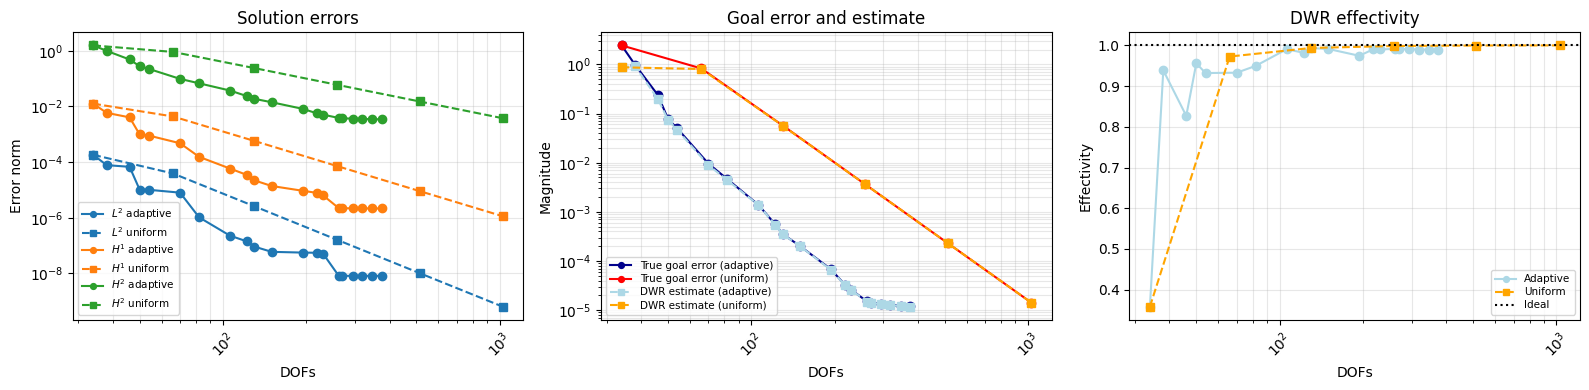

In [63]:
# Each snapshot contains errors and DOFs from the same solved mesh.
adaptive_snapshots = adaptive_solver.snapshots
adaptive_dofs = np.array([s["dofs"] for s in adaptive_snapshots])
uni_snapshots = uniform_solver.snapshots
uni_dofs = np.array([s["dofs"] for s in uni_snapshots])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Solution errors: logarithmic axes make convergence easier to see.
for key, label in [
    ("L2_error", r"$L^2$"),
    ("H1_error", r"$H^1$"),
    ("H2_error", r"$H^2$"),
]:
    adaptive_errors = np.array([s[key] for s in adaptive_snapshots])
    uni_errors = np.array([s[key] for s in uni_snapshots])

    # approximate the slopes (adaptive)
    adaptive_slope, intercept = np.polyfit(np.log(adaptive_dofs), np.log(adaptive_errors), 1)
    display(Math(rf"\text{{Adaptive }} {label.strip('$')} \text{{ results:}}"))
    display(Math(rf"{label.strip('$')}: \quad \mathrm{{slope}} = {adaptive_slope:.3f}"))
    local_slopes = np.diff(np.log(adaptive_errors)) / np.diff(np.log(adaptive_dofs))
    print('Local slopes:')
    print(local_slopes)
    print()

    # approximate the slopes (adaptive)
    uni_slope, intercept = np.polyfit(np.log(uni_dofs), np.log(uni_errors), 1)
    display(Math(rf"\text{{Uniform }} {label.strip('$')} \text{{ results:}}"))
    display(Math(rf"{label.strip('$')}: \quad \mathrm{{slope}} = {uni_slope:.3f}"))
    local_slopes = np.diff(np.log(uni_errors)) / np.diff(np.log(uni_dofs))
    print('Local slopes:')
    print(local_slopes)
    print()

    # plot the errors
    line, = axes[0].loglog(adaptive_dofs, adaptive_errors, "o-", label=f"{label} adaptive")
    axes[0].loglog(uni_dofs, uni_errors, "s--", color=line.get_color(),label=f"{label} uniform")



axes[0].set(xlabel="DOFs", ylabel="Error norm",
            title="Solution errors")

# Compare the true goal error with its DWR estimate.
adaptive_goal_errors = np.abs([s["true_goal_error"] for s in adaptive_snapshots])
uni_goal_errors = np.abs([s["true_goal_error"] for s in uni_snapshots])
adaptive_estimates = np.abs([s["goal_estimate"] for s in adaptive_snapshots])
uni_estimates = np.abs([s["goal_estimate"] for s in uni_snapshots])


axes[1].loglog(adaptive_dofs, adaptive_goal_errors, "o-",
               color="darkblue", label="True goal error (adaptive)")

axes[1].loglog(uni_dofs, uni_goal_errors, "o-",
               color="red", label="True goal error (uniform)")

axes[1].loglog(adaptive_dofs, adaptive_estimates, "s--",
               color="lightblue",
               label="DWR estimate (adaptive)")

axes[1].loglog(uni_dofs, uni_estimates, "s--",
               color="orange",
               label="DWR estimate (uniform)")

axes[1].set(xlabel="DOFs", ylabel="Magnitude",
            title="Goal error and estimate")

# Effectivity for each refinement method.
adaptive_effectivity = np.divide(adaptive_estimates, adaptive_goal_errors, out=np.full_like(adaptive_goal_errors, np.nan), where=adaptive_goal_errors > 0,)
uni_effectivity = np.divide(uni_estimates, uni_goal_errors, out=np.full_like(uni_goal_errors, np.nan), where=uni_goal_errors > 0,)
axes[2].semilogx(adaptive_dofs, adaptive_effectivity, "o-", color="lightblue", label="Adaptive")
axes[2].semilogx(uni_dofs, uni_effectivity, "s--", color="orange", label="Uniform",)
axes[2].axhline(1, color="black", linestyle=":", label="Ideal")
axes[2].set(xlabel="DOFs", ylabel="Effectivity", title="DWR effectivity",)
axes[2].legend(loc = 'lower right', fontsize=7.5, markerscale=0.7, labelspacing=0.3)
axes[2].grid(True, which="both", alpha=0.3)
axes[2].tick_params(axis="x", which="both", labelrotation=45)


for ax in axes[:-1]:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(loc = 'lower left', fontsize=7.5, markerscale=0.7, labelspacing=0.3)
    ax.tick_params(axis="x", which="both", labelrotation=45)

fig.tight_layout()
fig.savefig("biharmonic_convergence.png", dpi=200)
plt.show()